# DSCI 552 Homework 6

This notebook is self-contained: it imports no project modules and requires only the declared Python packages and the two raw APS CSV files for a **full** run. Paths are relative, and output directories are created automatically.

**Full training:** set `MODE="full"` below (or `DSCI552_MODE=full`). It creates a fresh run, fits both forests, performs both complete 7-alpha × 5-fold searches, and fits both final XGBoost models, a separate strictly-positive-alpha comparison and one OOB-safe supplemental forest. It reads no previous result or model cache.

**Quick check (default):** requires the separately supplied original `results/final_full_run/model_artifacts/` bundle and coverage-audit `results/oob_review/artifacts_v2/` sidecar. It verifies raw-data hashes, current implementation/configuration/package signatures and every artifact hash before loading models. It reproduces predictions on all original training/test rows, recomputes metrics/OOB and saved CV-score summaries/alpha selection, and regenerates plots/theory calculations. With default OOB_MODE="verify", it **does not fit any estimator**. The separate OOB_MODE="fit_supplement" explicitly trains only the supplemental forest; it is never a full APS rerun. Missing/mismatched caches raise explicit errors; no cache read is called retraining.

Only the submitted PDF is subject to the 20-page limit. The separately attached notebook/source pages are not added. The PDF contains necessary method/code/result evidence; the project source need not all be printed.

**XGBoost limitation:** binary logistic loss/link and L1 tree-leaf regularization do not create logistic regressions at nodes. No explanatory course FAQ/announcement was found among available local material; instructor confirmation remains needed. Standard gbtree results are retained.


In [1]:
from pathlib import Path
from datetime import datetime, timezone
import os, json, time, hashlib, shutil, platform, importlib.metadata
os.environ.setdefault("OMP_NUM_THREADS", "4")
os.environ.setdefault("OPENBLAS_NUM_THREADS", "4")
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (confusion_matrix, roc_auc_score, average_precision_score,
    precision_score, recall_score, f1_score, roc_curve, precision_recall_curve)
from sklearn.svm import SVC
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE
from xgboost import XGBClassifier
from joblib import dump, load
from matplotlib.patches import Rectangle, Circle
from IPython.display import display, Markdown, Image

# Edit here, or set the environment variables before launching the kernel.
MODE = os.environ.get("DSCI552_MODE", "quick").lower()  # "quick" or "full"
CACHE_DIR = Path(os.environ.get("DSCI552_CACHE_DIR", "results/final_full_run/model_artifacts"))
OOB_CACHE_DIR = Path(os.environ.get("DSCI552_OOB_CACHE_DIR", "results/oob_review/artifacts_v2"))
OOB_MODE = os.environ.get("DSCI552_OOB_MODE", "fit_supplement" if MODE == "full" else "verify")
ROOT = Path.cwd()
DATA_DIR = Path("Homework 6 Data")
assert MODE in {"quick", "full"}
assert (DATA_DIR / "aps_failure_training_set.csv").is_file(), "Run beside the raw data directory."
SEED = 552
MODEL_NAMES = ["rf_plain", "rf_balanced", "xgb_plain", "xgb_smote", "xgb_positive"]
CONFIG = dict(seed=SEED, threshold=.5, alphas=[0., .001, .01, .1, 1., 10., 100.],
    supplement="plain search restricted alpha > 0, same AP and smaller-alpha tie rule",
    features=170, cv_selection="mean average precision; smaller-alpha tie break",
    imputation=dict(strategy="median", keep_empty_features=True,
        main_test="test-own medians", sensitivity="train medians", cv="training-fold only"),
    rf=dict(n_estimators=500, criterion="gini", max_features="sqrt", bootstrap=True,
            oob_score=True, max_depth=None, min_samples_leaf=1, random_state=SEED, n_jobs=4),
    xgb=dict(booster="gbtree", objective="binary:logistic", reg_lambda=1,
        n_estimators=250, max_depth=4, learning_rate=.08, subsample=1,
        colsample_bytree=1, min_child_weight=1, tree_method="hist", max_bin=256,
        n_jobs=4, random_state=SEED, eval_metric="logloss", base_score=.5),
    smote=dict(random_state=SEED, k_neighbors=5, sampling_strategy=1.0),
    cv=dict(n_splits=5, shuffle=True, random_state=SEED))
RUN_ROOT = Path("results/notebook_runs") / (MODE + "_" + datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S_%fZ"))
R = RUN_ROOT
F = RUN_ROOT / "figures"
F.mkdir(parents=True, exist_ok=False)
print("Mode:", MODE, "| Output:", RUN_ROOT)
print("QUICK requires the separate matching cache bundle at", CACHE_DIR)
print("Missing cache? Select full mode to train using only the two raw CSVs.")
print("Full fits 2 forests + 70 CV estimators + 3 final XGBs + 1 OOB-safe supplemental forest.")
print("OOB_MODE:", OOB_MODE, "| separate matching OOB sidecar required for verify:", OOB_CACHE_DIR)


Mode: quick | Output: results/notebook_runs/quick_20261109T041949_112615Z
QUICK requires the separate matching cache bundle at results/final_full_run/model_artifacts
Missing cache? Select full mode to train using only the two raw CSVs.
Full fits 2 forests + 70 CV estimators + 3 final XGBs + 1 OOB-safe supplemental forest.
OOB_MODE: verify | separate matching OOB sidecar required for verify: results/oob_review/artifacts_v2


## Self-contained modeling, full-training and cache-validation logic

All 170 features enter every estimator. Fold-local preprocessing/resampling, AP-based alpha selection and the 0.5 classification rule match the original experiment. The code-cell fingerprint is part of cache compatibility; changing it invalidates the existing cache.

In [2]:
"""Source embedded directly in the notebook; no project module imports at runtime."""

def sha256_file(path):
    digest = hashlib.sha256()
    with Path(path).open('rb') as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b''):
            digest.update(block)
    return digest.hexdigest()

def read_json(path):
    return json.loads(Path(path).read_text())

def write_json(path, value):
    def clean(v):
        if isinstance(v, dict): return {str(k): clean(x) for k, x in v.items()}
        if isinstance(v, (list, tuple)): return [clean(x) for x in v]
        if isinstance(v, np.ndarray): return clean(v.tolist())
        if isinstance(v, np.generic): return clean(v.item())
        if isinstance(v, float) and not np.isfinite(v): return 'NaN missing sentinel'
        return v
    Path(path).write_text(json.dumps(clean(value), indent=2, allow_nan=False))

def load_data():
    pairs, audit = [], {}
    for split in ['training', 'test']:
        path = DATA_DIR / f'aps_failure_{split}_set.csv'
        with path.open() as stream:
            header = next(i for i, line in enumerate(stream) if line.startswith('class,'))
        frame = pd.read_csv(path, skiprows=header, na_values=['na'])
        assert frame['class'].isin(['neg', 'pos']).all()
        x = frame.drop(columns='class').astype(float)
        labels = frame['class'].map({'neg': 0, 'pos': 1}).to_numpy()
        audit[split] = dict(rows=len(x), features=x.shape[1],
            header_line_1based=header+1, dtype=str(x.dtypes.iloc[0]),
            counts=dict(neg=int((labels == 0).sum()), pos=int((labels == 1).sum())),
            missing_cells=int(x.isna().sum().sum()),
            all_missing_columns=x.columns[x.isna().all()].tolist(), sha256=sha256_file(path))
        pairs.append((x, labels))
    assert pairs[0][0].shape == (60000, 170) and pairs[1][0].shape == (16000, 170)
    assert pairs[0][0].columns.equals(pairs[1][0].columns)
    return *pairs, audit

def prepare(x, test):
    imputer = SimpleImputer(strategy='median', keep_empty_features=True)
    train = imputer.fit_transform(x)
    main_test = SimpleImputer(strategy='median', keep_empty_features=True).fit_transform(test)
    sensitivity_test = imputer.transform(test)
    assert train.shape[1] == 170 and np.isfinite(train).all()
    return imputer, train, main_test, sensitivity_test

def metrics(labels, probability):
    pred = (probability >= CONFIG['threshold']).astype(int)
    return dict(n=len(labels), error=float(np.mean(pred != labels)),
        auc=float(roc_auc_score(labels, probability)),
        average_precision=float(average_precision_score(labels, probability)),
        precision=float(precision_score(labels, pred, zero_division=0)),
        recall=float(recall_score(labels, pred)), f1=float(f1_score(labels, pred)),
        confusion_matrix=confusion_matrix(labels, pred, labels=[0, 1]).tolist())

def make_rf(balanced):
    return RandomForestClassifier(**CONFIG['rf'],
        class_weight='balanced' if balanced else None)

def xgb(alpha):
    return XGBClassifier(**CONFIG['xgb'], reg_alpha=float(alpha))

def fold_pipeline(alpha, smote):
    steps = [('imputer', SimpleImputer(strategy='median', keep_empty_features=True)),
             ('scaler', StandardScaler())]
    if smote:
        steps.append(('smote', SMOTE(**CONFIG['smote'])))
    return Pipeline(steps + [('estimator', xgb(alpha))])

def training_folds(x, labels):
    return list(StratifiedKFold(**CONFIG['cv']).split(x, labels))

def choose_alpha(frame):
    summary = frame.groupby('alpha').agg(mean_ap=('average_precision', 'mean'),
        sd_ap=('average_precision', 'std'), mean_error=('error', 'mean'),
        sd_error=('error', 'std'), mean_auc=('auc', 'mean'), seconds=('seconds', 'sum')).reset_index()
    best = float(summary.sort_values(['mean_ap', 'alpha'],
        ascending=[False, True]).iloc[0]['alpha'])
    return summary, best

def cache_signature():
    return dict(schema=2, data={s: sha256_file(DATA_DIR / f'aps_failure_{s}_set.csv')
        for s in ['training', 'test']}, config=CONFIG,
        model_code_sha256=hashlib.sha256(MODEL_CODE.strip().encode()).hexdigest(),
        versions={p: importlib.metadata.version(p) for p in
            ['numpy', 'pandas', 'scikit-learn', 'xgboost', 'imbalanced-learn', 'joblib']})

def validate_cache(directory, expected):
    directory = Path(directory)
    if not (directory / 'manifest.json').exists():
        raise FileNotFoundError(f'No validated cache at {directory}. Set MODE="full" '
            'to train from raw data, or supply the separately validated cache bundle.')
    manifest = read_json(directory / 'manifest.json')
    if manifest['signature'] != expected:
        raise ValueError('Cache does not match current raw data, parameters, code or '
                         'package versions. Select MODE="full" or the matching cache.')
    for file, digest in manifest['files'].items():
        if not (directory / file).is_file() or sha256_file(directory / file) != digest:
            raise ValueError(f'Missing or altered cached artifact: {file}')
    required = ['cv_folds.npz']
    for name in MODEL_NAMES:
        required += [f'{name}.joblib', f'{name}.json', f'{name}_predictions.npz']
    for name in ['xgb_plain', 'xgb_smote']:
        required += [f'{name}_cv_folds.csv', f'{name}_cv_summary.csv']
    if not set(required).issubset(manifest['files']):
        raise ValueError('Cache inventory is incomplete; use MODE="full".')
    return manifest

def seal_cache(directory, signature, provenance):
    files = {p.name: sha256_file(p) for p in Path(directory).iterdir()
             if p.suffix in ['.json', '.csv', '.npz', '.joblib'] and p.name != 'manifest.json'}
    write_json(Path(directory) / 'manifest.json',
               dict(signature=signature, files=files, provenance=provenance))

def choose_positive_alpha(summary):
    eligible = summary.loc[summary.alpha > 0]
    if eligible.empty:
        raise ValueError('No strictly positive alpha was searched.')
    return float(eligible.sort_values(['mean_ap', 'alpha'],
        ascending=[False, True]).iloc[0]['alpha'])

def fit_all_from_raw(directory, x, labels, test, test_labels):
    # Full mode never reads a cache or skips a fit. directory must be new/empty.
    directory = Path(directory)
    assert not any(directory.iterdir()), 'Full training requires a fresh directory.'
    events = []
    def fitted_event(**event):
        events.append(event)
        write_json(directory / 'training_events.json', events)
    imputer, a, b, bt = prepare(x, test)
    folds = training_folds(x, labels)
    np.savez_compressed(directory / 'cv_folds.npz',
                       **{f'validation_{i}': v for i, (_, v) in enumerate(folds, 1)})
    for balanced, name in [(False, 'rf_plain'), (True, 'rf_balanced')]:
        start = time.perf_counter()
        model = make_rf(balanced)
        model.fit(a, labels)
        fitted_event(model=name, kind="forest", rows=len(labels), features=a.shape[1])
        pt, pv, ps = [model.predict_proba(z)[:, 1] for z in [a, b, bt]]
        result = dict(train=metrics(labels, pt), test=metrics(test_labels, pv),
            test_train_only_imputation=metrics(test_labels, ps),
            oob_error=float(np.mean((model.oob_decision_function_[:, 1] >= .5) != labels)),
            fit_and_evaluate_seconds=time.perf_counter()-start, parameters=model.get_params())
        np.savez_compressed(directory / f'{name}_predictions.npz',
                            train=pt, test=pv, test_train_only=ps)
        dump(model, directory / f'{name}.joblib', compress=3)
        write_json(directory / f'{name}.json', result)
        print('Trained from raw:', name, flush=True)
    for smote, name in [(False, 'xgb_plain'), (True, 'xgb_smote')]:
        rows = []
        for alpha in CONFIG['alphas']:
            for fold, (tr, va) in enumerate(folds, 1):
                start = time.perf_counter()
                pipe = fold_pipeline(alpha, smote)
                pipe.fit(x.iloc[tr], labels[tr])
                fitted_event(model=name, kind="cv", alpha=alpha, fold=fold,
                             fit_rows=len(tr), validation_rows=len(va),
                             resampled_rows=94400 if smote else len(tr))
                probability = pipe.predict_proba(x.iloc[va])[:, 1]
                score = metrics(labels[va], probability)
                rows.append(dict(alpha=alpha, fold=fold,
                    **{k: v for k, v in score.items() if k != 'confusion_matrix'},
                    seconds=time.perf_counter()-start, original_fold_n=len(tr),
                    resampled_fold_n=94400 if smote else len(tr)))
        frame = pd.DataFrame(rows)
        summary, best = choose_alpha(frame)
        frame.to_csv(directory / f'{name}_cv_folds.csv', index=False)
        summary.to_csv(directory / f'{name}_cv_summary.csv', index=False)
        start = time.perf_counter()
        scaler = StandardScaler()
        a_s = scaler.fit_transform(a)
        b_s, bt_s = scaler.transform(b), scaler.transform(bt)
        sampling_start = time.perf_counter()
        if smote:
            a_r, y_r = SMOTE(**CONFIG['smote']).fit_resample(a_s, labels)
        else:
            a_r, y_r = a_s, labels
        sampling_seconds = time.perf_counter()-sampling_start
        model = xgb(best)
        model.fit(a_r, y_r)
        fitted_event(model=name, kind="final_xgb", alpha=best, rows=len(y_r))
        pt, pv, ps = [model.predict_proba(z)[:, 1] for z in [a_s, b_s, bt_s]]
        result = dict(selected_alpha=best,
            selection_metric='mean validation average precision; smaller-alpha tie break',
            cv=summary[summary.alpha == best].iloc[0].to_dict(),
            train=metrics(labels, pt), test=metrics(test_labels, pv),
            test_train_only_imputation=metrics(test_labels, ps),
            resampling_seconds=sampling_seconds,
            final_fit_and_evaluate_seconds=time.perf_counter()-start,
            resampled_counts=dict(neg=int((y_r == 0).sum()), pos=int((y_r == 1).sum())),
            parameters=model.get_params())
        np.savez_compressed(directory / f'{name}_predictions.npz',
                            train=pt, test=pv, test_train_only=ps)
        dump(dict(imputer=imputer, scaler=scaler, model=model),
             directory / f'{name}.joblib', compress=3)
        write_json(directory / f'{name}.json', result)
        print('Trained 35 CV fits + final from raw:', name, flush=True)
    # Supplement uses the same plain-search CV rows, restricted to alpha > 0.
    # No official test score enters this choice.
    plain_summary = pd.read_csv(directory / 'xgb_plain_cv_summary.csv')
    best = choose_positive_alpha(plain_summary)
    start = time.perf_counter()
    scaler = StandardScaler().fit(a)
    a_s, b_s, bt_s = [scaler.transform(z) for z in [a, b, bt]]
    model = xgb(best)
    model.fit(a_s, labels)
    fitted_event(model='xgb_positive', kind='positive_alpha_supplement',
                 alpha=best, rows=len(labels))
    pt, pv, ps = [model.predict_proba(z)[:, 1] for z in [a_s, b_s, bt_s]]
    result = dict(selected_alpha=best,
        label='Supplementary comparison restricted to alpha > 0; not original optimum',
        selection_metric='same mean validation AP, restricted alpha > 0; smaller-alpha ties',
        cv_source='xgb_plain_cv_folds.csv',
        cv=plain_summary[plain_summary.alpha == best].iloc[0].to_dict(),
        train=metrics(labels, pt), test=metrics(test_labels, pv),
        test_train_only_imputation=metrics(test_labels, ps),
        final_fit_and_evaluate_seconds=time.perf_counter()-start,
        parameters=model.get_params())
    np.savez_compressed(directory / 'xgb_positive_predictions.npz',
                        train=pt, test=pv, test_train_only=ps)
    dump(dict(imputer=imputer, scaler=scaler, model=model),
         directory / 'xgb_positive.joblib', compress=3)
    write_json(directory / 'xgb_positive.json', result)
    assert len(events) == 75
    print('Trained strictly positive alpha supplement:', best, flush=True)

def verify_results(directory, x, labels, test, test_labels, mode):
    imputer, a, b, bt = prepare(x, test)
    fold_file = np.load(Path(directory) / 'cv_folds.npz')
    for i, (_, va) in enumerate(training_folds(x, labels), 1):
        assert np.array_equal(va, fold_file[f'validation_{i}'])
    checks, rows = [], []
    for name in MODEL_NAMES:
        result = read_json(Path(directory) / f'{name}.json')
        saved = np.load(Path(directory) / f'{name}_predictions.npz')
        fitted = load(Path(directory) / f'{name}.joblib')
        if name.startswith('rf'):
            model = fitted
            assert model.get_params() == make_rf(name == 'rf_balanced').get_params()
            inputs = [a, b, bt]
            assert np.isclose(result['oob_error'],
                np.mean((model.oob_decision_function_[:, 1] >= .5) != labels))
        else:
            model = fitted['model']
            expected = xgb(result['selected_alpha']).get_params()
            actual = model.get_params()
            for key in expected:
                av, ev = actual[key], expected[key]
                assert av == ev or (isinstance(av, float) and np.isnan(av) and np.isnan(ev)), key
            assert np.allclose(fitted['imputer'].statistics_, imputer.statistics_, equal_nan=True)
            scaler = StandardScaler().fit(a)
            assert np.allclose(scaler.mean_, fitted['scaler'].mean_)
            assert np.allclose(scaler.scale_, fitted['scaler'].scale_)
            inputs = [scaler.transform(z) for z in [a, b, bt]]
        for split, true, data in zip(['train', 'test', 'test_train_only'],
                                    [labels, test_labels, test_labels], inputs):
            p = model.predict_proba(data)[:, 1]
            assert np.allclose(p, saved[split], atol=1e-12)
            calculated = metrics(true, p)
            previous = result['test_train_only_imputation' if split == 'test_train_only' else split]
            assert calculated['confusion_matrix'] == previous['confusion_matrix']
            for key in ['error', 'auc', 'average_precision', 'precision', 'recall', 'f1']:
                assert np.isclose(calculated[key], previous[key], atol=1e-12), (name, split, key)
            rows.append(dict(model=name, split=split,
                             **{k: v for k, v in calculated.items() if k != 'confusion_matrix'}))
        if name.startswith('xgb'):
            cv_name = 'xgb_plain' if name == 'xgb_positive' else name
            frame = pd.read_csv(Path(directory) / f'{cv_name}_cv_folds.csv')
            assert len(frame) == 35 and set(frame.alpha) == set(CONFIG['alphas'])
            assert frame.groupby('alpha').fold.nunique().eq(5).all()
            summary, best = choose_alpha(frame)
            if name == 'xgb_positive': best = choose_positive_alpha(summary)
            assert best == result['selected_alpha']
            stored = pd.read_csv(Path(directory) / f'{cv_name}_cv_summary.csv')
            for col in ['mean_ap', 'sd_ap', 'mean_error', 'sd_error', 'mean_auc']:
                assert np.allclose(summary[col], stored[col])
            selected = summary[summary.alpha == best].iloc[0]
            for col in ['mean_ap', 'sd_ap', 'mean_error', 'sd_error', 'mean_auc']:
                assert np.isclose(selected[col], result['cv'][col])
        checks.append(name + ': parameters, all three prediction sets, metrics and CV/OOB verified')
    scope = ('Full mode: 2 forests, all 70 CV estimators, 2 selected final XGB models '
             'and 1 strictly-positive-alpha supplementary model fitted from raw data this run.'
             if mode == 'full' else
             'Quick mode: no fitting. Validated cached final models re-evaluated; '
             'stored 70 CV fold scores summarized and alpha selection checked, not refitted.')
    return dict(all_passed=True, checks=checks, mode=mode,
        validation_scope=scope + ' All five final-model train/test/sensitivity predictions, '
        'metrics and RF OOB verified.'), pd.DataFrame(rows)

# Hash the actual executed cell, not a hard-coded expected digest.
MODEL_CODE = get_ipython().history_manager.input_hist_raw[-1].strip()

### Coverage-aware OOB audit

Legacy unmasked OOB numbers are preserved for reproducibility; they are not valid overall estimates when coverage fails. The following code counts actual bootstrap exclusions, reconstructs tree-level OOB probabilities, checks both classes, and separately validates a balanced_subsample supplemental forest. Its independent fingerprinted sidecar leaves the original model/cache unchanged.

In [3]:
"""Coverage-aware OOB review; independent sidecar, legacy fit/cache cell unchanged."""
def oob_coverage(model, a, labels):
    # estimators_samples_ reconstructs actual draws from fitted seeds and stored weights.
    n = len(labels)
    votes = np.zeros(n, dtype=np.int32)
    sums = np.zeros((n, 2))
    indices_hash = hashlib.sha256()
    for tree, inbag in zip(model.estimators_, model.estimators_samples_):
        counts = np.bincount(inbag, minlength=n)
        assert tree.tree_.n_node_samples[0] == np.count_nonzero(counts)
        indices_hash.update(np.asarray(inbag, dtype=np.int32).tobytes())
        mask = counts == 0
        votes += mask
        if mask.any():
            sums[mask] += tree.predict_proba(np.asarray(a[mask], dtype=np.float32),
                                            check_input=False)
    p = model.oob_decision_function_
    covered = votes > 0
    valid = covered & np.isfinite(p).all(axis=1) & np.isclose(p.sum(axis=1), 1)
    recomputed = np.zeros_like(sums)
    recomputed[covered] = sums[covered] / votes[covered, None]
    assert np.allclose(p, recomputed, atol=1e-12)
    errors = int(np.sum((p[valid, 1] >= .5) != labels[valid]))
    def group(mask):
        v = votes[mask]
        return dict(n=int(mask.sum()), valid=int(valid[mask].sum()),
            zero_votes=int((v == 0).sum()), valid_fraction=float(valid[mask].mean()),
            min_votes=int(v.min()), max_votes=int(v.max()), mean_votes=float(v.mean()))
    stats = dict(total=group(np.ones(n, dtype=bool)),
        by_class={name: group(labels == c) for c, name in [(0, 'neg'), (1, 'pos')]},
        all_zero_probability_rows=int(np.all(p == 0, axis=1).sum()),
        nan_rows=int(np.isnan(p).any(axis=1).sum()),
        nonfinite_rows=int((~np.isfinite(p).all(axis=1)).sum()),
        other_invalid_rows=int((covered & ~valid).sum()),
        historical_unmasked_error=float(np.mean((p[:, 1] >= .5) != labels)),
        valid_error=errors / int(valid.sum()) if valid.any() else None,
        valid_errors=errors, valid_denominator=int(valid.sum()),
        full_class_coverage=bool(valid.all()),
        warning_expected=bool((votes == 0).any()),
        bootstrap_indices_sha256=indices_hash.hexdigest(),
        treewise_probabilities_reconstructed=True)
    return stats, votes, valid

def oob_sidecar_signature(model_dir):
    import sklearn, inspect
    from sklearn.ensemble import _forest
    return dict(schema=1, legacy_signature=cache_signature(),
        legacy_manifest_sha256=sha256_file(Path(model_dir) / 'manifest.json'),
        original_rf_sha256={n: sha256_file(Path(model_dir) / f'{n}.joblib')
                           for n in ['rf_plain', 'rf_balanced']},
        audit_code_sha256=hashlib.sha256(OOB_CODE.encode()).hexdigest(),
        sklearn_version=sklearn.__version__,
        sklearn_forest_source_sha256=sha256_file(inspect.getsourcefile(_forest)),
        supplemental_parameters=dict(CONFIG['rf'], class_weight='balanced_subsample'))

def run_oob_review(model_dir, x, labels, test, test_labels, output, mode, sidecar):
    import inspect, warnings
    from sklearn.ensemble import _forest
    output, sidecar = Path(output), Path(sidecar)
    expected = oob_sidecar_signature(model_dir)
    _, a, b, bt = prepare(x, test)
    audits, arrays = {}, {}
    for name in ['rf_plain', 'rf_balanced']:
        fitted = load(Path(model_dir) / f'{name}.joblib')
        stats, votes, valid = oob_coverage(fitted, a, labels)
        audits[name] = stats
        arrays[name + '_votes'] = votes
        arrays[name + '_valid'] = valid
    if mode == 'fit_supplement':
        assert not sidecar.exists(), 'Use a new sidecar directory; never overwrite history.'
        sidecar.mkdir(parents=True)
        start = time.perf_counter()
        fitted = RandomForestClassifier(**expected['supplemental_parameters'])
        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter('always')
            fitted.fit(a, labels)
        p = [fitted.predict_proba(z)[:, 1] for z in [a, b, bt]]
        stats, votes, valid = oob_coverage(fitted, a, labels)
        score = dict(train=metrics(labels, p[0]), test=metrics(test_labels, p[1]),
            test_train_only_imputation=metrics(test_labels, p[2]),
            oob=stats, fit_audit_evaluate_seconds=time.perf_counter()-start,
            parameters=fitted.get_params(), warnings=[str(w.message) for w in caught],
            rationale='Uniform bootstrap with per-tree balanced impurity weights permits both-class OOB coverage; supplementary, not a replacement.')
        dump(fitted, sidecar / 'rf_balanced_subsample.joblib', compress=3)
        np.savez_compressed(sidecar / 'rf_balanced_subsample_predictions.npz',
                            train=p[0], test=p[1], test_train_only=p[2])
        write_json(sidecar / 'rf_balanced_subsample.json', score)
        files={f.name:sha256_file(f) for f in sidecar.iterdir() if f.is_file()}
        write_json(sidecar / 'manifest.json', dict(signature=expected,files=files,
            provenance=dict(only_new_fit='rf_balanced_subsample',original_models_refitted=False,
                xgboost_or_smote_or_cv_refitted=False)))
    elif mode != 'verify':
        raise ValueError('OOB_MODE must be fit_supplement or verify.')
    if not (sidecar / 'manifest.json').exists():
        raise FileNotFoundError('OOB sidecar missing: supply matching artifacts, or explicitly select OOB_MODE=fit_supplement. Full mode trains its own supplement.')
    manifest=read_json(sidecar / 'manifest.json')
    if manifest['signature'] != expected:
        raise ValueError('OOB sidecar data/model/code/version signature mismatch; do not re-sign old artifacts.')
    for name,sha in manifest['files'].items():
        if not (sidecar/name).is_file() or sha256_file(sidecar/name)!=sha:
            raise ValueError('Missing/altered OOB sidecar artifact: '+name)
    fitted=load(sidecar/'rf_balanced_subsample.joblib')
    assert fitted.get_params()==RandomForestClassifier(**expected['supplemental_parameters']).get_params()
    score=read_json(sidecar/'rf_balanced_subsample.json')
    stats,votes,valid=oob_coverage(fitted,a,labels)
    assert stats==score['oob']
    for split,truth,z in [('train',labels,a),('test',test_labels,b),('test_train_only',test_labels,bt)]:
        fresh=fitted.predict_proba(z)[:,1]
        stored=np.load(sidecar/'rf_balanced_subsample_predictions.npz')[split]
        assert np.allclose(fresh,stored,atol=1e-12)
        old=score['test_train_only_imputation' if split=='test_train_only' else split]
        assert metrics(truth,fresh)==old
    name='rf_balanced_subsample'
    audits[name]=stats;arrays[name+'_votes']=votes;arrays[name+'_valid']=valid
    np.savez_compressed(output/'oob_votes_and_masks.npz',**arrays)
    pd.DataFrame({'class':labels,**{k:v for k,v in arrays.items() if k.endswith('_votes')}}).to_csv(output/'oob_per_sample.csv',index=False)
    write_json(output/'oob_coverage.json',audits)
    write_json(output/'rf_balanced_subsample.json',score)
    shutil.copy2(sidecar/'rf_balanced_subsample_predictions.npz',output/'rf_balanced_subsample_predictions.npz')
    source={n:inspect.getsource(getattr(_forest,n)) for n in
            ['_generate_sample_indices','_generate_unsampled_indices','_parallel_build_trees']}
    source['oob']=inspect.getsource(_forest.ForestClassifier._compute_oob_predictions)
    source['indices_property']=inspect.getsource(_forest.BaseForest._get_estimators_indices)
    source['class_weights']=inspect.getsource(_forest.ForestClassifier._validate_y_class_weight)
    write_json(output/'sklearn_oob_source.json',dict(signature=expected,source=source))
    write_json(output/'oob_review_execution.json',dict(mode=mode,
        new_fits=1 if mode=='fit_supplement' else 0,original_models_refitted=False,
        xgboost_or_smote_or_cv_refitted=False,sidecar=str(sidecar),
        legacy_oob_status='Historical unmasked arithmetic only; balanced value is not a valid overall OOB estimate.',
        coverage_checked_by_actual_indices=True))
    return audits,score

OOB_CODE = get_ipython().history_manager.input_hist_raw[-1].strip()

In [4]:
(X, y), (T, yt), data_audit = load_data()
expected_signature = cache_signature()
if MODE == "full":
    model_dir = RUN_ROOT / "model_artifacts"
    model_dir.mkdir()
    fit_all_from_raw(model_dir, X, y, T, yt)
    seal_cache(model_dir, expected_signature,
        {"mode": "full", "trained_from_raw_this_run": True,
         "note": "Five final models and all 70 CV fits executed from raw data; no previous cache read."})
    provenance = validate_cache(model_dir, expected_signature)
else:
    model_dir = CACHE_DIR
    provenance = validate_cache(model_dir, expected_signature)
    print("Validated cache provenance:", provenance["provenance"])
    print("No original cached model or CV estimator is fitted in quick mode; OOB_MODE controls the separate supplemental forest.")
# Hash checks happen before deserializing any supplied cache model.
for filename in provenance["files"]:
    if not filename.endswith(".joblib"):
        shutil.copy2(model_dir / filename, R / filename)
validation, comparison = verify_results(model_dir, X, y, T, yt, MODE)
validation["validation_scope"] = validation["validation_scope"].replace(
    "metrics and RF OOB verified.", "metrics verified; legacy unmasked OOB arithmetic only, not coverage validation.")
oob_sidecar = (RUN_ROOT / "oob_artifacts") if MODE == "full" else OOB_CACHE_DIR
oob_audits, supplemental_forest = run_oob_review(model_dir, X, y, T, yt, R,
                                                OOB_MODE, oob_sidecar)
validation["oob_coverage_audits"] = oob_audits
validation["oob_scope"] = "Coverage-aware masks and per-class counts supersede legacy unmasked OOB claims."
validation["supplemental_rf_trained_this_run"] = OOB_MODE == "fit_supplement"
validation.update(mode=MODE, trained_from_raw_this_run=(MODE == "full"),
    cache_signature=expected_signature, cache_provenance=provenance["provenance"])
write_json(R / "notebook_validation.json", validation)
comparison.to_csv(R / "model_comparison.csv", index=False)
write_json(R / "data_audit.json", data_audit)
write_json(R / "environment.json", dict(python=platform.python_version(),
    platform=platform.platform(), seed=SEED, threads=4,
    versions={p: importlib.metadata.version(p) for p in
        ["numpy", "pandas", "scikit-learn", "xgboost", "imbalanced-learn", "matplotlib", "joblib"]}))
imputer, A, B, Bt = prepare(X, T)
D = pd.DataFrame(A, columns=X.columns)
mean, sd = D.mean(), D.std(ddof=1)
cv = sd / mean.replace(0, np.nan)
feature_table = pd.DataFrame(dict(mean=mean, sample_sd_ddof1=sd, cv=cv,
    missing_fraction=X.isna().mean(), zero_mean=mean.eq(0), all_missing=X.isna().all()))
feature_table.to_csv(R / "feature_cv.csv")
D.corr().to_csv(R / "correlation.csv")
write_json(R / "top13.json", cv.nlargest(13).index.tolist())
assert len(cv) == 170 and len(cv.nlargest(13)) == 13
print("Execution status:", MODE, "| original five models newly trained:", MODE == "full")
print("Supplemental forest newly trained:", OOB_MODE == "fit_supplement")
print("Final-model verification:", validation["validation_scope"])
display(pd.DataFrame(data_audit).T)
display(comparison[comparison.split == "test"])


Validated cache provenance: {'mode': 'full', 'trained_from_raw_this_run': True, 'note': 'Five final models and all 70 CV fits executed from raw data; no previous cache read.'}
No original cached model or CV estimator is fitted in quick mode; OOB_MODE controls the separate supplemental forest.


Execution status: quick | original five models newly trained: False
Supplemental forest newly trained: False
Final-model verification: Quick mode: no fitting. Validated cached final models re-evaluated; stored 70 CV fold scores summarized and alpha selection checked, not refitted. All five final-model train/test/sensitivity predictions, metrics verified; legacy unmasked OOB arithmetic only, not coverage validation.


,rows,features,header_line_1based,dtype,counts,missing_cells,all_missing_columns,sha256
training,60000,170,21,float64,"{'neg': 59000, 'pos': 1000}",850015,[],bb484302e3a3a1c8ef5e1f0129c4dc7cbd58f350867f95...
test,16000,170,21,float64,"{'neg': 15625, 'pos': 375}",228680,[],2cdf6f7661c7b4c63333c93cdec36a3a82350176b604a2...


,model,split,n,error,auc,average_precision,precision,recall,f1
1,rf_plain,test,16000,0.007750,0.994347,0.926093,0.931271,0.722667,0.813814
4,rf_balanced,test,16000,0.009437,0.994177,0.887014,0.837349,0.741333,0.786421
7,xgb_plain,test,16000,0.006375,0.996230,0.931994,0.956522,0.762667,0.848665
10,xgb_smote,test,16000,0.016000,0.993653,0.883624,0.607985,0.893333,0.723542
13,xgb_positive,test,16000,0.006125,0.996063,0.932080,0.957096,0.773333,0.855457


## Plotting and theoretical computations

These functions write only to the current relative run directory. Statistical plots use training rows; SMOTE training scores always use original, nonsynthetic rows.

In [5]:
"""Rebuild publication figures from actual saved data and predictions."""
plt.rcParams.update({'font.size':11,'axes.titlesize':12,'figure.dpi':130})
def finish(name):
 plt.savefig(F/f'{name}.png',dpi=190,bbox_inches='tight');plt.savefig(F/f'{name}.pdf',bbox_inches='tight');plt.close()
def preparation():
 (X,y),(T,yt),_=load_data();D=pd.DataFrame(SimpleImputer(strategy='median',keep_empty_features=True).fit_transform(X),columns=X.columns)
 top=json.loads((R/'top13.json').read_text());corr=D.corr()
 fig,ax=plt.subplots(figsize=(9,8));im=ax.imshow(corr,vmin=-1,vmax=1,cmap='coolwarm');ax.set_xticks(np.arange(0,170,10),np.arange(1,171,10));ax.set_yticks(np.arange(0,170,10),np.arange(1,171,10));ax.set(xlabel='Feature index in original CSV (1-based)',ylabel='Feature index in original CSV (1-based)',title='All 170 features: training Pearson correlation after median imputation');fig.colorbar(im,ax=ax,label='Pearson r',shrink=.85);fig.tight_layout();finish('correlation_overview')
 fig,ax=plt.subplots(figsize=(28,26));im=ax.imshow(corr,vmin=-1,vmax=1,cmap='coolwarm');ax.set_xticks(range(170),X.columns,rotation=90,fontsize=7);ax.set_yticks(range(170),X.columns,fontsize=7);fig.colorbar(im,ax=ax,shrink=.7);fig.tight_layout();finish('correlation_all_labels')
 pd.DataFrame({'index_1based':np.arange(1,171),'feature':X.columns}).to_csv(R/'feature_index.csv',index=False)
 rng=np.random.default_rng(SEED);idx=np.concatenate([rng.choice(np.where(y==0)[0],2500,replace=False),np.where(y==1)[0]])
 Z=np.log1p(D.iloc[idx][top]);colors=np.where(y[idx]==1,'#d34c49','#3378a6')
 def matrix(cols,name,size):
  n=len(cols);fig,axes=plt.subplots(n,n,figsize=size)
  for i,a in enumerate(cols):
   for j,b in enumerate(cols):
    ax=axes[i,j]
    if i==j:
     for c,color in [(0,'#3378a6'),(1,'#d34c49')]:ax.hist(Z.loc[:,a].to_numpy()[y[idx]==c],bins=20,histtype='step',color=color,density=True)
    else:ax.scatter(Z[b],Z[a],c=colors,s=1.5,alpha=.25,rasterized=True)
    ax.tick_params(labelsize=6)
    if i==n-1:ax.set_xlabel(b,fontsize=8)
    else:ax.set_xticklabels([])
    if j==0:ax.set_ylabel(a,fontsize=8)
    else:ax.set_yticklabels([])
  fig.suptitle('Training scatter matrix: log(1+x); blue neg, red pos',fontsize=13);fig.tight_layout(rect=[0,0,1,.98]);finish(name)
 matrix(top,'scatter_all13',(22,22));matrix(top[:6],'scatter_top6',(9,9))
 # Paper lower triangle: every unordered pair appears exactly once.
 from itertools import combinations
 fig,axes=plt.subplots(12,12,figsize=(7.4,7.4))
 pairs=[]
 for i in range(1,13):
  for j in range(12):
   ax=axes[i-1,j]
   if j>=i:
    ax.axis('off');continue
   ax.scatter(Z[top[j]],Z[top[i]],c=colors,s=.35,alpha=.22,rasterized=True)
   ax.set_xticks([]);ax.set_yticks([])
   if i==12:ax.set_xlabel(top[j],rotation=90,fontsize=9)
   if j==0:ax.set_ylabel(top[i],rotation=0,ha='right',va='center',fontsize=9)
   pairs.append([top[j],top[i]])
 assert {frozenset(v) for v in pairs}=={frozenset(v) for v in combinations(top,2)}
 assert len(pairs)==78
 from matplotlib.lines import Line2D
 handles=[Line2D([0],[0],marker='o',ls='',color=c,label=l,markersize=4)
          for c,l in [('#3378a6','neg'),('#d34c49','pos')]]
 fig.legend(handles=handles,loc='upper center',ncol=2,fontsize=10,frameon=False)
 fig.subplots_adjust(left=.15,right=.99,bottom=.12,top=.95,wspace=.08,hspace=.08)
 finish('scatter_report')
 (R/'scatter_pair_coverage.json').write_text(json.dumps(dict(count=78,pairs=pairs,
     complete=True,seed=SEED,n_negative=2500,n_positive=1000,transform='log1p'),indent=2))
 fig,axes=plt.subplots(5,3,figsize=(10,10))
 for ax,col in zip(axes.flat,top):
  ax.boxplot([np.log1p(D.loc[y==c,col]) for c in [0,1]],tick_labels=['neg','pos'],showfliers=False,patch_artist=True,boxprops={'facecolor':'#bbd6e6'});ax.set_title(col,fontsize=14);ax.set_ylabel('log(1+x)',fontsize=13);ax.tick_params(labelsize=12)
 for ax in list(axes.flat)[13:]:ax.axis('off')
 fig.suptitle('Top 13 CV features: all training rows; outliers hidden, not removed');fig.tight_layout(rect=[0,0,1,.97]);finish('boxplots13')
 # Q2 pedagogical shapes, not empirical APS estimates.
 s=np.linspace(0,4,300);fig,axes=plt.subplots(1,2,figsize=(9,3.6))
 axes[0].plot(s,1+5*np.exp(-s),label='Training RSS');axes[0].plot(s,2+(s-1.6)**2,label='Typical test RSS');axes[0].legend();axes[0].set(xlabel='L1 constraint radius s',ylabel='Schematic error',title='Relaxing the lasso constraint')
 axes[1].plot(s,3*np.exp(-s),label='Squared bias');axes[1].plot(s,.3+s*.7,label='Variance');axes[1].plot(s,np.ones_like(s),label='Irreducible error');axes[1].legend();axes[1].set(xlabel='L1 constraint radius s',title='Typical bias-variance tradeoff');fig.tight_layout();finish('q2_shapes')
 p=np.array([.1,.15,.2,.2,.55,.6,.6,.65,.7,.75]);fig,ax=plt.subplots(figsize=(9,3.5));ax.bar(np.arange(1,11),p,color=np.where(p>.5,'#d34c49','#4e9c78'));ax.axhline(.5,color='k',ls='--',label='Class threshold 0.5');ax.axhline(p.mean(),color='#7030a0',label=f'Mean = {p.mean():.2f}');ax.set(xlabel='Bootstrap tree',ylabel='P(Red | x)',ylim=(0,1));ax.legend(loc='upper left');fig.tight_layout();finish('q4_votes')
 points=np.array([[3,4],[2,2],[4,4],[1,4],[2,1],[4,3],[4,1]],dtype=float);labels=np.array([1,1,1,1,-1,-1,-1]);svm=SVC(C=1e6,kernel='linear',tol=1e-10).fit(points,labels)
 assert np.allclose(svm.coef_[0],[-2,2],atol=1e-3);assert set(svm.support_)=={1,2,4,5}
 (R/'q5_verification.json').write_text(json.dumps({'coef':svm.coef_.tolist(),'intercept':svm.intercept_.tolist(),'support_observations_1based':(svm.support_+1).tolist(),'margin':float(1/np.linalg.norm(svm.coef_[0]))},indent=2))
 fig,axes=plt.subplots(1,2,figsize=(10,5.7));xx=np.linspace(.5,4.8,200)
 for ax in axes:
  ax.scatter(points[:4,0],points[:4,1],c='#d34c49',s=65,label='Red');ax.scatter(points[4:,0],points[4:,1],c='#3378a6',s=65,label='Blue');
  for i,(a,b) in enumerate(points,1):ax.annotate(str(i),(a+.07,b+.09))
  ax.plot(xx,xx-.5,'k-',label='Optimal: X2 = X1 - 0.5');ax.plot(xx,xx,'k--',lw=1);ax.plot(xx,xx-1,'k--',lw=1);ax.set(xlim=(.5,4.8),ylim=(.3,4.8),xlabel='X1',ylabel='X2');ax.set_aspect('equal');ax.grid(alpha=.15)
 axes[0].scatter(points[[1,2,4,5],0],points[[1,2,4,5],1],s=180,facecolors='none',edgecolors='black',label='Support vectors');axes[0].plot(xx,xx-.2,color='#8d4ca6',ls=':',label='Other separator: X2 = X1 - 0.2');axes[0].set_title('(a)-(g): separator and margins');axes[0].legend(fontsize=10,loc='upper center',bbox_to_anchor=(.5,-.19),ncol=2)
 axes[1].scatter([3],[3],c='#3378a6',s=110,marker='X',label='New Blue (3,3)');axes[1].plot([2,4],[2,4],color='#d34c49',alpha=.5,lw=3,label='Red convex-hull segment');axes[1].set_title('(h): intersecting convex hulls');axes[1].legend(fontsize=10,loc='upper center',bbox_to_anchor=(.5,-.19),ncol=2);fig.tight_layout();finish('q5_geometry')

def model_figures():
 (X,y),(T,yt),_=load_data()
 for name in ['rf_plain','rf_balanced','xgb_plain','xgb_smote','xgb_positive','rf_balanced_subsample']:
  if not (R/f'{name}.json').exists():continue
  d=json.loads((R/f'{name}.json').read_text());p=np.load(R/f'{name}_predictions.npz');fig,axes=plt.subplots(1,3,figsize=(11,3.4))
  for ax,split in zip(axes[:2],['train','test']):
   cm=np.array(d[split]['confusion_matrix']);ax.imshow(cm,cmap='Blues');ax.set(xticks=[0,1],yticks=[0,1],xticklabels=['neg','pos'],yticklabels=['neg','pos'],xlabel='Predicted',ylabel='True',title=split.title())
   for (i,j),v in np.ndenumerate(cm):ax.text(j,i,str(v),ha='center',va='center',fontsize=12,color='white' if v>cm.max()/2 else 'black')
  for split,yy in [('train',y),('test',yt)]:
   fpr,tpr,_=roc_curve(yy,p[split]);axes[2].plot(fpr,tpr,label=f'{split}: AUC {d[split]["auc"]:.4f}')
  axes[2].plot([0,1],[0,1],'k--',lw=.7);axes[2].set(xlabel='False positive rate',ylabel='True positive rate',title=name.replace('_',' ').upper());axes[2].legend(fontsize=8,loc='lower right');fig.tight_layout();finish(name+'_evaluation')
 if all((R/f'{n}.json').exists() for n in ['rf_plain','rf_balanced','xgb_plain','xgb_smote']):
  fig,axes=plt.subplots(1,2,figsize=(10,4))
  for name in ['rf_plain','rf_balanced','xgb_plain','xgb_smote']:
   d=json.loads((R/f'{name}.json').read_text());p=np.load(R/f'{name}_predictions.npz')['test'];a,b,_=roc_curve(yt,p);axes[0].plot(a,b,label=name);prec,rec,_=precision_recall_curve(yt,p);axes[1].plot(rec,prec,label=f'{name}: AP={d["test"]["average_precision"]:.3f}')
  axes[0].set(xlabel='False positive rate',ylabel='Recall',title='Official test ROC');axes[1].set(xlabel='Recall',ylabel='Precision',title='Official test precision-recall');axes[1].axhline(yt.mean(),color='k',ls='--',lw=.8);axes[0].legend(fontsize=8);axes[1].legend(fontsize=8);fig.tight_layout();finish('model_comparison')

"""Question 6: verified ISLR exercises, executed computations, figures and shared answers.
No APS fitting or existing checkpoint writes occur in this module.
"""

def savefig(fig,name):
 fig.savefig(F/f'{name}.png',dpi=210,bbox_inches='tight');fig.savefig(F/f'{name}.pdf',bbox_inches='tight');plt.close(fig)

def predict_a(x):
 x=np.asarray(x);a,b=x[...,0],x[...,1]
 return np.where(a>=1,5,np.where(b>=1,15,np.where(a<0,3,np.where(b<0,10,0))))

def predict_b(x):
 x=np.asarray(x);a,b=x[...,0],x[...,1]
 return np.where(b<1,np.where(a<1,-1.8,.63),np.where(b<2,np.where(a<0,-1.06,.21),2.49))

def tree(ax,nodes,edges,title):
 ax.set(xlim=(-.04,1.04),ylim=(-.06,1.08));ax.axis('off');ax.set_title(title,fontsize=13)
 for parent,child,answer in edges:
  xp,yp,label=nodes[parent];xc,yc,_=nodes[child]
  ax.plot([xp,xc],[yp-.035,yc+.035],color='#5b6b7a',lw=1.1,zorder=0)
  ax.text((xp+xc)/2+(.02 if xc>xp else -.02),(yp+yc)/2,answer,fontsize=9,ha='center',va='center',bbox={'facecolor':'white','edgecolor':'none','pad':1})
 for key,(x,y,label) in nodes.items():
  ax.text(x,y,label,ha='center',va='center',fontsize=12,bbox={'boxstyle':'round,pad=.2','facecolor':'#e7f0f6' if key.startswith('n') else '#fff3dc','edgecolor':'#718394','linewidth':.8})

def partition(ax,which):
 ax.set(xlim=(-1,3),ylim=(-1,3),xlabel='$X_1$',ylabel='$X_2$',xticks=[-1,0,1,2,3],yticks=[-1,0,1,2,3]);ax.set_aspect('equal');ax.tick_params(labelsize=10)
 if which=='a':
  regions=[(-1,-1,1,2,3),(0,-1,1,1,10),(0,0,1,1,0),(-1,1,2,2,15),(1,-1,2,4,5)]
  lines=[([1,1],[-1,3]),([-1,1],[1,1]),([0,0],[-1,1]),([0,1],[0,0])]
  ax.set_title('(a) Source partition (redrawn)',fontsize=13)
 else:
  regions=[(-1,-1,2,2,-1.8),(1,-1,2,2,.63),(-1,1,1,1,-1.06),(0,1,3,1,.21),(-1,2,4,1,2.49)]
  lines=[([-1,3],[1,1]),([1,1],[-1,1]),([-1,3],[2,2]),([0,0],[1,2])]
  ax.set_title('(b) Partition implied by source tree',fontsize=13)
 colors=['#dbe9f3','#f8e4be','#e4eddc','#e8def2','#f5dddd']
 for (x,y,w,h,v),c in zip(regions,colors):
  ax.add_patch(Rectangle((x,y),w,h,facecolor=c,edgecolor='none'));ax.text(x+w/2,y+h/2,f'{v:g}',ha='center',va='center',fontsize=14)
 for xx,yy in lines:ax.plot(xx,yy,color='#314c62',lw=1.5)


def run_extra():
 R.mkdir(exist_ok=True);F.mkdir(exist_ok=True)
 plt.rcParams.update({'font.size':11,'axes.labelsize':12,'axes.titlesize':13})
 # Bootstrap: enumerate every requested n, and actually generate all 10,000 samples.
 n=np.arange(1,100001);p=np.empty(len(n),float);p[0]=1.;p[1:]=-np.expm1(n[1:]*np.log1p(-1/n[1:]))
 pd.DataFrame({'n':n,'probability_included':p}).to_csv(R/'extra_bootstrap_curve.csv',index=False)
 rng=np.random.default_rng(SEED);samples=rng.integers(1,101,size=(10000,100));contains=np.any(samples==4,axis=1);exact=float(p[99]);estimate=float(contains.mean());se=float(np.sqrt(exact*(1-exact)/len(contains)))
 bootstrap={'seed':SEED,'replicates':10000,'sample_size':100,'observation_j':4,'inclusion_count':int(contains.sum()),'empirical_probability':estimate,'exact_probability':exact,'monte_carlo_standard_error':se,'standardized_difference':(estimate-exact)/se,'exact_requested':{str(i):float(p[i-1]) for i in [5,100,10000]},'limit':float(1-np.exp(-1))}
 assert np.all(np.diff(p)<0) and abs(estimate-exact)<4*se
 fig,axes=plt.subplots(1,2,figsize=(9.6,2.9))
 for ax in axes:
  ax.plot(n,p,lw=1.8,label='$1-(1-1/n)^n$');ax.axhline(bootstrap['limit'],ls='--',color='#a14c4c',label='$1-e^{-1}$');ax.set(xlabel='Sample size n',ylabel='Inclusion probability');ax.grid(alpha=.15)
 axes[0].set(xlim=(1,100),title='Initial decrease (n = 1,...,100)');axes[1].set_xscale('log');axes[1].set(xlim=(1,100000),title='Every integer n through 100,000');axes[1].legend(fontsize=10);fig.tight_layout();savefig(fig,'extra_bootstrap')
 # Ridge illustration: one actual orthogonal-design fit; analytic risk is not a test estimate.
 d=np.array([4.,2.,1.]);X=np.diag(d);beta=np.array([2.,-1.,.7]);sigma2=1.;rng=np.random.default_rng(SEED);y=X@beta+rng.normal(size=3)
 lambdas=np.r_[0,np.logspace(-4,4,300)];coef=np.array([np.linalg.solve(X.T@X+lam*np.eye(3),X.T@y) for lam in lambdas]);rss=((y[None,:]-coef@X.T)**2).sum(axis=1)
 shrink=d[None,:]**2/(d[None,:]**2+lambdas[:,None]);bias2=(((shrink-1)*beta)**2).sum(axis=1);variance=(sigma2*d[None,:]**2/(d[None,:]**2+lambdas[:,None])**2).sum(axis=1);risk=bias2+variance+sigma2
 assert np.all(np.diff(rss)>=-1e-10) and np.all(np.diff(variance)<=1e-10) and np.all(np.diff(bias2)>=-1e-10)
 pd.DataFrame({'lambda':lambdas,'observed_training_rss':rss,'squared_bias_isotropic_test':bias2,'prediction_variance':variance,'irreducible_error':sigma2,'expected_test_mse':risk}).to_csv(R/'extra_ridge_curve.csv',index=False)
 fig,axes=plt.subplots(1,2,figsize=(9.6,2.9))
 line1,=axes[0].plot(lambdas,rss,color='#2867b1',label='Training RSS (left)');riskax=axes[0].twinx();line2,=riskax.plot(lambdas,risk,color='#dd7931',label='Expected MSE (right)');riskax.set_ylabel('Expected test MSE',color='#dd7931',fontsize=10);axes[0].set(title='Computed orthogonal-design illustration',ylabel='Training RSS');axes[0].legend(handles=[line1,line2],fontsize=8,loc='upper left')
 for val,label in [(bias2,'Squared bias'),(variance,'Variance'),(np.ones(len(lambdas)),'Irreducible error')]:axes[1].plot(lambdas,val,label=label)
 axes[1].set(title='Analytic prediction-error components');axes[1].legend(fontsize=9)
 for ax in axes:ax.set_xscale('symlog',linthresh=.01);ax.set_xlabel('Ridge penalty lambda');ax.grid(alpha=.15)
 fig.tight_layout();savefig(fig,'extra_ridge')
 # Exact reconstruction of first-edition Figure 8.12, checked against second-edition 8.14.
 nodes_a={'n0':(.64,.97,'$X_1<1$'),'n1':(.39,.73,'$X_2<1$'),'l5':(.92,.73,'5'),'n2':(.20,.49,'$X_1<0$'),'l15':(.62,.49,'15'),'l3':(.04,.25,'3'),'n3':(.39,.25,'$X_2<0$'),'l10':(.29,.01,'10'),'l0':(.56,.01,'0')}
 edges_a=[('n0','n1','yes'),('n0','l5','no'),('n1','n2','yes'),('n1','l15','no'),('n2','l3','yes'),('n2','n3','no'),('n3','l10','yes'),('n3','l0','no')]
 nodes_b={'n0':(.48,.97,'$X_2<1$'),'n1':(.20,.65,'$X_1<1$'),'l1':(.04,.32,'-1.80'),'l2':(.34,.32,'0.63'),'n2':(.74,.65,'$X_2<2$'),'n3':(.60,.32,'$X_1<0$'),'l5':(.95,.32,'2.49'),'l3':(.49,.01,'-1.06'),'l4':(.75,.01,'0.21')}
 edges_b=[('n0','n1','yes'),('n0','n2','no'),('n1','l1','yes'),('n1','l2','no'),('n2','n3','yes'),('n2','l5','no'),('n3','l3','yes'),('n3','l4','no')]
 fig,axes=plt.subplots(1,2,figsize=(10,3.35));partition(axes[0],'a');tree(axes[1],nodes_a,edges_a,'(a) One valid corresponding tree');fig.tight_layout();savefig(fig,'extra_tree_a')
 fig,axes=plt.subplots(1,2,figsize=(10,3.35));tree(axes[0],nodes_b,edges_b,'(b) Source tree (redrawn)');partition(axes[1],'b');fig.tight_layout();savefig(fig,'extra_tree_b')
 points_a=np.array([[-.5,0],[.5,-.5],[.5,.5],[0,2],[2,0]]);targets_a=np.array([3,10,0,15,5]);points_b=np.array([[0,0],[2,0],[-.5,1.5],[.5,1.5],[0,2.5]]);targets_b=np.array([-1.8,.63,-1.06,.21,2.49])
 assert np.array_equal(predict_a(points_a),targets_a);assert np.allclose(predict_b(points_b),targets_b)
 # Independently traverse diagram edges and compare all piecewise values on a grid, including cuts.
 def traverse(point,nodes,edges):
  key='n0';mapping={(a,b):c for a,c,b in edges}
  while key.startswith('n'):
   label=nodes[key][2].replace('$','');lhs,rhs=label.split('<');dim=int(lhs.split('_')[1])-1;answer='yes' if point[dim]<float(rhs) else 'no';key=mapping[key,answer]
  return float(nodes[key][2])
 grid1=np.unique(np.r_[np.linspace(-1,3,81),0,1,2]);grid=np.array(np.meshgrid(grid1,grid1)).reshape(2,-1).T
 assert np.allclose([traverse(q,nodes_a,edges_a) for q in grid],predict_a(grid));assert np.allclose([traverse(q,nodes_b,edges_b) for q in grid],predict_b(grid))
 # Circular classification boundary, original four requested points and exact polynomial lift.
 points=np.array([[0,0],[-1,1],[2,2],[3,8]]);radius2=((points-np.array([-1,2]))**2).sum(axis=1);scores=radius2-4;classes=np.where(scores>0,'Blue','Red');expanded=points[:,0]**2+points[:,1]**2+2*points[:,0]-4*points[:,1]+1
 assert np.array_equal(scores,expanded);assert classes.tolist()==['Blue','Red','Blue','Blue']
 fig,axes=plt.subplots(1,2,figsize=(9.6,3.7))
 for ax in axes:
  ax.set_facecolor('#e5eefb');ax.add_patch(Circle((-1,2),2,facecolor='#f6d9db',edgecolor='#34495e',lw=1.5));ax.scatter([-1],[2],marker='+',color='black');ax.set_aspect('equal');ax.set(xlabel='$X_1$',ylabel='$X_2$');ax.grid(alpha=.12)
 axes[0].set(xlim=(-3.8,1.8),ylim=(-.8,4.8),title='(a)-(b) Boundary and signed regions');axes[0].text(-1,2.7,'Red: squared distance <= 4',ha='center',fontsize=9);axes[0].text(-1,4.35,'Blue: squared distance > 4',ha='center',fontsize=9);axes[0].annotate('center (-1,2)',xy=(-1,2),xytext=(-2.9,.7),fontsize=9,arrowprops={'arrowstyle':'->'});axes[0].plot([-1,1],[2,2],color='#34495e');axes[0].text(0,1.7,'radius 2',ha='center',fontsize=9)
 axes[1].set(xlim=(-3.8,4.4),ylim=(-1,9),title='(c) Classification of the four given points')
 for point,c in zip(points,classes):
  axes[1].scatter(*point,color='#c84a52' if c=='Red' else '#2867b1',s=35,zorder=4);axes[1].annotate(f'({int(point[0])},{int(point[1])})',point,xytext=(5,6),textcoords='offset points',fontsize=10)
 fig.tight_layout();savefig(fig,'extra_circle')
 pd.DataFrame({'X1':points[:,0],'X2':points[:,1],'squared_distance':radius2,'expanded_score':scores,'class':classes}).to_csv(R/'extra_circle_points.csv',index=False)
 result={'bootstrap':bootstrap,'ridge':{'design':'X = diag(4,2,1), beta = (2,-1,0.7), Gaussian noise variance = 1, known zero intercept, isotropic test covariates','seed':SEED,'response':y.tolist(),'training_rss_nondecreasing':True,'variance_nonincreasing':True,'squared_bias_nondecreasing':True},'tree':{'grid_points_checked':len(grid),'tree_and_partition_agree':True,'cut_convention':'less-than true branch; equality goes to false branch'},'circle':{'center':[-1,2],'radius':2,'requested_classes':classes.tolist(),'polynomial_coefficients_intercept_X1_X1sq_X2_X2sq':[1,2,1,-4,1]},'all_passed':True}
 (R/'extra_practice_results.json').write_text(json.dumps(result,indent=2));print(json.dumps(result,indent=2));return result


def extra_pages():
 # Tuple schema is shared with the existing report/notebook generators.
 def p(t):return ('p',t)
 def h(t):return ('h',t)
 def eq(t):return ('math',t)
 def im(n,w=510):return ('image',n,w)
 def table(a,b):return ('table',a,b)
 d=json.loads((R/'extra_practice_results.json').read_text());b=d['bootstrap']
 return [
 ('Question 6 - Extra Practice: ISLR 5.4.2',[
 p('Source verified separately: first edition, seventh printing, Section 5.4 Exercise 2, printed pp.197-198 (PDF pp.212-213). The second-edition 5.4.2, pp.219-220, has the same eight subparts. The task concerns inclusion of one fixed original observation j in n independent draws with replacement.'),
 p('<b>(a)</b> The first draw misses observation j with probability (n-1)/n = 1 - 1/n: exactly n-1 of the n equally likely indices differ from j. <b>(b)</b> The second draw has the same probability, 1 - 1/n; replacement restores the same sampling population.'),
 p('<b>(c)</b> All n draws are independent, so the probability that j is absent is the product of n identical miss probabilities. Taking the complement gives its inclusion probability:'),
 eq(r'P(j\notin B)=(1-1/n)^n,\qquad P(j\in B)=1-(1-1/n)^n'),
 table(['Subpart','n','Exact inclusion probability'],[[part,str(n),f'{b["exact_requested"][str(n)]:.10f}'] for part,n in [('(d)',5),('(e)',100),('(f)',10000)]]),
 p('<b>(g)</b> The code evaluates every integer n from 1 through 100,000 (the right panel uses a logarithmic x-axis). Inclusion decreases from 1 toward 1 - exp(-1) = 0.6321205588, approaching from above. Equivalently, about 36.8% of original observations are absent from a large bootstrap sample. The sample still has n draws; repeated indices explain the difference.'),im('extra_bootstrap',510),
 p(f'<b>(h)</b> With seed {b["seed"]}, we actually generated {b["replicates"]:,} bootstrap samples of size 100, and checked whether index j = 4 occurs. It appeared in {b["inclusion_count"]:,} samples: empirical probability {b["empirical_probability"]:.4f}, versus exact {b["exact_probability"]:.6f}. The Monte Carlo standard error is sqrt(p(1-p)/10000) = {b["monte_carlo_standard_error"]:.5f}; the difference is {b["standardized_difference"]:.2f} standard errors. This is consistent with simulation noise. Sampling uses NumPy\'s generator, so the seeded realization need not equal R\'s.')]),
 ('Question 6 - Extra Practice: ISLR 6.8.4',[
 p('Source: first edition, seventh printing, Section 6.8 Exercise 4, printed pp.260-261 (PDF pp.275-276). This is the ridge-penalty question. The equivalent second-edition exercise is 6.6.4, not 6.8.4. An unpenalized intercept is understood; lambda increases from zero.'),
 eq(r'\min_{\beta_0,\beta}\ R(\beta)+\lambda P(\beta),\quad R=\sum_i(y_i-\beta_0-x_i^T\beta)^2,\quad P=\sum_j\beta_j^2'),
 p('<b>(a) Training RSS: iii, steadily increases (nondecreasing).</b> Let R1,P1 and R2,P2 be the residual and penalty values at minimizers for 0 <= lambda1 < lambda2. Optimality gives R1 + lambda1 P1 <= R2 + lambda1 P2 and R2 + lambda2 P2 <= R1 + lambda2 P1. Adding implies P2 <= P1; substituting yields R2 - R1 >= lambda1(P1 - P2) >= 0. Equality is possible, for example when all fitted slopes are zero.'),
 p('<b>(b) Test RSS: ii, typically decreases initially and then increases.</b> Moderate shrinkage can reduce variance enough to improve prediction; excessive shrinkage causes underfitting. A U shape is the intended bias-variance pattern, not a theorem for every test set or underlying signal.'),
 p('<b>(c) Variance: iv, decreases.</b> For centered X = U D V-transpose with fixed design and homoskedastic noise, a ridge coefficient along right singular direction k has variance sigma squared times d_k squared / (d_k squared + lambda) squared. Each such component is nonincreasing; the unpenalized intercept contributes a constant term.'),
 eq(r'\operatorname{Var}(\hat\beta_{\lambda,k})=\frac{\sigma^2 d_k^2}{(d_k^2+\lambda)^2},\qquad \operatorname{Bias}_k=-\frac{\lambda}{d_k^2+\lambda}\beta_k'),
 p('<b>(d) Squared bias: iii, typically increases.</b> Larger lambda shrinks identifiable slope directions farther toward zero, increasing shrinkage bias. In the orthogonal coefficient norm (or isotropic test average), squared directional biases increase. Arbitrary pointwise squared prediction bias need not be monotone because directional contributions can cancel.'),
 p('<b>(e) Irreducible error: v, remains constant.</b> Changing regularization cannot change the response noise variance.'),im('extra_ridge',510),
 p('Computed illustration: X = diag(4,2,1), true slopes (2,-1,0.7), known zero intercept, unit Gaussian noise, seed 552. Training RSS comes from the realized response; expected test MSE is the analytic sum of squared bias, variance and noise for isotropic test covariates. These are not APS results or held-out empirical estimates. Monotonicity checks passed.')]),
 ('Question 6 - Extra Practice: ISLR 8.4.4',[
 p('Source: first edition, seventh printing, Section 8.4 Exercise 4, printed pp.332-333 (PDF pp.347-348), Figure 8.12. Checked independently against second-edition 8.4.4, pp.361-362, Figure 8.14: both partitions and all leaf values agree. The task asks (a) for a tree from the left partition and (b) for a partition from the right tree.'),
 p('<b>(a)</b> A valid first split is X1 < 1 (false leaf: 5). On the true branch split X2 < 1 (false leaf: 15). In the lower-left part split X1 < 0 (true leaf: 3). On its false branch split X2 < 0, yielding 10 if true and 0 otherwise. The picture is a redrawing of the source regions and our corresponding tree; the finite plotting window does not bound the actual outer regions.'),im('extra_tree_a',510),
 p('<b>(b)</b> The source tree first splits horizontally at X2 = 1, splits the lower half vertically at X1 = 1, then splits the upper half horizontally at X2 = 2 and the middle strip vertically at X1 = 0. The resulting five regions and their means are:'),im('extra_tree_b',510),
 table(['Region conditions','Mean Y'],[['X2 < 1 and X1 < 1','-1.80'],['X2 < 1 and X1 >= 1','0.63'],['1 <= X2 < 2 and X1 < 0','-1.06'],['1 <= X2 < 2 and X1 >= 0','0.21'],['X2 >= 2','2.49']]),
 p(f'Boundary convention: a less-than condition sends equality to the false branch. Independent tree traversal and piecewise region evaluation agree on {d["tree"]["grid_points_checked"]:,} grid points, including the cut lines. Each diagram has five leaves/regions.')]),
 ('Question 6 - Extra Practice: ISLR 9.7.2',[
 p('Source: first edition, seventh printing, Section 9.7 Exercise 2, printed p.368 (PDF p.383). The second-edition 9.7.2, p.398, has the same four subparts, curve, inequalities and query points.'),
 p('<b>(a)</b> The curve (1 + X1) squared + (2 - X2) squared = 4 is a circle centered at (-1,2) with radius 2. Its horizontal extremes are (-3,2) and (1,2), and its vertical extremes are (-1,0) and (-1,4).'),
 p('<b>(b)</b> The strict inequality > 4 denotes the exterior; <= 4 denotes the closed disk, including the boundary. The figure shades the exterior Blue and the closed disk Red, matching the rule in (c).'),im('extra_circle',510),
 h('(c) Classify all four specified observations'),
 table(['Point (X1,X2)','Squared distance from (-1,2)','Class'],[[f'({a},{b})',str((a+1)**2+(2-b)**2),'Blue' if (a+1)**2+(2-b)**2>4 else 'Red'] for a,b in [(0,0),(-1,1),(2,2),(3,8)]]),
 h('(d) A linear boundary in the expanded feature space'),
 eq(r'(1+X_1)^2+(2-X_2)^2-4=X_1^2+X_2^2+2X_1-4X_2+1'),
 p('Let z = (X1, X1 squared, X2, X2 squared). The same boundary is 1 + 2 z1 + z2 - 4 z3 + z4 = 0, an affine hyperplane with intercept 1 and coefficients (2,1,-4,1). Predict Blue if this score is positive and Red otherwise. Thus the boundary is nonlinear in the original two inputs but linear in these four transformed coordinates. The computed expanded scores (1,-3,5,48) agree exactly with squared distance minus 4.')])]


In [6]:
preparation()
model_figures()
extra_results = run_extra()
assert extra_results["all_passed"]
print("All figures and new theory computations generated for mode:", MODE)

{
  "bootstrap": {
    "seed": 552,
    "replicates": 10000,
    "sample_size": 100,
    "observation_j": 4,
    "inclusion_count": 6238,
    "empirical_probability": 0.6238,
    "exact_probability": 0.6339676587267705,
    "monte_carlo_standard_error": 0.0048171845139590354,
    "standardized_difference": -2.1107056823974846,
    "exact_requested": {
      "5": 0.67232,
      "100": 0.6339676587267705,
      "10000": 0.6321389535670702
    },
    "limit": 0.6321205588285577
  },
  "ridge": {
    "design": "X = diag(4,2,1), beta = (2,-1,0.7), Gaussian noise variance = 1, known zero intercept, isotropic test covariates",
    "seed": 552,
    "response": [
      9.695131952201761,
      -2.0092186909731895,
      0.8647655450579655
    ],
    "training_rss_nondecreasing": true,
    "variance_nonincreasing": true,
    "squared_bias_nondecreasing": true
  },
  "tree": {
    "grid_points_checked": 6561,
    "tree_and_partition_agree": true,
    "cut_convention": "less-than true branch; equa

## Answers and actual outputs

Model numbers/timings below come from the selected run or verified historical cache, as stated by MODE. In quick mode, stored fit/CV timings describe the original fitting runs, not this verification run. Full per-feature and per-fold outputs follow the answers.

In [7]:
"""English report content shared by the report and notebook; values read from results."""
NAMES={'rf_plain':'RF: unweighted','rf_balanced':'RF: balanced','xgb_plain':'XGB: unweighted','xgb_smote':'XGB: SMOTE'}
def j(n):return json.loads((R/f'{n}.json').read_text())
def p(t):return ('p',t)
def h(t):return ('h',t)
def eq(t):return ('math',t)
def im(n,w=510):return ('image',n,w)
def table(headers,rows):return ('table',headers,rows)
def performance(d):
 return table(['Split','Error','ROC-AUC','AP','Precision','Recall','F1'],[[s.title()]+[f'{d[s][k]:.5f}' for k in ['error','auc','average_precision','precision','recall','f1']] for s in ['train','test']])
def cvtable(n):
 d=pd.read_csv(R/f'{n}_cv_summary.csv')
 return table(['Alpha','Mean CV AP','AP SD','Mean CV error','Error SD'],[[f'{r.alpha:g}',f'{r.mean_ap:.5f}',f'{r.sd_ap:.5f}',f'{r.mean_error:.5f}',f'{r.sd_error:.5f}'] for r in d.itertuples()])
def pages():
 env=j('environment');audit=j('data_audit');rf=j('rf_plain');rb=j('rf_balanced');xp=j('xgb_plain');xs=j('xgb_smote');top=j('top13');cv=pd.read_csv(R/'feature_cv.csv',index_col=0)
 out=[]
 out.append(('DSCI 552 Homework 6',[
 p('Tree-Based Methods and ISLR Exercises | Reproducible full-data analysis | Random seed 552'),h('1(a). Data loading and validation'),
 p('The supplied APS CSV files contain a license/preamble before the header. The loader searches for the line starting with class,; in both files the header is line 21 (20 preceding lines). The literal na is parsed as missing. Labels are mapped pos = 1 and neg = 0. All 170 predictors are numeric float64 after parsing, and train/test names and order match exactly. The class column is excluded from every feature matrix.'),
 table(['Official split','Rows','Predictors','neg (0)','pos (1)','Missing cells'],[['Training','60,000','170','59,000','1,000','850,015'],['Test','16,000','170','15,625','375','228,680']]),
 p('The local description identifies anonymized counters and histogram bins from heavy trucks. A positive label represents a failure of the specific APS component; negatives concern other components. Raw data and the original ZIP/PDF have been retained. File hashes and parsing details are in results/data_audit.json.'),h('1(b)(i). Missing-value methods and choice'),
 p('Common approaches include complete-case deletion, constant/mean/median/mode imputation, nearest-neighbor imputation, and iterative conditional models; multiple imputation can reflect uncertainty. Median imputation is used here because it is inexpensive, preserves all observations and features, and is less sensitive to extreme counters than a mean [2]. It does not preserve joint distributions or model missingness mechanisms. Missing indicators and alternative imputers are outside this fixed comparison.'),
 p('Footnote 1 explicitly calls for using test statistics to fill test missing values. Main results therefore use training medians for training and separately computed, unlabeled test medians for test. This differs from the usual deployment workflow, where the fitted training imputer is retained and only transforms future observations. No train/test statistics are pooled and test labels are never used for preprocessing. The unified comparison reports the train-only alternative.'),
 p('Inside cross-validation, each imputer is fitted only on that fold\'s training rows and then transforms validation rows. No validation statistics, labels, synthetic examples, or official test data enter fitting or selection. The footnote convention is applied only to the final official-test evaluation.')]))
 out.append(('1(b)(ii). Coefficients of variation',[
 p('All descriptive calculations use the 60,000 training rows after training-median imputation. Coefficients are calculated on the original scale, before any standardization or plotting transform. The sample standard deviation uses ddof = 1.'),
 eq(r'\bar{x}_j=\frac{1}{n}\sum_{i=1}^n x_{ij},\qquad s_j=\sqrt{\frac{\sum_i(x_{ij}-\bar{x}_j)^2}{n-1}},\qquad CV_j=\frac{s_j}{\bar{x}_j}'),
 p(f'All 170 coefficients are saved in results/feature_cv.csv. There are {int(cv.zero_mean.sum())} zero-mean features and {int(cv.all_missing.sum())} entirely missing training features. If a mean were zero, its CV would be undefined (NaN) and excluded from ranking; an entirely missing column would be retained with a zero-fill fallback and flagged. No such fallback is needed here. A zero-variance feature with nonzero mean has CV zero.'),
 table(['Rank','Feature','Training mean','Sample SD','CV'],[[str(i),f,f'{cv.loc[f,"mean"]:.5g}',f'{cv.loc[f,"sample_sd_ddof1"]:.5g}',f'{cv.loc[f,"cv"]:.4f}'] for i,f in enumerate(top,1)]),
 p('The 13 selected features are floor(sqrt(170)) = 13. Large CV values indicate dispersion relative to a possibly tiny mean; rare very large counter values can dominate this ranking. A high CV is not a measure of predictive importance or statistical significance.'),
 p('These 13 predictors are selected exclusively for visualization. Every random forest and XGBoost fit uses all 170 features. No model uses this ranking for feature selection, and no ranking uses the official test set.')]))
 out.append(('1(b)(iii). Correlation of all 170 features',[
 im('correlation_overview',500),
 p('Pearson correlations use all imputed training observations. Axes retain the CSV feature order and use 1-based indices to keep the full matrix readable on paper. The exact index-to-name mapping is in results/feature_index.csv; the large, individually labeled version is figures/correlation_all_labels.pdf (also PNG). The complete numerical matrix is results/correlation.csv.'),
 p('The blocks of strong positive association are consistent with related operational counters and histogram bins. Correlation describes marginal linear relationships; it neither proves causation nor captures all nonlinear interactions. Median imputation can change correlations. The diagonal is one, and the numerical matrix is checked for symmetry. Strong correlations can make separate feature effects difficult to interpret.')]))
 out.append(('1(b)(iv). Scatter plots for the top 13 CV features',[
 im('scatter_report',448),
 p('All 78 unordered feature pairs are displayed in the lower-triangular report matrix. Blue denotes neg and red denotes pos. For readable skewed counters, axes use log(1+x). Sampling uses seed 552 and includes all 1,000 positives plus 2,500 randomly selected negatives: 3,500 training observations. This deliberate class-stratified display is not representative of class prevalence.'),
 p('The complete high-resolution 13-by-13 matrix is also retained. The lower-triangular report matrix is checked against every unordered pair. No model is fitted to the plotting subsample. The transformations are for visualization only.')]))
 out.append(('1(b)(iv)-(v). Box plots and class imbalance',[
 im('boxplots13',455),
 p('Boxes use all 60,000 imputed training rows, separated by class, with log(1+x) axes. Outlier markers are hidden to expose the boxes; no observations are deleted. Several low-frequency features concentrate at zero, so a class box can collapse to a line.'),
 p('Scatter plots alone cannot establish significance: they omit conditional effects, have overplotting, and involve many inspected pairs. A visual association does not supply a hypothesis test or independent evidence of predictive value. Model-based validation or a carefully specified inferential analysis would be needed.'),
 p('The training ratio is 59:1 (positive prevalence 1.667%); test prevalence is 2.344% with 15,625 negatives and 375 positives. Both splits are severely imbalanced. Always predicting neg yields errors of 1.667% and 2.344%, respectively, while missing every positive. Therefore positive precision, recall, F1 and average precision accompany the required error and ROC-AUC.')]))
 for d,n,part in [(rf,'rf_plain','1(c). Random forest without imbalance compensation'),(rb,'rf_balanced','1(d). Random forest with class weighting')]:
  blocks=[p('Both forests use 500 fully grown Gini trees, bootstrap sampling, sqrt(170) candidate features per split, minimum leaf size 1, seed 552 and 4 workers. The entire official training set is used. A prediction is pos when the positive-class probability is at least 0.5 (including exact ties). ROC and AUC use probabilities, not hard labels.')]
  if n=='rf_plain':blocks+=[p('This baseline uses class_weight=None and no resampling. OOB predictions aggregate only trees for which the observation was absent from the bootstrap sample. The reported OOB error uses the same 0.5 rule as all other confusion matrices.')]
  else:blocks+=[p('Chen, Liaw and Breiman [3] study cost-sensitive weighting and sampling for imbalanced forests. Here class_weight="balanced" weights class k by n/(2 n_k): approximately 0.5085 for neg and 30 for pos, a 59-fold ratio. All other forest settings are unchanged. In installed sklearn 1.9.1, balanced weights drive bootstrap draw probabilities (confirmed from stored weights and source); it does not guarantee higher minority recall [4].')]
  blocks += [performance(d),im(n+'_evaluation',520),p(f'Historical unmasked OOB error = {d["oob_error"]:.8f}; official test error = {d["test"]["error"]:.8f}. The historical value is retained, not assumed valid. Actual bootstrap exclusions and per-class coverage below determine whether an overall comparison is possible. Original fit/evaluation time: {d["fit_and_evaluate_seconds"]:.1f}s.'),
  *oob_detail_blocks(n),p('Confusion matrices have true labels in rows and predicted labels in columns, ordered [neg, pos]. Training performance is resubstitution performance and can be optimistic for deep forests.')]
  if n=='rf_balanced':blocks+=[p(f'Compared with the unweighted forest, weighting changes test recall from {rf["test"]["recall"]:.4f} to {rb["test"]["recall"]:.4f} and precision from {rf["test"]["precision"]:.4f} to {rb["test"]["precision"]:.4f}. Its observed behavior, rather than the compensation label alone, determines whether it helps. A small overall error can be achieved by emphasizing the abundant negatives; recall directly exposes missed APS failures.')]
  out.append((part,blocks))
 out.append(('1(e). XGBoost interpretation and validation design',[
 p(f'The installed XGBoost version is {env["versions"]["xgboost"]}. Its local XGBClassifier API and the matching v3.4.1 parameter documentation were inspected [5]. The homework describes logistic regressions at tree nodes, but the standard gbtree booster uses feature-threshold splits and scalar leaf scores. binary:logistic applies a logistic loss/link to the summed score. reg_alpha is an L1 penalty on leaf weights; it does not fit a logistic regression at every node.'),
 eq(r'P(Y=1\mid x)=\sigma\!\left(\sum_{t=1}^{T}f_t(x)\right),\quad\Omega(f_t)=\gamma L_t+\frac{\lambda}{2}\sum_\ell w_{t\ell}^2+\alpha\sum_\ell|w_{t\ell}|'),
 p('gblinear instead fits a global linear model, with L1-regularized coefficients; it is not a tree model. A true logistic model tree combines a tree with local logistic models and needs a different implementation. Local Homework 5 repeats similar model-tree terminology without an API mapping; no clarification was found in available local course material. Instructor confirmation remains needed. The runnable interpretation here is gbtree + binary:logistic + tuned reg_alpha; it satisfies the XGBoost/alpha experiment but does not claim to realize the described node-level model tree. Instructor confirmation of that wording remains appropriate.'),
 p('Fixed before test evaluation: 250 rounds, depth 4, learning rate 0.08, L2 penalty 1, max_bin 256, min_child_weight 1, subsample = colsample_bytree = 1, histogram trees on CPU, 4 threads, base_score 0.5. There is no early stopping or test-based choice of rounds/thresholds. There is no class weighting or resampling in this section.'),
 p('Stratified shuffled 5-fold CV (seed 552) uses the full 60,000 training rows, with 48,000 fitting rows and 12,000 validation rows per fold. The imputer and StandardScaler are fitted inside the training fold. Scaling is shared with 1(f) to isolate the SMOTE comparison; it is not needed for tree splits. Alpha maximizes mean validation average precision (AP), with smaller alpha breaking exact ties. AP rewards ranking of rare positives; CV misclassification at 0.5 is also reported.'),
 cvtable('xgb_plain')]))
 out.append(('1(e). XGBoost without compensation: results',[
 p(f'The selected alpha is {xp["selected_alpha"]:g}; alpha=0 means no L1 penalty. Mean validation AP is {xp["cv"]["mean_ap"]:.5f}; mean CV misclassification error is {xp["cv"]["mean_error"]:.5f}, with fold SD {xp["cv"]["sd_error"]:.5f}. Selection used only training-fold validation predictions.'),performance(xp),im('xgb_plain_evaluation',520),
 p(f'Test error ({xp["test"]["error"]:.5f}) minus selected-alpha CV error ({xp["cv"]["mean_error"]:.5f}) is {xp["test"]["error"]-xp["cv"]["mean_error"]:.5f}. CV fits use 80% of training rows and train-only fold preprocessing, whereas the final model uses all training rows and the main test evaluation follows the footnote. Distribution/prevalence differences can also affect this gap.'),
 p('The selected mean CV performance is a tuning estimate, not an independent, unbiased estimate of the whole selection procedure. Nested CV was not required or performed. The untouched official test set gives the final evaluation after tuning. Fold SD is descriptive variation across five dependent folds, not a confidence interval.'),
 p(f'The final fit and evaluation took {xp["final_fit_and_evaluate_seconds"]:.1f} seconds; the 35 CV fits took {pd.read_csv(R/"xgb_plain_cv_folds.csv").seconds.sum():.1f} seconds in total. Full per-fold scores and times are saved in results/xgb_plain_cv_folds.csv. AP is sklearn average_precision_score (a recall-weighted precision sum), not trapezoidal PR-AUC.')]))
 out.append(('1(f). SMOTE: full-data and fold-safe design',[
 p('SMOTE creates a synthetic positive between an observed minority point and one of its minority nearest neighbors [7]. A single seeded imblearn Pipeline applies: training-fold median imputer, training-fold StandardScaler, SMOTE(k_neighbors=5, sampling_strategy=1.0), then the same XGBoost estimator as 1(e). CV runs serially and each model uses 4 threads to avoid nested parallel oversubscription.'),
 eq(r'x_{new}=x_i+u(x_{neighbor}-x_i),\qquad u\sim U(0,1)'),
 p('Distance is computed after standardizing all 170 features using current training-fold statistics; otherwise large-unit counters dominate Euclidean neighbors. Standardization still cannot eliminate high-dimensional distance issues, skew or imputation artifacts. No log transformation is applied in the model pipeline.'),
 table(['Stage','neg','Original pos','Final pos','Total'],[['Each CV training fold','47,200','800','47,200','94,400'],['Final full training fit','59,000','1,000','59,000','118,000'],['Each validation fold (unchanged)','11,800','200','200','12,000'],['Official test (unchanged)','15,625','375','375','16,000']]),
 p('The validation rows are never passed to fit_resample; resampling before splitting would leak neighbor information and invalidate validation [8]. Cache reuse is restricted to identical training-fold inputs and settings. Final SMOTE uses the entire original training set without downsampling. All reported training metrics are evaluated on the original 60,000 observations, not the synthetic population.'),
 p('The same folds, alpha grid, selection metric, fixed rounds and classification rule are used as in 1(e). Alpha is reselected for the SMOTE procedure; its effect depends on changed sample size and gradients.'),cvtable('xgb_smote')]))
 out.append(('1(f). SMOTE + XGBoost: results and tradeoffs',[
 p(f'Selected alpha = {xs["selected_alpha"]:g}; mean CV AP = {xs["cv"]["mean_ap"]:.5f}; mean CV error = {xs["cv"]["mean_error"]:.5f} (fold SD {xs["cv"]["sd_error"]:.5f}). The final data contain {xs["resampled_counts"]["neg"]:,} negatives and {xs["resampled_counts"]["pos"]:,} positives. Full-data SMOTE took {xs["resampling_seconds"]:.2f} seconds, and final scaling, SMOTE, fit and evaluation took {xs["final_fit_and_evaluate_seconds"]:.1f} seconds.'),performance(xs),im('xgb_smote_evaluation',520),
 p(f'Test error minus selected-alpha CV error is {xs["test"]["error"]-xs["cv"]["mean_error"]:.5f}. The 35 CV fits required {pd.read_csv(R/"xgb_smote_cv_folds.csv").seconds.sum():.1f} seconds in total, including all fold preprocessing; full mode executes every fit afresh. Both alpha searches include all original training observations; only the fold fitting sets are oversampled.'),
 p(f'Without SMOTE, test precision/recall are {xp["test"]["precision"]:.4f}/{xp["test"]["recall"]:.4f}, with {xp["test"]["confusion_matrix"][0][1]} false positives and {xp["test"]["confusion_matrix"][1][0]} false negatives. With SMOTE they are {xs["test"]["precision"]:.4f}/{xs["test"]["recall"]:.4f}, with {xs["test"]["confusion_matrix"][0][1]} false positives and {xs["test"]["confusion_matrix"][1][0]} false negatives. These counts expose the minority-recall versus unnecessary-inspection tradeoff.'),
 p('Oversampling changes the fitted class prior and may distort probability calibration. A 0.5 threshold is retained for comparability, rather than optimized on official test labels. Scores should not automatically be interpreted as calibrated failure probabilities in the original population.')]))
 allm={n:j(n) for n in NAMES}
 out.append(('1(c)-(f). Unified comparison and sensitivity',[
 table(['Model / test','Error','ROC-AUC','AP','Prec.','Recall','F1'],[[NAMES[n]]+[f'{d["test"][k]:.4f}' for k in ['error','auc','average_precision','precision','recall','f1']] for n,d in allm.items()]),im('model_comparison',510),
 h('Sensitivity: fit the imputer on training data only'),
 p(f'Each model is held fixed; only test missing-value filling changes from test medians to training medians. This is sensitivity analysis, never tuning. For SMOTE, main versus train-only test error is {xs["test"]["error"]:.5f} versus {xs["test_train_only_imputation"]["error"]:.5f}; FP is {xs["test"]["confusion_matrix"][0][1]} versus {xs["test_train_only_imputation"]["confusion_matrix"][0][1]}, FN is {xs["test"]["confusion_matrix"][1][0]} versus {xs["test_train_only_imputation"]["confusion_matrix"][1][0]}. Synthetic neighbors can amplify imputed-value shifts.'),
 table(['Model','Main error','Train-only error','Main AP','Train-only AP'],[[NAMES[n],f'{d["test"]["error"]:.5f}',f'{d["test_train_only_imputation"]["error"]:.5f}',f'{d["test"]["average_precision"]:.5f}',f'{d["test_train_only_imputation"]["average_precision"]:.5f}'] for n,d in allm.items()]),
 p('ROC-AUC measures ranking across both classes; AP focuses on precision along minority recall and depends on prevalence. The dashed PR baseline is the test positive prevalence (0.02344). No model or operating threshold was selected using this figure. Comparisons apply to this fixed protocol and one official test set.'),
 p('The data description assigns cost 10 to an unnecessary inspection and 500 to a missed failure. For context, test cost (10 FP + 500 FN) is '+', '.join(f'{NAMES[n]}: {10*d["test"]["confusion_matrix"][0][1]+500*d["test"]["confusion_matrix"][1][0]:,}' for n,d in allm.items())+'. These retrospective costs did not guide parameter or threshold selection.')]))
 out.append(('Question 2. ISLR 6.6.3: relaxing the lasso constraint',[
 p('Edition check: ISLR second edition (2021, corrected June 21, 2023), Section 6.6, Exercise 3. The first edition places the same exercise in 6.8. The problem minimizes training residual sum of squares with an unpenalized intercept under an L1 coefficient bound s [1].'),
 eq(r'\min_{\beta_0,\beta}\sum_i\left(y_i-\beta_0-\sum_j x_{ij}\beta_j\right)^2\quad\mathrm{subject\ to}\quad\sum_j|\beta_j|\leq s'),
 p('<b>(a) Training RSS: option iv, decreases (more precisely, is nonincreasing).</b> If s2 is at least s1, every solution feasible at s1 remains feasible at s2. Minimizing over a larger set cannot increase training RSS. At s = 0, all slopes vanish and only the sample-mean intercept remains. Once a least-squares solution is feasible, RSS can stay constant.'),
 p('<b>(b) Test RSS: option ii, typically decreases and then increases (a U shape).</b> Initially loosening a tight constraint can reduce underfitting. Excess flexibility eventually increases estimation variance and can worsen held-out fit. This is the intended bias-variance pattern, not a guaranteed shape for every realized test set.'),
 p('<b>(c) Variance: option iii, typically increases.</b> A larger radius weakens shrinkage and allows coefficients to react more strongly to training-sample noise.'),
 p('<b>(d) Squared bias: option iv, typically decreases.</b> Less shrinkage removes the distortion imposed by a tight L1 bound. This describes the usual statistical trend rather than a universal monotonic theorem for arbitrary designs and data-generating functions.'),
 p('<b>(e) Irreducible error: option v, remains constant.</b> The conditional noise variance is a property of the data-generating process; changing a fitting constraint cannot change it.'),im('q2_shapes',500),
 p('These plots are schematic illustrations, not outputs of the APS experiments. Only the nested-feasible-set argument in (a) guarantees monotonicity; actual test curves may be noisy or have their minimum at a boundary.')]))
 out.append(('Question 3. ISLR 6.6.5: identical predictors',[
 p('ISLR second edition Section 6.6 Exercise 5 (first edition: 6.8.5). Let x1 = x11 = x12 and x2 = x21 = x22, with centered x and y, so the fitted intercept is zero. Assume a nonzero predictor column and a positive penalty unless stated otherwise. Put t = beta1 + beta2, A = x1 squared + x2 squared > 0, and C = x1 y1 + x2 y2.'),
 h('(a) Ridge objective'),eq(r'\min_{\beta_1,\beta_2}\ (y_1-x_1\beta_1-x_1\beta_2)^2+(y_2-x_2\beta_1-x_2\beta_2)^2+\lambda(\beta_1^2+\beta_2^2)'),
 h('(b) Why the ridge coefficients are equal'),
 p('For a fixed sum t, the residual term depends only on t. The identity below shows that the penalty is uniquely minimized by beta1 = beta2 = t/2. Equivalently, subtracting the two normal equations gives 2 lambda (beta1 - beta2) = 0. Strict convexity from lambda > 0 makes the solution unique.'),
 eq(r'\beta_1^2+\beta_2^2=\frac{t^2}{2}+\frac{(\beta_1-\beta_2)^2}{2},\qquad\hat{\beta}_1=\hat{\beta}_2=\frac{C}{2A+\lambda}'),
 h('(c) Lasso objective'),eq(r'\min_{\beta_1,\beta_2}\ (y_1-x_1\beta_1-x_1\beta_2)^2+(y_2-x_2\beta_1-x_2\beta_2)^2+\lambda(|\beta_1|+|\beta_2|)'),
 h('(d) Describe all minimizing coefficient pairs'),
 p('The triangle inequality gives |beta1| + |beta2| >= |t|, with equality whenever the two coefficients have the same sign (allowing zero). Thus minimizing reduces to the one-dimensional objective A t squared - 2 C t + lambda |t| plus a constant. Its minimizer is the soft-thresholded sum below.'),
 eq(r't^*=\frac{\mathrm{sign}(C)(|C|-\lambda/2)_+}{A},\qquad(\hat{\beta}_1,\hat{\beta}_2)=(a t^*,(1-a)t^*),\quad 0\leq a\leq1'),
 p('When t* is nonzero, this continuum includes selecting only the first predictor, selecting only the second, and every same-sign split between them. All pairs have identical fitted values and identical L1 penalty. This explains why a lasso solver can treat perfectly correlated variables differently.'),
 p('Boundary qualifications: if lambda >= 2|C| and lambda > 0, t* = 0 and only (0,0) minimizes, so nonuniqueness is not universal. If lambda = 0, any pair summing to C/A is least-squares optimal, including opposite signs; the equality claim for ridge is then not forced. These qualifications refine the exercise\'s generic nonuniqueness statement.')]))
 out.append(('Question 4. ISLR 8.4.5: votes versus probabilities',[
 p('Both checked R editions place this exercise in Section 8.4, Exercise 5. For one fixed predictor value, ten bootstrap classification trees return the following red-class probabilities [1].'),
 table(['Tree','1','2','3','4','5','6','7','8','9','10'],[['P(Red)','0.10','0.15','0.20','0.20','0.55','0.60','0.60','0.65','0.70','0.75']]),im('q4_votes',510),
 h('Majority vote: Red'),
 p('Applying a 0.5 rule separately to each tree gives four Green votes from trees 1-4 and six Red votes from trees 5-10. Six of ten hard predictions are Red, so the majority-vote ensemble predicts Red. No individual probability is exactly 0.5, so the tie convention is irrelevant.'),
 h('Average probability: Green'),eq(r'\bar p_{Red}=\frac{0.10+0.15+0.20+0.20+0.55+0.60+0.60+0.65+0.70+0.75}{10}=0.45'),
 p('Averaging probabilities gives Red probability 0.45 and Green probability 0.55, so the probability-average rule predicts Green. The few low Red probabilities can outweigh a larger number of moderately high Red probabilities.'),
 p('Hard voting counts how many models favor a class and discards their confidence. Probability averaging retains the numerical magnitudes. The two aggregation methods need not agree. The random forests in Question 1 use sklearn probability averaging followed by the explicitly recorded 0.5 threshold; this exercise should not be read as a claim that every software implementation votes on hard labels.')]))
 out.append(('Question 5. ISLR 9.7.3: maximal-margin geometry',[
 p('Both checked R editions place this seven-observation problem in Section 9.7, Exercise 3. The numbered observations and constructions are shown below; the black dashed lines are supporting lines, not additional decision boundaries.'),im('q5_geometry',510),
 p('<b>(a)</b> Red observations are 1=(3,4), 2=(2,2), 3=(4,4), 4=(1,4); Blue observations are 5=(2,1), 6=(4,3), 7=(4,1).'),
 p('<b>(b)</b> The optimal boundary is X2 = X1 - 0.5, or 0.5 - X1 + X2 = 0. The nearest Red and Blue points lie on X2 = X1 and X2 = X1 - 1. Their convex hulls are 1/sqrt(2) apart; the midpoint line attains half this distance, the largest possible margin.'),
 p('<b>(c)</b> Classify Red if 0.5 - X1 + X2 > 0; otherwise classify Blue. Thus (beta0, beta1, beta2) = (0.5, -1, 1); a positive rescaling gives the same classifier.'),
 p('<b>(d)</b> The geometric margin on each side is 0.5/sqrt(2) = 0.353553. The full width between supporting lines is 1/sqrt(2) = 0.707107. In canonical functional-margin units use (1, -2, 2), with support scores +1 or -1.'),
 p('<b>(e)</b> Support vectors are observations 2, 3, 5 and 6, on the dashed supporting lines. An independent hard-margin SVM approximation verifies these points, coefficients (-2,2), and intercept 1.'),
 p('<b>(f)</b> Observation 7 has score 0.5 - 4 + 1 = -2.5. A sufficiently small movement keeps it strictly beyond the Blue supporting line, leaving the active margin constraints and optimal boundary unchanged.'),
 p('<b>(g)</b> The purple dotted separator X2 = X1 - 0.2 still separates every original point. Its closest distance is 0.2/sqrt(2), smaller than 0.5/sqrt(2), so it is not optimal.'),
 p('<b>(h)</b> Add a Blue point at (3,3), the midpoint of Red observations 2=(2,2) and 3=(4,4). A linear functional positive at both Red endpoints is positive at their midpoint. The convex hulls intersect, so no hyperplane can strictly separate the classes.')]))
 out.append(('References, assumptions and reproducibility',[
 p('[1] James, G., Witten, D., Hastie, T., and Tibshirani, R. An Introduction to Statistical Learning, with Applications in R, 2nd ed. (2021), corrected June 21, 2023; compared against first-edition seventh printing (2013). Author-provided downloads: https://www.statlearning.com/ . Second-edition download redirect: https://hastie.su.domains/ISLR2/ISLRv2_corrected_June_2023.pdf.download.html . Verified exercise locations and source-page images are retained locally.'),
 p('[2] Scikit-learn, Imputation of missing values: https://scikit-learn.org/stable/modules/impute.html .'),
 p('[3] Chen, C., Liaw, A., and Breiman, L. (2004). Using Random Forest to Learn Imbalanced Data. Technical Report 666, UC Berkeley. https://statistics.berkeley.edu/sites/default/files/tech-reports/666.pdf .'),
 p('[4] Scikit-learn, RandomForestClassifier API (class_weight and probability prediction): https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html .'),
 p('[5] XGBoost v3.4.1 parameter source: https://github.com/dmlc/xgboost/blob/v3.4.1/doc/parameter.rst ; Python API: https://xgboost.readthedocs.io/en/stable/python/python_api.html .'),
 p('[6] XGBoost, Introduction to Boosted Trees: https://xgboost.readthedocs.io/en/stable/tutorials/model.html .'),
 p('[7] Chawla, N. V., Bowyer, K. W., Hall, L. O., and Kegelmeyer, W. P. (2002). SMOTE: Synthetic Minority Over-sampling Technique. JAIR 16, 321-357. https://doi.org/10.1613/jair.953 .'),
 p('[8] Imbalanced-learn, Common pitfalls and recommended practices: https://imbalanced-learn.org/stable/common_pitfalls.html .'),
 p('[9] Scania CV AB (2016). APS Failure and Operational Data for Scania Trucks, supplied data description and official train/test CSVs. Dataset record: https://archive.ics.uci.edu/dataset/421/aps+failure+at+scania+trucks .'),
 h('Reproducibility and scope'),
 p('Python '+env['python']+'; '+', '.join(f'{k} {v}' for k,v in env['versions'].items())+'. CPU-only execution on an 8-logical-CPU, 16 GiB machine. No GPU assumed. Five folds run sequentially, estimator threads = 4. Exact pins and saved environment metadata accompany this submission.'),
 p('The self-contained notebook includes all implementation, answers and rendered outputs. Full mode freshly fits two forests, all 70 CV estimators, two selected final XGB models and one strictly-positive-alpha supplement. Quick mode rejects mismatched data/code/parameters/versions/file hashes, then verifies all five cached final models and saved CV summaries without fitting. Separately attached notebook/source page counts are not added to the formal PDF limit.'),
 p('Question 6 contains all four completed Extra Practice exercises, with individually verified edition references, computations and diagrams, integrated before these references. The remaining interpretation issue is whether the instructor intended a genuine logistic model tree rather than the standard XGBoost implementation documented in 1(e). There are no unresolved formal exercise statements.')]))
 assert len(out)==17
 return out


def positive_answer():
 d=j('xgb_positive');base=j('xgb_plain')
 return ('1(e). Supplementary comparison restricted to alpha > 0',[
  p(f'The unrestricted AP search selected alpha={base["selected_alpha"]:g}; zero means no L1 penalty. Restricting the same plain-search CV table to strictly positive candidates and applying the same maximum-mean-AP/smaller-alpha tie rule selects alpha={d["selected_alpha"]:g}. This does not replace the original optimum, use official-test scores for selection, or resolve the node-level model-tree ambiguity.'),
  p(f'Mean CV AP={d["cv"]["mean_ap"]:.6f}; CV error={d["cv"]["mean_error"]:.6f}. The separate no-SMOTE model uses all 60,000 original training rows, all 170 predictors and otherwise unchanged settings.'),
  performance(d),im('xgb_positive_evaluation',520),
  p(f'Train CM={d["train"]["confusion_matrix"]}; test CM={d["test"]["confusion_matrix"]}, true rows/predicted columns [neg,pos]. Relative to alpha={base["selected_alpha"]:g}, test error changes by {d["test"]["error"]-base["test"]["error"]:+.6f}, AUC by {d["test"]["auc"]-base["test"]["auc"]:+.6f}. This is a labeled supplementary comparison, not test-driven retuning. Stored fit/evaluation time for this model is {d["final_fit_and_evaluate_seconds"]:.2f}s; MODE identifies fresh fitting versus cached verification.')])


def oob_detail_blocks(name):
 d=j('oob_coverage')[name]
 return [table(['Group','n','Zero votes','Valid n','Coverage','OOB votes min/max/mean'],
  [[k,str(v['n']),str(v['zero_votes']),str(v['valid']),f"{v['valid_fraction']:.6%}",
    f"{v['min_votes']}/{v['max_votes']}/{v['mean_votes']:.3f}"] for k,v in [('all',d['total']),*d['by_class'].items()]]),
  p(f"Valid-row OOB error: {d['valid_errors']}/{d['valid_denominator']} = {d['valid_error']:.8f}. All-zero probability rows={d['all_zero_probability_rows']}; NaN rows={d['nan_rows']}; other invalid rows={d['other_invalid_rows']}. Both-class complete coverage={d['full_class_coverage']}."),
  p('For balanced, all 1,000 positives have zero votes: valid-row error is negative-only, NOT overall OOB error and NOT comparable to full test error. In sklearn 1.9.1, normalized balanced bootstrap weights give each positive draw probability 1/2000 and expected multiplicity 30 per tree. The generic too-few-trees warning is caused by unequal inclusion, not a small forest. Global training imputation also makes ordinary OOB approximate rather than fully cross-fitted.' if not d['full_class_coverage'] else 'All rows and both classes are covered; the valid-row OOB error can be compared with the official test error, allowing for prevalence differences and globally fitted imputation.')]

def oob_supplement_answer():
 d=j('rf_balanced_subsample')
 return ('1(d). Supplement: uniform-bootstrap balanced_subsample forest',[
  p('The original balanced forest and its train/test results remain unchanged. This separately labeled supplemental forest uses the same 500 trees, seed 552 and all other settings, but class_weight=balanced_subsample. Installed sklearn draws uniform bootstraps then applies balanced weights inside each tree; this permits both-class OOB coverage. It is not selected on test performance.'),
  performance(d),im('rf_balanced_subsample_evaluation',520),*oob_detail_blocks('rf_balanced_subsample'),
  p(f"Supplement OOB error {d['oob']['valid_error']:.8f}; test error {d['test']['error']:.8f}; test minus valid OOB {d['test']['error']-d['oob']['valid_error']:+.8f}. This is a different compensation method, not a repair of the original balanced forest. Training/official-test metrics use original distributions. Fit/audit/evaluation time stored for this supplemental run: {d['fit_audit_evaluate_seconds']:.2f}s. OOB_MODE distinguishes fitting from verification.")])

def show_answer_section(section):
    title, blocks = section
    display(Markdown("## " + title))
    for block in blocks:
        if block[0] in ["p", "h"]:
            text = block[1].replace("<b>", "**").replace("</b>", "**")
            display(Markdown(("### " if block[0] == "h" else "") + text))
        elif block[0] == "math":
            display(Markdown("$$\n" + block[1] + "\n$$"))
        elif block[0] == "table":
            head, rows = block[1:]
            table_text = "| " + " | ".join(head) + " |\n| " + " | ".join(["---"] * len(head)) + " |\n"
            table_text += "\n".join("| " + " | ".join(map(str, row)) + " |" for row in rows)
            display(Markdown(table_text))
        elif block[0] == "image":
            display(Image(filename=str(F / (block[1] + ".png")), width=1000))


In [8]:
show_answer_section(pages()[0])

## DSCI 552 Homework 6

Tree-Based Methods and ISLR Exercises | Reproducible full-data analysis | Random seed 552

### 1(a). Data loading and validation

The supplied APS CSV files contain a license/preamble before the header. The loader searches for the line starting with class,; in both files the header is line 21 (20 preceding lines). The literal na is parsed as missing. Labels are mapped pos = 1 and neg = 0. All 170 predictors are numeric float64 after parsing, and train/test names and order match exactly. The class column is excluded from every feature matrix.

| Official split | Rows | Predictors | neg (0) | pos (1) | Missing cells |
| --- | --- | --- | --- | --- | --- |
| Training | 60,000 | 170 | 59,000 | 1,000 | 850,015 |
| Test | 16,000 | 170 | 15,625 | 375 | 228,680 |

The local description identifies anonymized counters and histogram bins from heavy trucks. A positive label represents a failure of the specific APS component; negatives concern other components. Raw data and the original ZIP/PDF have been retained. File hashes and parsing details are in results/data_audit.json.

### 1(b)(i). Missing-value methods and choice

Common approaches include complete-case deletion, constant/mean/median/mode imputation, nearest-neighbor imputation, and iterative conditional models; multiple imputation can reflect uncertainty. Median imputation is used here because it is inexpensive, preserves all observations and features, and is less sensitive to extreme counters than a mean [2]. It does not preserve joint distributions or model missingness mechanisms. Missing indicators and alternative imputers are outside this fixed comparison.

Footnote 1 explicitly calls for using test statistics to fill test missing values. Main results therefore use training medians for training and separately computed, unlabeled test medians for test. This differs from the usual deployment workflow, where the fitted training imputer is retained and only transforms future observations. No train/test statistics are pooled and test labels are never used for preprocessing. The unified comparison reports the train-only alternative.

Inside cross-validation, each imputer is fitted only on that fold's training rows and then transforms validation rows. No validation statistics, labels, synthetic examples, or official test data enter fitting or selection. The footnote convention is applied only to the final official-test evaluation.

In [9]:
show_answer_section(pages()[1])

## 1(b)(ii). Coefficients of variation

All descriptive calculations use the 60,000 training rows after training-median imputation. Coefficients are calculated on the original scale, before any standardization or plotting transform. The sample standard deviation uses ddof = 1.

$$
\bar{x}_j=\frac{1}{n}\sum_{i=1}^n x_{ij},\qquad s_j=\sqrt{\frac{\sum_i(x_{ij}-\bar{x}_j)^2}{n-1}},\qquad CV_j=\frac{s_j}{\bar{x}_j}
$$

All 170 coefficients are saved in results/feature_cv.csv. There are 0 zero-mean features and 0 entirely missing training features. If a mean were zero, its CV would be undefined (NaN) and excluded from ranking; an entirely missing column would be retained with a zero-fill fallback and flagged. No such fallback is needed here. A zero-variance feature with nonzero mean has CV zero.

| Rank | Feature | Training mean | Sample SD | CV |
| --- | --- | --- | --- | --- |
| 1 | cf_000 | 1.4311e+05 | 3.5045e+07 | 244.8875 |
| 2 | co_000 | 1.4333e+05 | 3.5045e+07 | 244.5074 |
| 3 | ad_000 | 1.4344e+05 | 3.5045e+07 | 244.3228 |
| 4 | cs_009 | 770.51 | 1.8333e+05 | 237.9306 |
| 5 | dh_000 | 4392.6 | 5.4124e+05 | 123.2161 |
| 6 | dj_000 | 37.271 | 4379.2 | 117.4942 |
| 7 | ag_000 | 219.16 | 20364 | 92.9178 |
| 8 | as_000 | 125.41 | 10952 | 87.3325 |
| 9 | ay_009 | 1149.6 | 97412 | 84.7337 |
| 10 | ak_000 | 907.66 | 72999 | 80.4250 |
| 11 | az_009 | 41.603 | 3238.3 | 77.8385 |
| 12 | ch_000 | 0.00033333 | 0.025818 | 77.4539 |
| 13 | au_000 | 228.16 | 15717 | 68.8828 |

The 13 selected features are floor(sqrt(170)) = 13. Large CV values indicate dispersion relative to a possibly tiny mean; rare very large counter values can dominate this ranking. A high CV is not a measure of predictive importance or statistical significance.

These 13 predictors are selected exclusively for visualization. Every random forest and XGBoost fit uses all 170 features. No model uses this ranking for feature selection, and no ranking uses the official test set.

## 1(b)(iii). Correlation of all 170 features

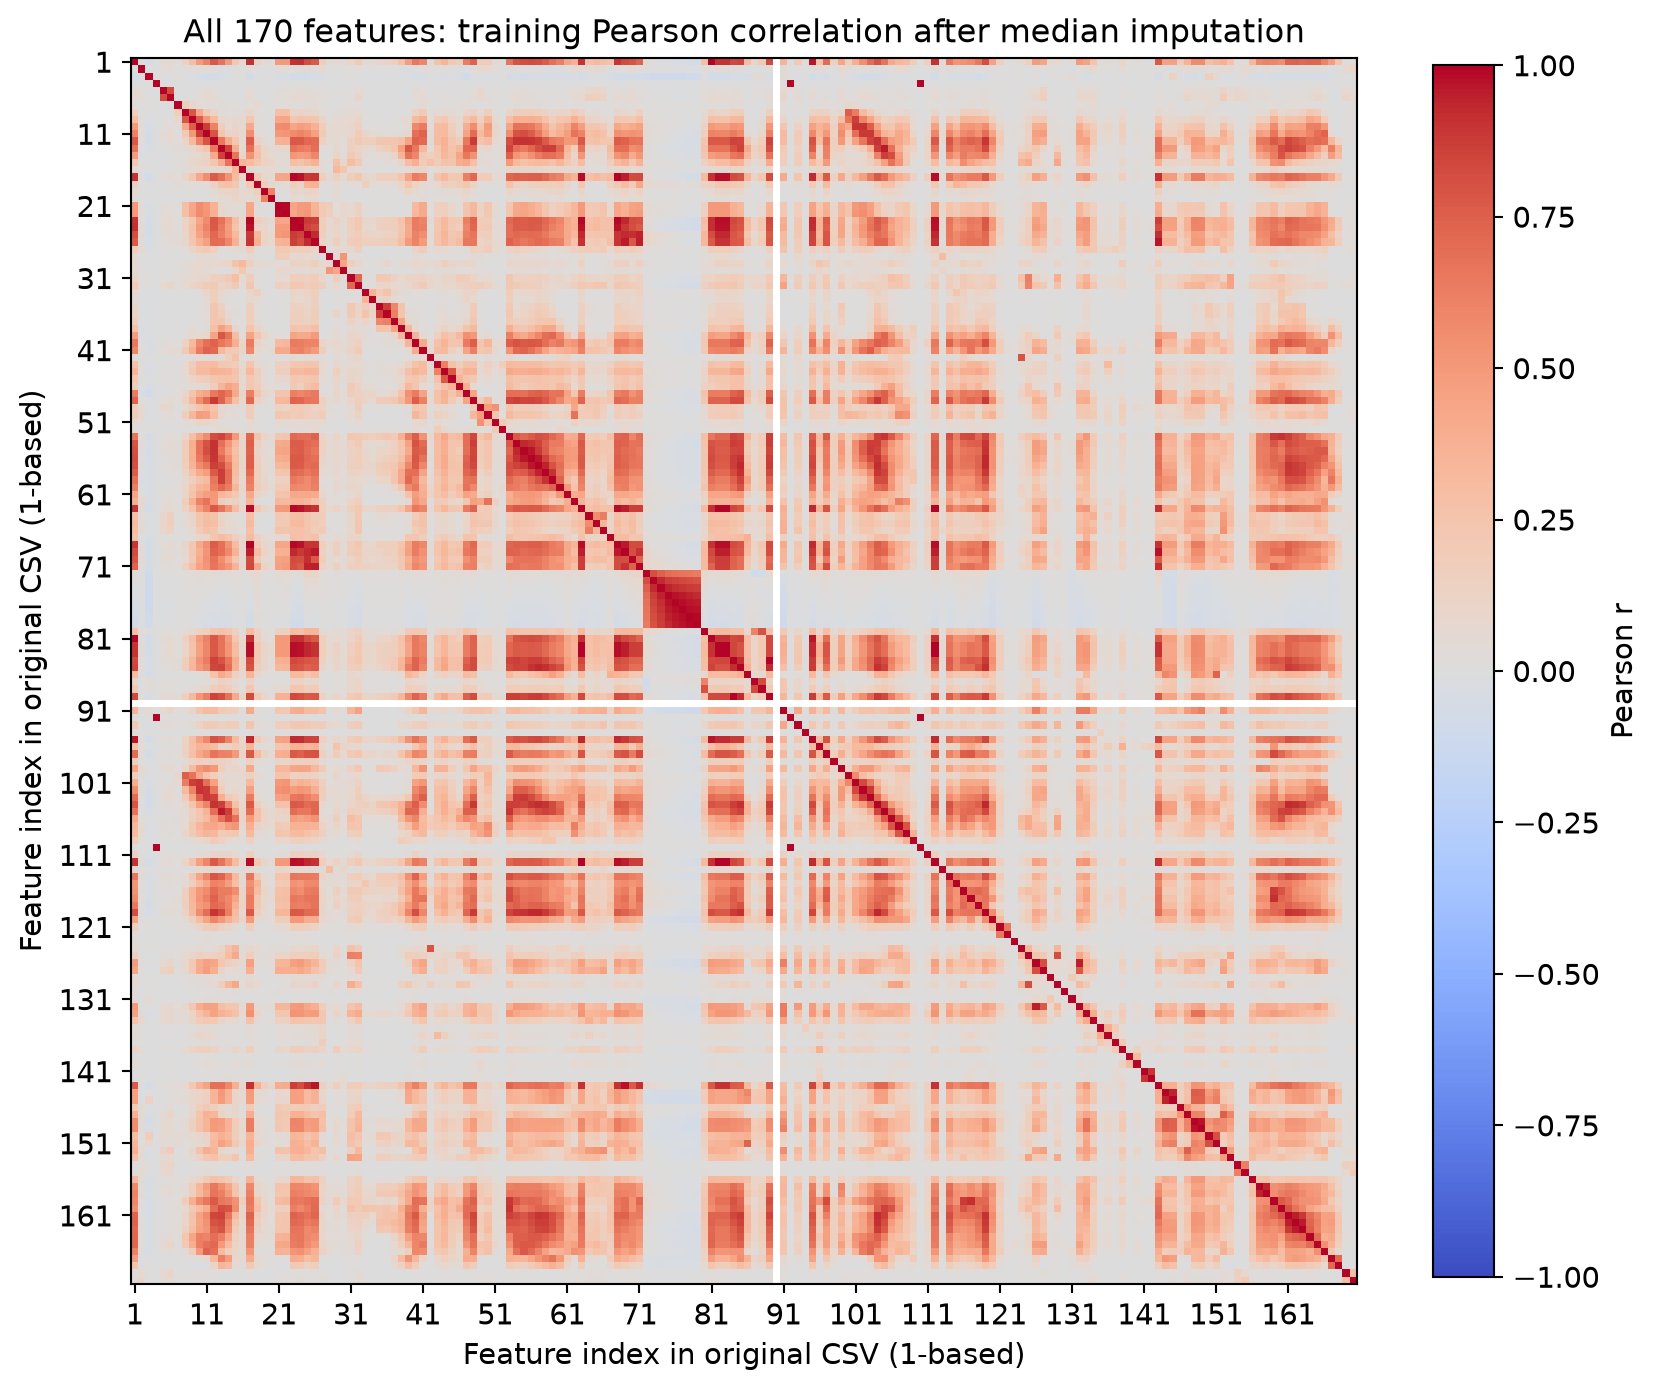

Pearson correlations use all imputed training observations. Axes retain the CSV feature order and use 1-based indices to keep the full matrix readable on paper. The exact index-to-name mapping is in results/feature_index.csv; the large, individually labeled version is figures/correlation_all_labels.pdf (also PNG). The complete numerical matrix is results/correlation.csv.

The blocks of strong positive association are consistent with related operational counters and histogram bins. Correlation describes marginal linear relationships; it neither proves causation nor captures all nonlinear interactions. Median imputation can change correlations. The diagonal is one, and the numerical matrix is checked for symmetry. Strong correlations can make separate feature effects difficult to interpret.

In [10]:
show_answer_section(pages()[2])

## 1(b)(iv). Scatter plots for the top 13 CV features

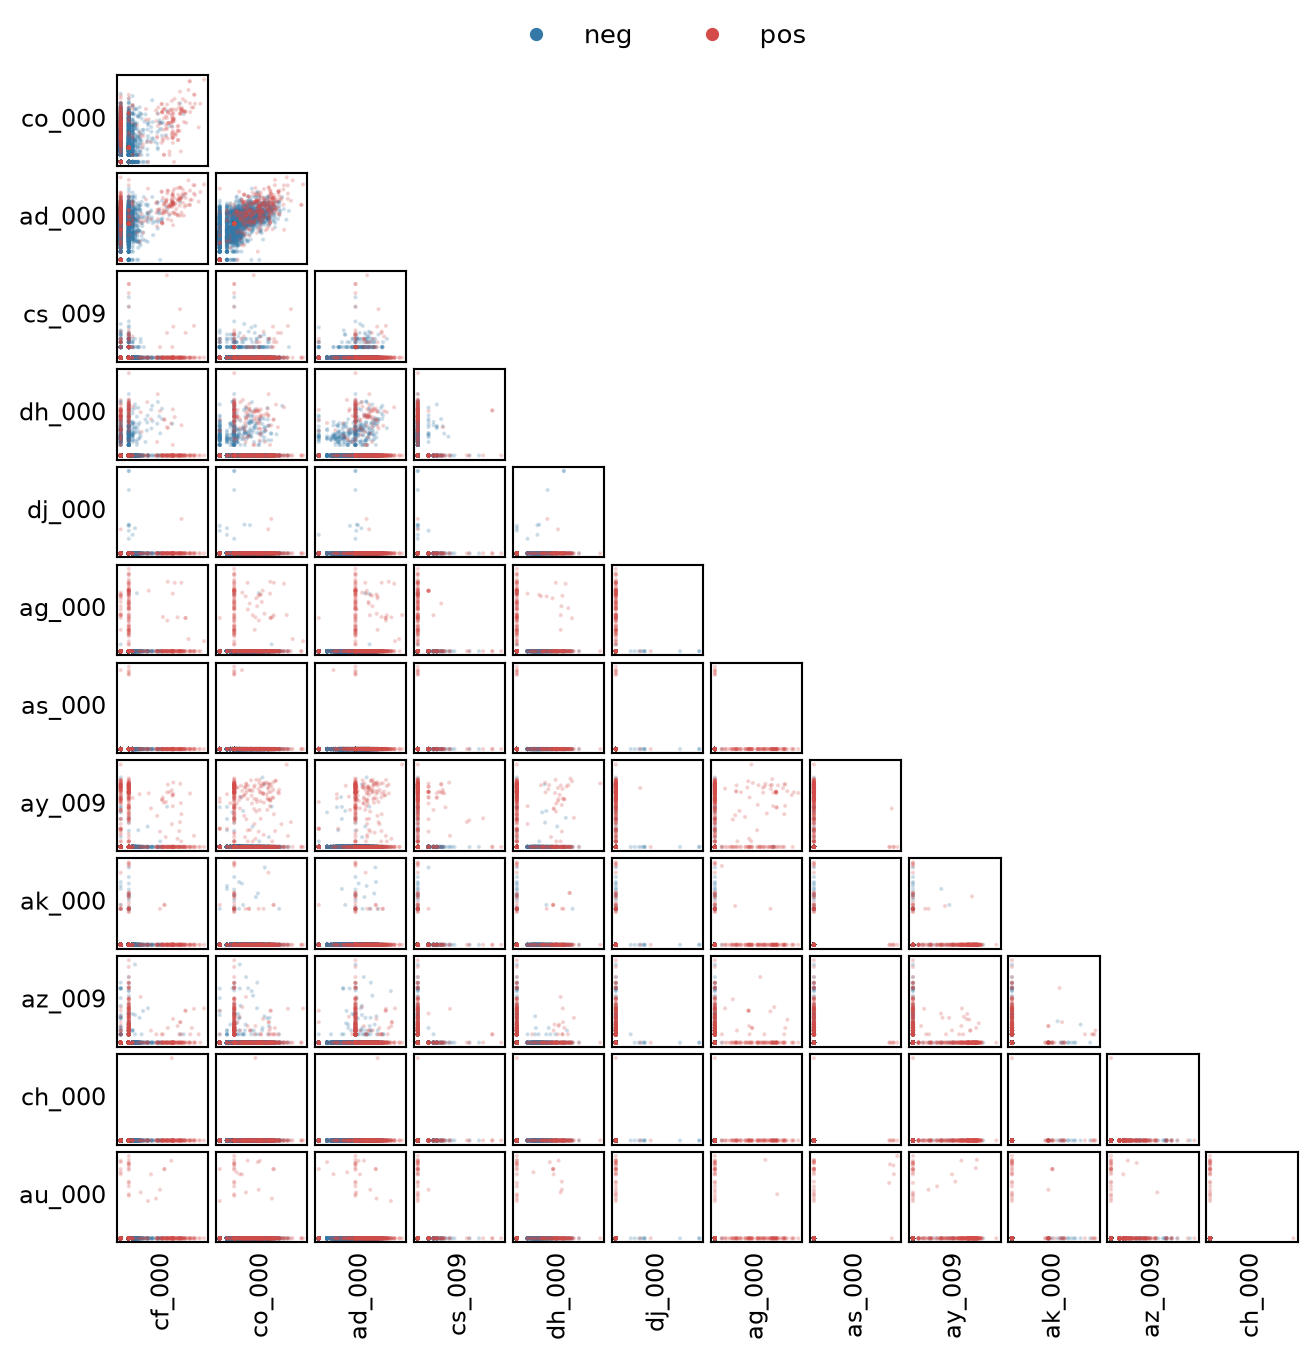

All 78 unordered feature pairs are displayed in the lower-triangular report matrix. Blue denotes neg and red denotes pos. For readable skewed counters, axes use log(1+x). Sampling uses seed 552 and includes all 1,000 positives plus 2,500 randomly selected negatives: 3,500 training observations. This deliberate class-stratified display is not representative of class prevalence.

The complete high-resolution 13-by-13 matrix is also retained. The lower-triangular report matrix is checked against every unordered pair. No model is fitted to the plotting subsample. The transformations are for visualization only.

In [11]:
show_answer_section(pages()[3])

## 1(b)(iv)-(v). Box plots and class imbalance

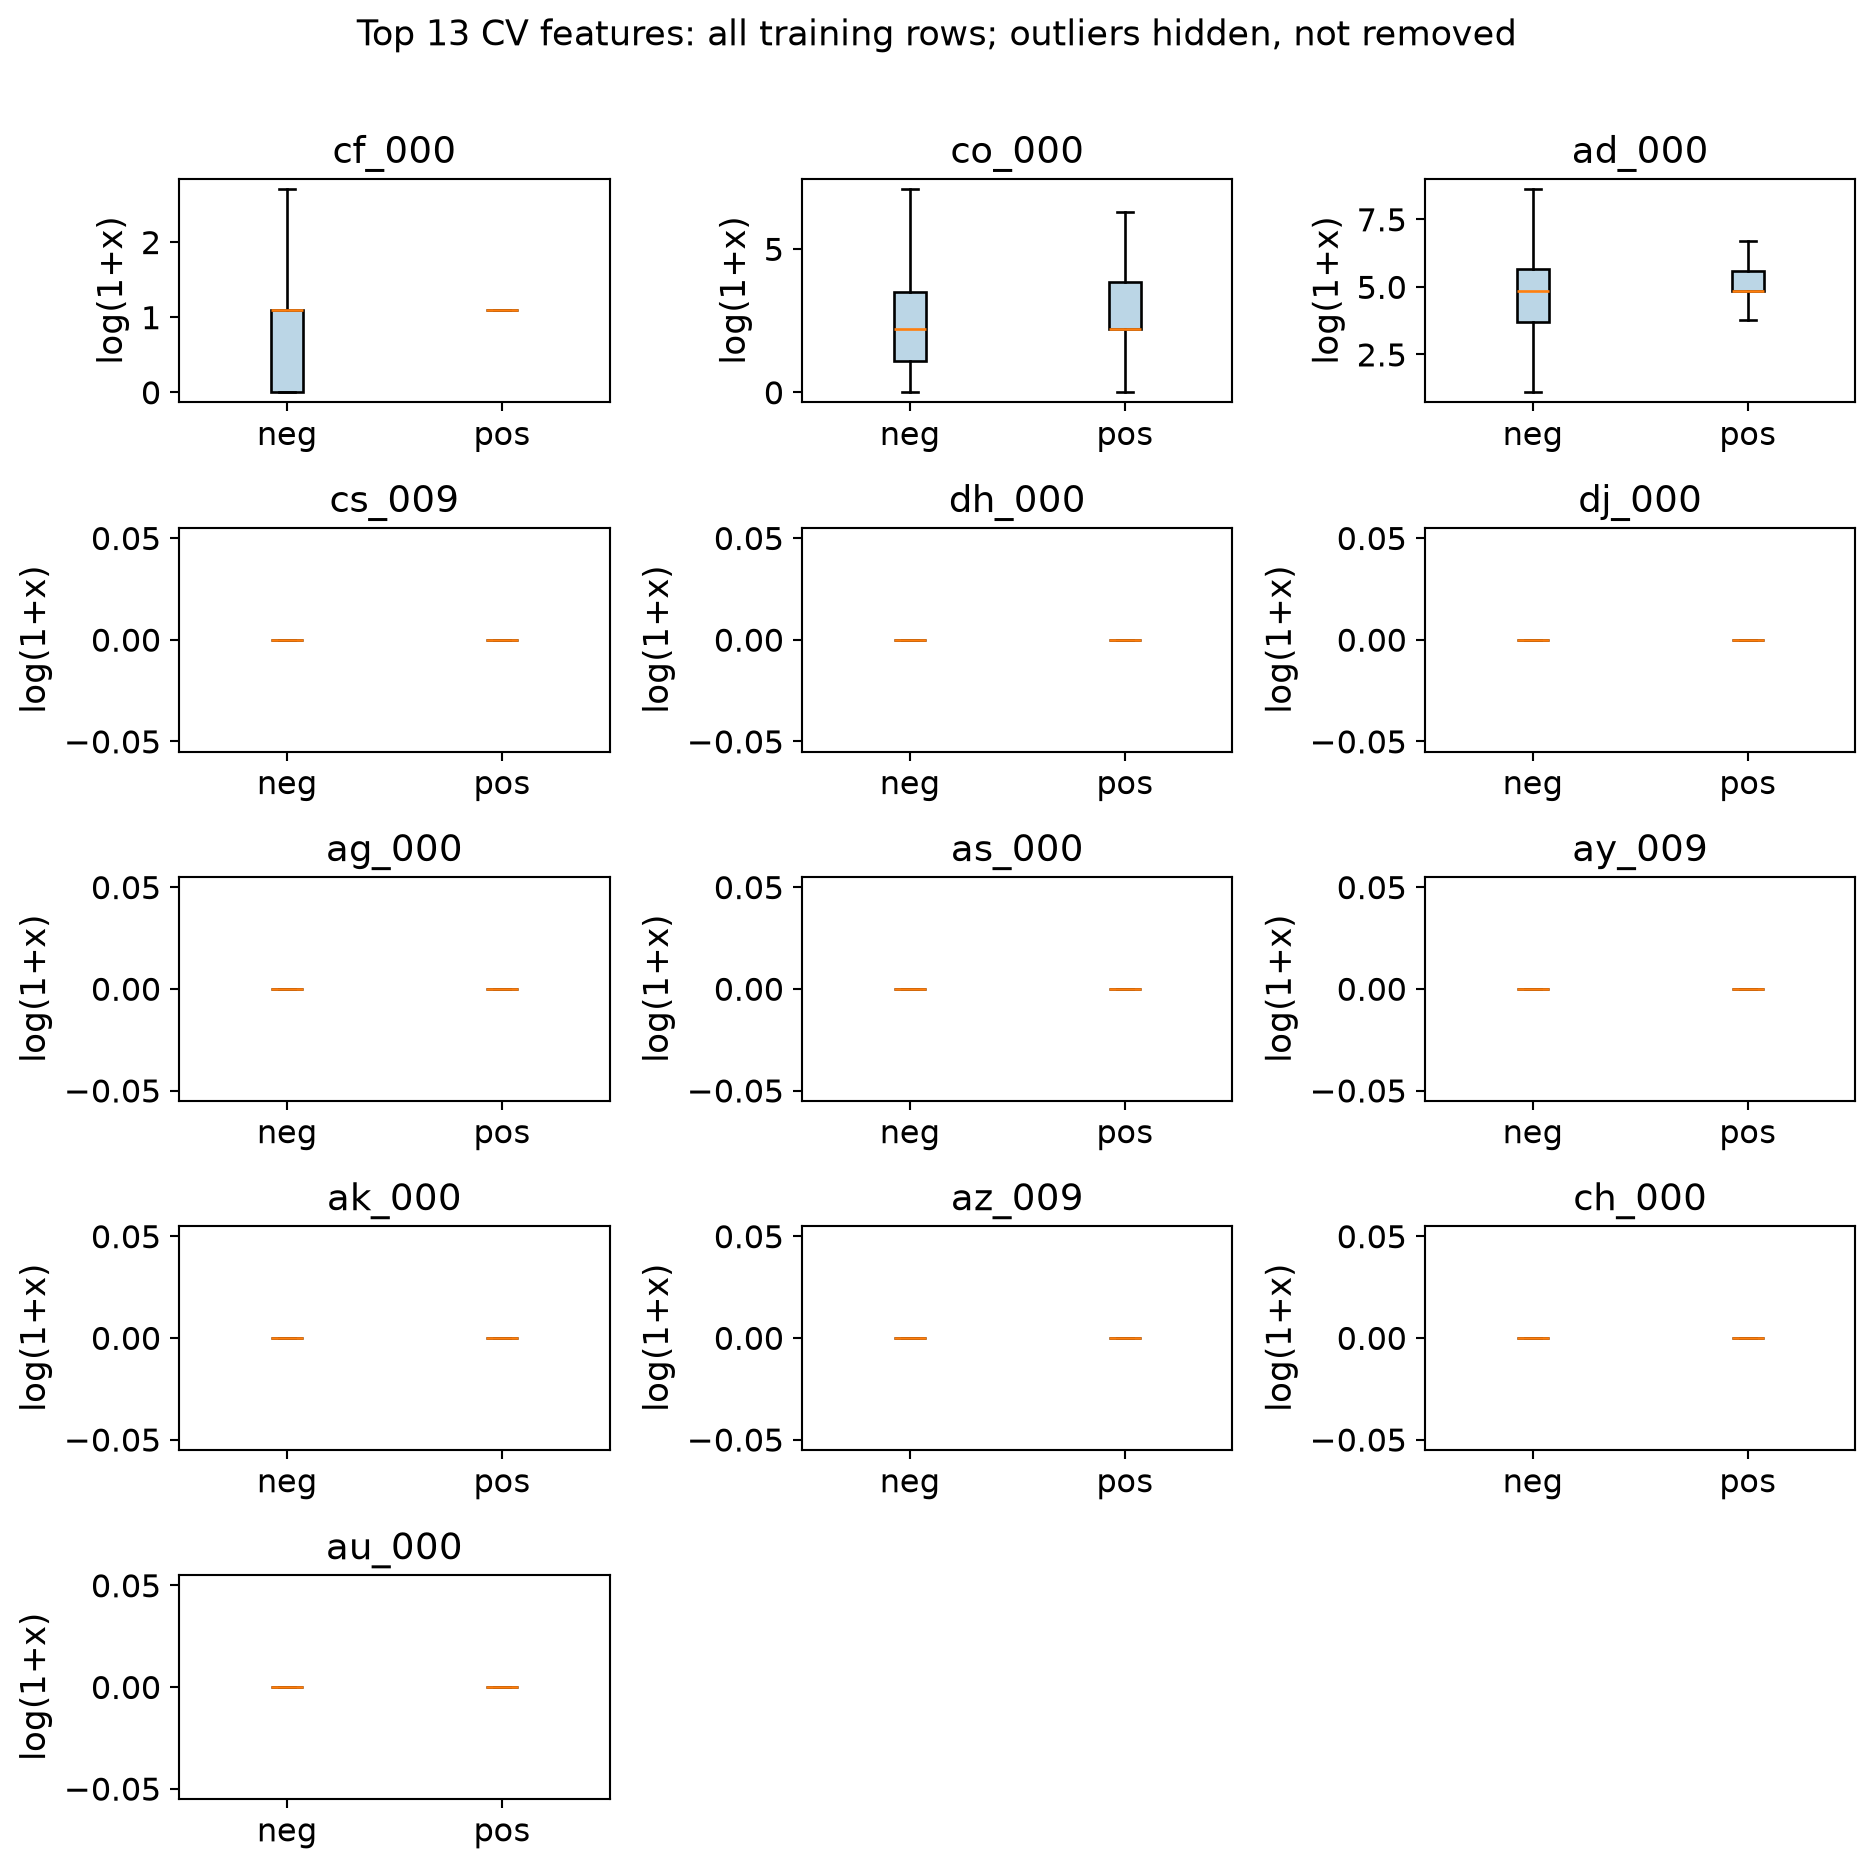

Boxes use all 60,000 imputed training rows, separated by class, with log(1+x) axes. Outlier markers are hidden to expose the boxes; no observations are deleted. Several low-frequency features concentrate at zero, so a class box can collapse to a line.

Scatter plots alone cannot establish significance: they omit conditional effects, have overplotting, and involve many inspected pairs. A visual association does not supply a hypothesis test or independent evidence of predictive value. Model-based validation or a carefully specified inferential analysis would be needed.

The training ratio is 59:1 (positive prevalence 1.667%); test prevalence is 2.344% with 15,625 negatives and 375 positives. Both splits are severely imbalanced. Always predicting neg yields errors of 1.667% and 2.344%, respectively, while missing every positive. Therefore positive precision, recall, F1 and average precision accompany the required error and ROC-AUC.

In [12]:
show_answer_section(pages()[4])

## 1(c). Random forest without imbalance compensation

Both forests use 500 fully grown Gini trees, bootstrap sampling, sqrt(170) candidate features per split, minimum leaf size 1, seed 552 and 4 workers. The entire official training set is used. A prediction is pos when the positive-class probability is at least 0.5 (including exact ties). ROC and AUC use probabilities, not hard labels.

This baseline uses class_weight=None and no resampling. OOB predictions aggregate only trees for which the observation was absent from the bootstrap sample. The reported OOB error uses the same 0.5 rule as all other confusion matrices.

| Split | Error | ROC-AUC | AP | Precision | Recall | F1 |
| --- | --- | --- | --- | --- | --- | --- |
| Train | 0.00000 | 1.00000 | 1.00000 | 1.00000 | 1.00000 | 1.00000 |
| Test | 0.00775 | 0.99435 | 0.92609 | 0.93127 | 0.72267 | 0.81381 |

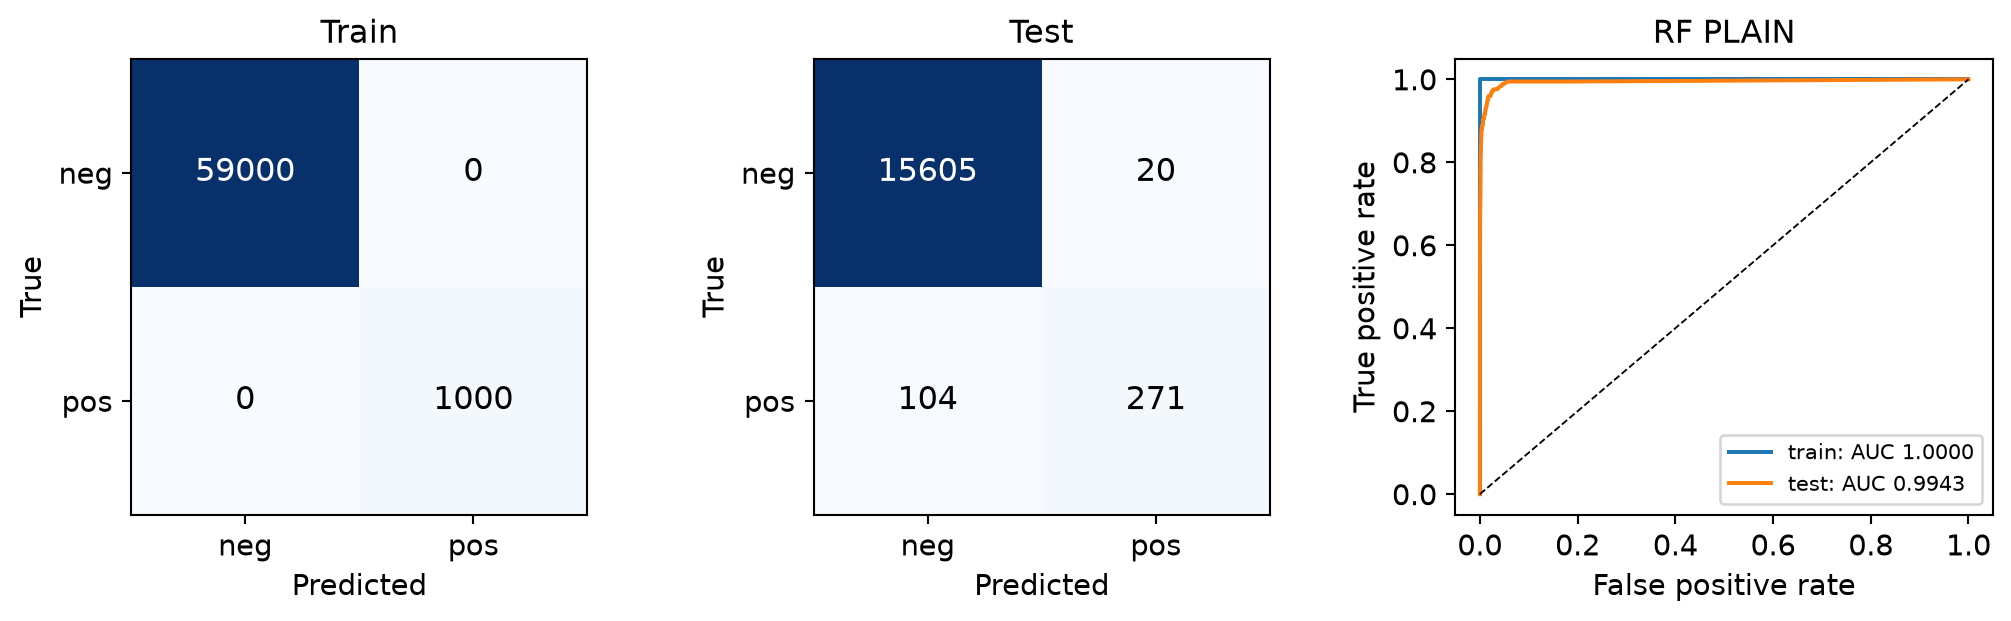

Historical unmasked OOB error = 0.00581667; official test error = 0.00775000. The historical value is retained, not assumed valid. Actual bootstrap exclusions and per-class coverage below determine whether an overall comparison is possible. Original fit/evaluation time: 135.1s.

| Group | n | Zero votes | Valid n | Coverage | OOB votes min/max/mean |
| --- | --- | --- | --- | --- | --- |
| all | 60000 | 0 | 60000 | 100.000000% | 144/228/184.002 |
| neg | 59000 | 0 | 59000 | 100.000000% | 144/228/183.996 |
| pos | 1000 | 0 | 1000 | 100.000000% | 151/214/184.315 |

Valid-row OOB error: 349/60000 = 0.00581667. All-zero probability rows=0; NaN rows=0; other invalid rows=0. Both-class complete coverage=True.

All rows and both classes are covered; the valid-row OOB error can be compared with the official test error, allowing for prevalence differences and globally fitted imputation.

Confusion matrices have true labels in rows and predicted labels in columns, ordered [neg, pos]. Training performance is resubstitution performance and can be optimistic for deep forests.

In [13]:
show_answer_section(pages()[5])

## 1(d). Random forest with class weighting

Both forests use 500 fully grown Gini trees, bootstrap sampling, sqrt(170) candidate features per split, minimum leaf size 1, seed 552 and 4 workers. The entire official training set is used. A prediction is pos when the positive-class probability is at least 0.5 (including exact ties). ROC and AUC use probabilities, not hard labels.

Chen, Liaw and Breiman [3] study cost-sensitive weighting and sampling for imbalanced forests. Here class_weight="balanced" weights class k by n/(2 n_k): approximately 0.5085 for neg and 30 for pos, a 59-fold ratio. All other forest settings are unchanged. In installed sklearn 1.9.1, balanced weights drive bootstrap draw probabilities (confirmed from stored weights and source); it does not guarantee higher minority recall [4].

| Split | Error | ROC-AUC | AP | Precision | Recall | F1 |
| --- | --- | --- | --- | --- | --- | --- |
| Train | 0.00013 | 1.00000 | 1.00000 | 0.99206 | 1.00000 | 0.99602 |
| Test | 0.00944 | 0.99418 | 0.88701 | 0.83735 | 0.74133 | 0.78642 |

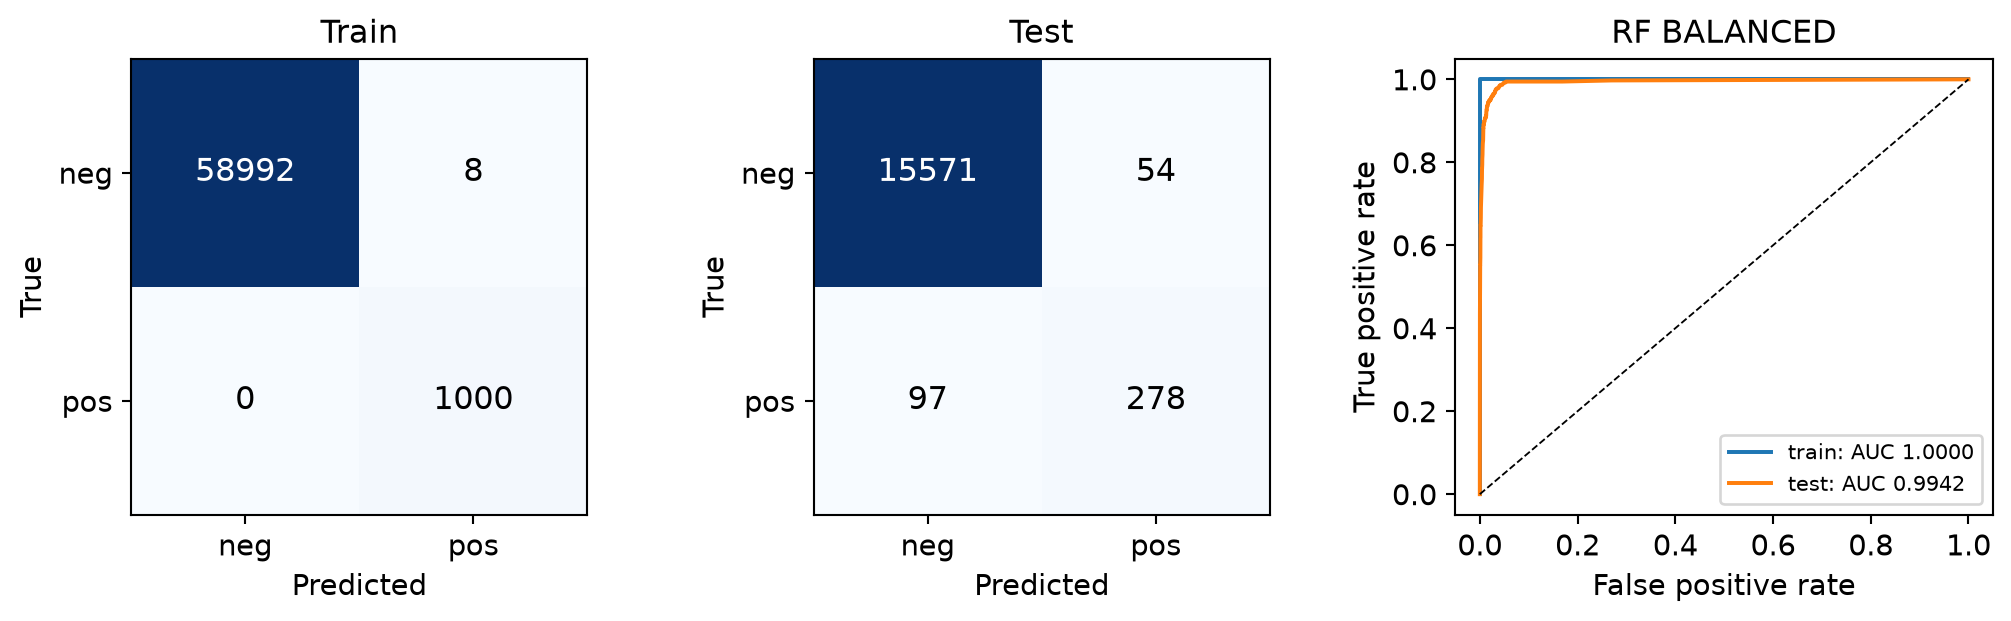

Historical unmasked OOB error = 0.01998333; official test error = 0.00943750. The historical value is retained, not assumed valid. Actual bootstrap exclusions and per-class coverage below determine whether an overall comparison is possible. Original fit/evaluation time: 68.8s.

| Group | n | Zero votes | Valid n | Coverage | OOB votes min/max/mean |
| --- | --- | --- | --- | --- | --- |
| all | 60000 | 1000 | 59000 | 98.333333% | 0/347/295.629 |
| neg | 59000 | 0 | 59000 | 100.000000% | 251/347/300.640 |
| pos | 1000 | 1000 | 0 | 0.000000% | 0/0/0.000 |

Valid-row OOB error: 199/59000 = 0.00337288. All-zero probability rows=1000; NaN rows=0; other invalid rows=0. Both-class complete coverage=False.

For balanced, all 1,000 positives have zero votes: valid-row error is negative-only, NOT overall OOB error and NOT comparable to full test error. In sklearn 1.9.1, normalized balanced bootstrap weights give each positive draw probability 1/2000 and expected multiplicity 30 per tree. The generic too-few-trees warning is caused by unequal inclusion, not a small forest. Global training imputation also makes ordinary OOB approximate rather than fully cross-fitted.

Confusion matrices have true labels in rows and predicted labels in columns, ordered [neg, pos]. Training performance is resubstitution performance and can be optimistic for deep forests.

Compared with the unweighted forest, weighting changes test recall from 0.7227 to 0.7413 and precision from 0.9313 to 0.8373. Its observed behavior, rather than the compensation label alone, determines whether it helps. A small overall error can be achieved by emphasizing the abundant negatives; recall directly exposes missed APS failures.

In [14]:
show_answer_section(pages()[6])

## 1(d). Supplement: uniform-bootstrap balanced_subsample forest

The original balanced forest and its train/test results remain unchanged. This separately labeled supplemental forest uses the same 500 trees, seed 552 and all other settings, but class_weight=balanced_subsample. Installed sklearn draws uniform bootstraps then applies balanced weights inside each tree; this permits both-class OOB coverage. It is not selected on test performance.

| Split | Error | ROC-AUC | AP | Precision | Recall | F1 |
| --- | --- | --- | --- | --- | --- | --- |
| Train | 0.00000 | 1.00000 | 1.00000 | 1.00000 | 1.00000 | 1.00000 |
| Test | 0.01063 | 0.99454 | 0.88633 | 0.93991 | 0.58400 | 0.72039 |

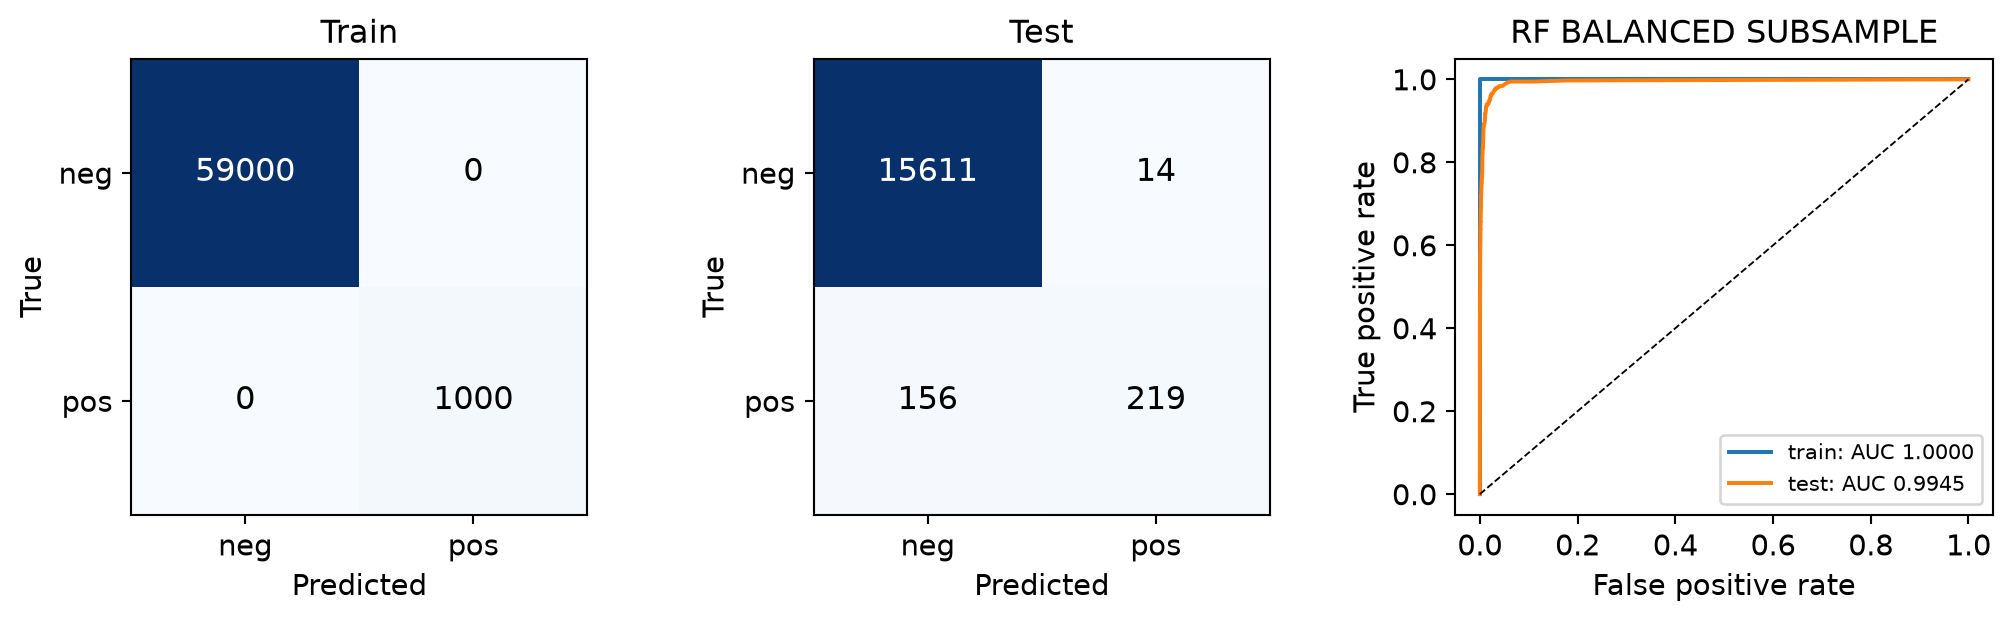

| Group | n | Zero votes | Valid n | Coverage | OOB votes min/max/mean |
| --- | --- | --- | --- | --- | --- |
| all | 60000 | 0 | 60000 | 100.000000% | 144/228/184.002 |
| neg | 59000 | 0 | 59000 | 100.000000% | 144/228/183.996 |
| pos | 1000 | 0 | 1000 | 100.000000% | 151/214/184.315 |

Valid-row OOB error: 457/60000 = 0.00761667. All-zero probability rows=0; NaN rows=0; other invalid rows=0. Both-class complete coverage=True.

All rows and both classes are covered; the valid-row OOB error can be compared with the official test error, allowing for prevalence differences and globally fitted imputation.

Supplement OOB error 0.00761667; test error 0.01062500; test minus valid OOB +0.00300833. This is a different compensation method, not a repair of the original balanced forest. Training/official-test metrics use original distributions. Fit/audit/evaluation time stored for this supplemental run: 41.73s. OOB_MODE distinguishes fitting from verification.

In [15]:
show_answer_section(oob_supplement_answer())

In [16]:
show_answer_section(pages()[7])

## 1(e). XGBoost interpretation and validation design

The installed XGBoost version is 3.4.1. Its local XGBClassifier API and the matching v3.4.1 parameter documentation were inspected [5]. The homework describes logistic regressions at tree nodes, but the standard gbtree booster uses feature-threshold splits and scalar leaf scores. binary:logistic applies a logistic loss/link to the summed score. reg_alpha is an L1 penalty on leaf weights; it does not fit a logistic regression at every node.

$$
P(Y=1\mid x)=\sigma\!\left(\sum_{t=1}^{T}f_t(x)\right),\quad\Omega(f_t)=\gamma L_t+\frac{\lambda}{2}\sum_\ell w_{t\ell}^2+\alpha\sum_\ell|w_{t\ell}|
$$

gblinear instead fits a global linear model, with L1-regularized coefficients; it is not a tree model. A true logistic model tree combines a tree with local logistic models and needs a different implementation. Local Homework 5 repeats similar model-tree terminology without an API mapping; no clarification was found in available local course material. Instructor confirmation remains needed. The runnable interpretation here is gbtree + binary:logistic + tuned reg_alpha; it satisfies the XGBoost/alpha experiment but does not claim to realize the described node-level model tree. Instructor confirmation of that wording remains appropriate.

Fixed before test evaluation: 250 rounds, depth 4, learning rate 0.08, L2 penalty 1, max_bin 256, min_child_weight 1, subsample = colsample_bytree = 1, histogram trees on CPU, 4 threads, base_score 0.5. There is no early stopping or test-based choice of rounds/thresholds. There is no class weighting or resampling in this section.

Stratified shuffled 5-fold CV (seed 552) uses the full 60,000 training rows, with 48,000 fitting rows and 12,000 validation rows per fold. The imputer and StandardScaler are fitted inside the training fold. Scaling is shared with 1(f) to isolate the SMOTE comparison; it is not needed for tree splits. Alpha maximizes mean validation average precision (AP), with smaller alpha breaking exact ties. AP rewards ranking of rare positives; CV misclassification at 0.5 is also reported.

| Alpha | Mean CV AP | AP SD | Mean CV error | Error SD |
| --- | --- | --- | --- | --- |
| 0 | 0.88760 | 0.01406 | 0.00562 | 0.00055 |
| 0.001 | 0.88568 | 0.01212 | 0.00577 | 0.00054 |
| 0.01 | 0.88727 | 0.01173 | 0.00568 | 0.00064 |
| 0.1 | 0.88643 | 0.01335 | 0.00582 | 0.00064 |
| 1 | 0.88472 | 0.01300 | 0.00598 | 0.00084 |
| 10 | 0.86932 | 0.01362 | 0.00658 | 0.00063 |
| 100 | 0.78346 | 0.02698 | 0.00943 | 0.00089 |

## 1(e). XGBoost without compensation: results

The selected alpha is 0; alpha=0 means no L1 penalty. Mean validation AP is 0.88760; mean CV misclassification error is 0.00562, with fold SD 0.00055. Selection used only training-fold validation predictions.

| Split | Error | ROC-AUC | AP | Precision | Recall | F1 |
| --- | --- | --- | --- | --- | --- | --- |
| Train | 0.00118 | 0.99959 | 0.99088 | 0.99679 | 0.93200 | 0.96331 |
| Test | 0.00637 | 0.99623 | 0.93199 | 0.95652 | 0.76267 | 0.84866 |

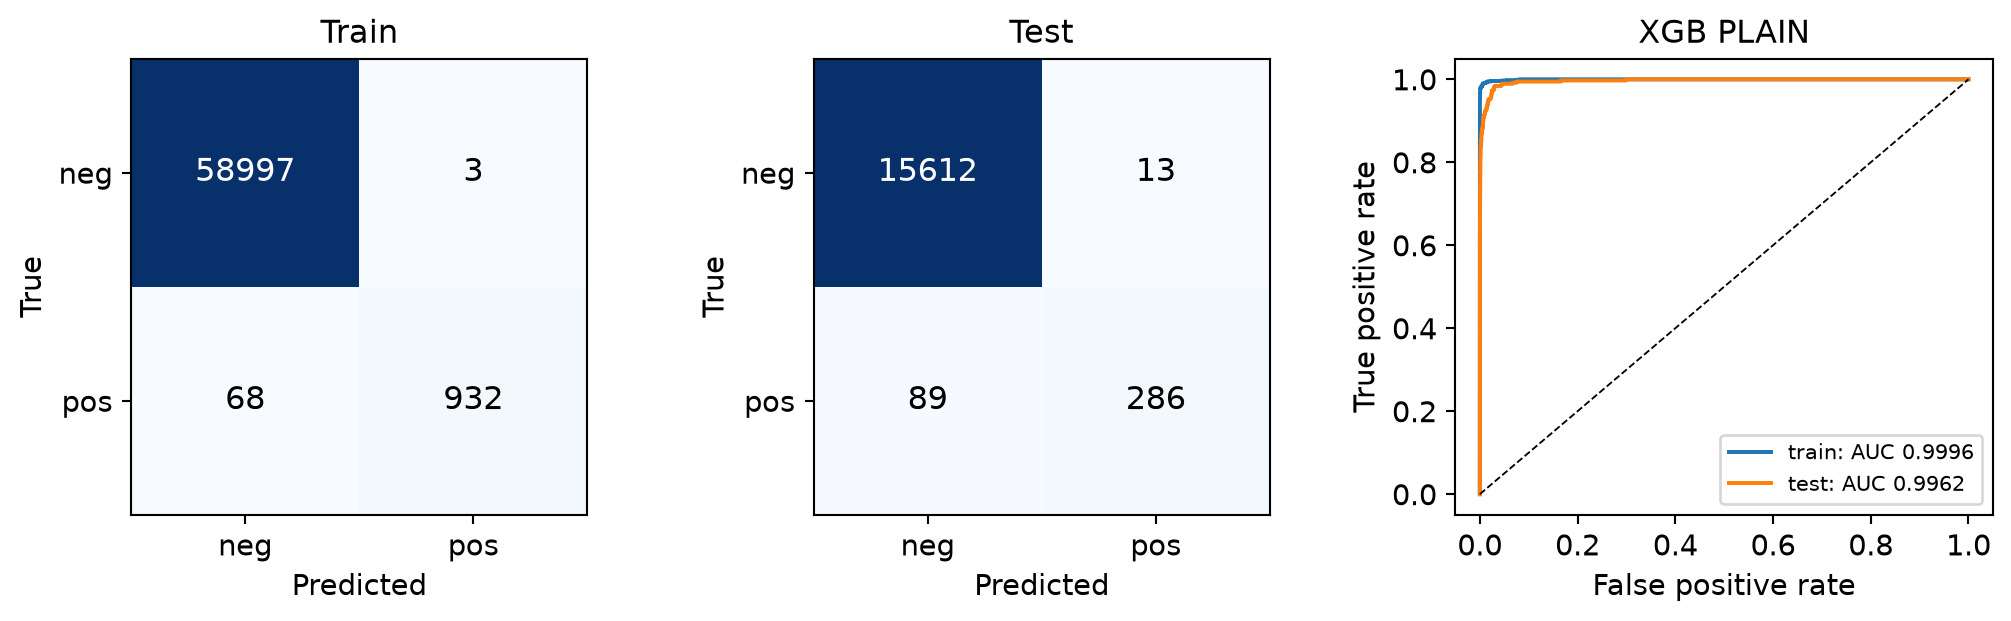

Test error (0.00637) minus selected-alpha CV error (0.00562) is 0.00076. CV fits use 80% of training rows and train-only fold preprocessing, whereas the final model uses all training rows and the main test evaluation follows the footnote. Distribution/prevalence differences can also affect this gap.

The selected mean CV performance is a tuning estimate, not an independent, unbiased estimate of the whole selection procedure. Nested CV was not required or performed. The untouched official test set gives the final evaluation after tuning. Fold SD is descriptive variation across five dependent folds, not a confidence interval.

The final fit and evaluation took 4.5 seconds; the 35 CV fits took 171.2 seconds in total. Full per-fold scores and times are saved in results/xgb_plain_cv_folds.csv. AP is sklearn average_precision_score (a recall-weighted precision sum), not trapezoidal PR-AUC.

In [17]:
show_answer_section(pages()[8])

In [18]:
show_answer_section(pages()[9])

## 1(f). SMOTE: full-data and fold-safe design

SMOTE creates a synthetic positive between an observed minority point and one of its minority nearest neighbors [7]. A single seeded imblearn Pipeline applies: training-fold median imputer, training-fold StandardScaler, SMOTE(k_neighbors=5, sampling_strategy=1.0), then the same XGBoost estimator as 1(e). CV runs serially and each model uses 4 threads to avoid nested parallel oversubscription.

$$
x_{new}=x_i+u(x_{neighbor}-x_i),\qquad u\sim U(0,1)
$$

Distance is computed after standardizing all 170 features using current training-fold statistics; otherwise large-unit counters dominate Euclidean neighbors. Standardization still cannot eliminate high-dimensional distance issues, skew or imputation artifacts. No log transformation is applied in the model pipeline.

| Stage | neg | Original pos | Final pos | Total |
| --- | --- | --- | --- | --- |
| Each CV training fold | 47,200 | 800 | 47,200 | 94,400 |
| Final full training fit | 59,000 | 1,000 | 59,000 | 118,000 |
| Each validation fold (unchanged) | 11,800 | 200 | 200 | 12,000 |
| Official test (unchanged) | 15,625 | 375 | 375 | 16,000 |

The validation rows are never passed to fit_resample; resampling before splitting would leak neighbor information and invalidate validation [8]. Cache reuse is restricted to identical training-fold inputs and settings. Final SMOTE uses the entire original training set without downsampling. All reported training metrics are evaluated on the original 60,000 observations, not the synthetic population.

The same folds, alpha grid, selection metric, fixed rounds and classification rule are used as in 1(e). Alpha is reselected for the SMOTE procedure; its effect depends on changed sample size and gradients.

| Alpha | Mean CV AP | AP SD | Mean CV error | Error SD |
| --- | --- | --- | --- | --- |
| 0 | 0.84750 | 0.02992 | 0.00977 | 0.00057 |
| 0.001 | 0.84761 | 0.02998 | 0.00975 | 0.00057 |
| 0.01 | 0.84911 | 0.02871 | 0.00985 | 0.00065 |
| 0.1 | 0.84890 | 0.03101 | 0.00990 | 0.00093 |
| 1 | 0.84974 | 0.03083 | 0.00990 | 0.00083 |
| 10 | 0.84177 | 0.02887 | 0.01052 | 0.00070 |
| 100 | 0.78665 | 0.02999 | 0.02017 | 0.00159 |

## 1(f). SMOTE + XGBoost: results and tradeoffs

Selected alpha = 1; mean CV AP = 0.84974; mean CV error = 0.00990 (fold SD 0.00083). The final data contain 59,000 negatives and 59,000 positives. Full-data SMOTE took 0.16 seconds, and final scaling, SMOTE, fit and evaluation took 7.3 seconds.

| Split | Error | ROC-AUC | AP | Precision | Recall | F1 |
| --- | --- | --- | --- | --- | --- | --- |
| Train | 0.00583 | 0.99885 | 0.96342 | 0.75712 | 0.95700 | 0.84541 |
| Test | 0.01600 | 0.99365 | 0.88362 | 0.60799 | 0.89333 | 0.72354 |

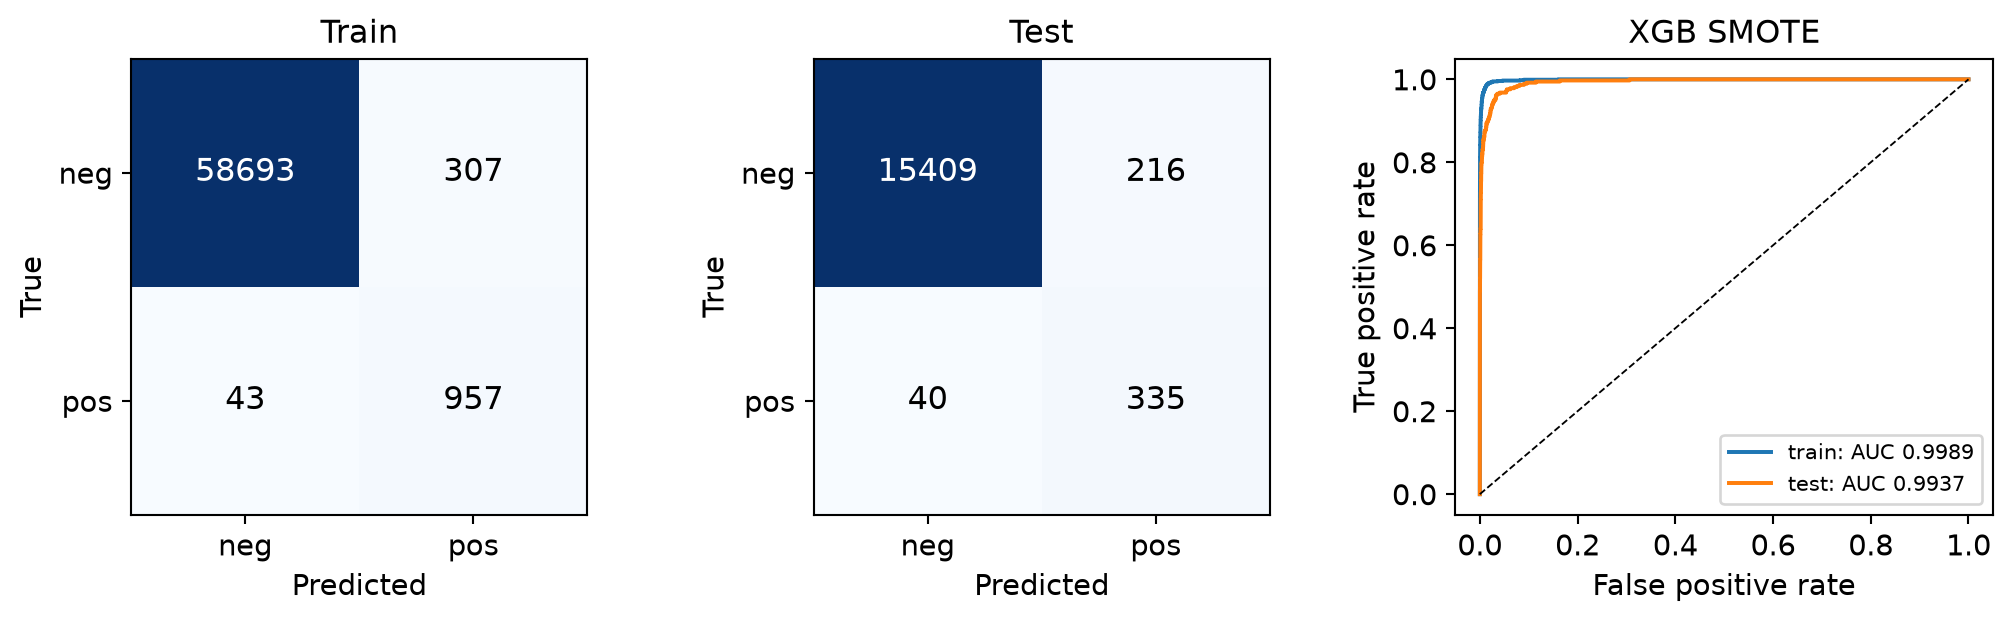

Test error minus selected-alpha CV error is 0.00610. The 35 CV fits required 287.4 seconds in total, including all fold preprocessing; full mode executes every fit afresh. Both alpha searches include all original training observations; only the fold fitting sets are oversampled.

Without SMOTE, test precision/recall are 0.9565/0.7627, with 13 false positives and 89 false negatives. With SMOTE they are 0.6080/0.8933, with 216 false positives and 40 false negatives. These counts expose the minority-recall versus unnecessary-inspection tradeoff.

Oversampling changes the fitted class prior and may distort probability calibration. A 0.5 threshold is retained for comparability, rather than optimized on official test labels. Scores should not automatically be interpreted as calibrated failure probabilities in the original population.

In [19]:
show_answer_section(pages()[10])

## 1(c)-(f). Unified comparison and sensitivity

| Model / test | Error | ROC-AUC | AP | Prec. | Recall | F1 |
| --- | --- | --- | --- | --- | --- | --- |
| RF: unweighted | 0.0077 | 0.9943 | 0.9261 | 0.9313 | 0.7227 | 0.8138 |
| RF: balanced | 0.0094 | 0.9942 | 0.8870 | 0.8373 | 0.7413 | 0.7864 |
| XGB: unweighted | 0.0064 | 0.9962 | 0.9320 | 0.9565 | 0.7627 | 0.8487 |
| XGB: SMOTE | 0.0160 | 0.9937 | 0.8836 | 0.6080 | 0.8933 | 0.7235 |

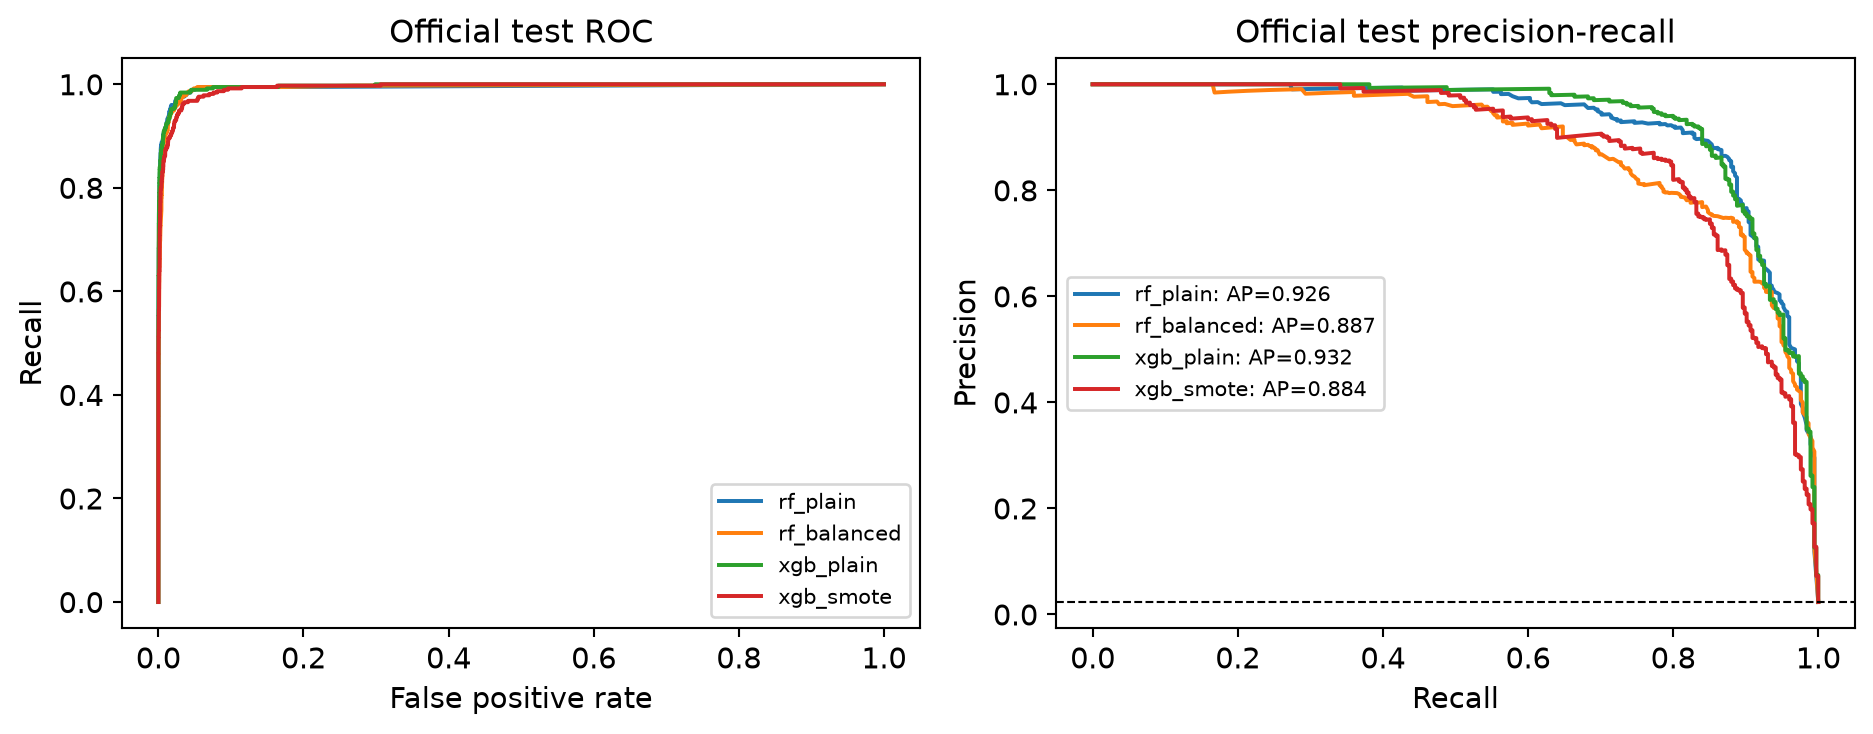

### Sensitivity: fit the imputer on training data only

Each model is held fixed; only test missing-value filling changes from test medians to training medians. This is sensitivity analysis, never tuning. For SMOTE, main versus train-only test error is 0.01600 versus 0.01075; FP is 216 versus 125, FN is 40 versus 47. Synthetic neighbors can amplify imputed-value shifts.

| Model | Main error | Train-only error | Main AP | Train-only AP |
| --- | --- | --- | --- | --- |
| RF: unweighted | 0.00775 | 0.00775 | 0.92609 | 0.92614 |
| RF: balanced | 0.00944 | 0.00944 | 0.88701 | 0.88716 |
| XGB: unweighted | 0.00637 | 0.00625 | 0.93199 | 0.93160 |
| XGB: SMOTE | 0.01600 | 0.01075 | 0.88362 | 0.89974 |

ROC-AUC measures ranking across both classes; AP focuses on precision along minority recall and depends on prevalence. The dashed PR baseline is the test positive prevalence (0.02344). No model or operating threshold was selected using this figure. Comparisons apply to this fixed protocol and one official test set.

The data description assigns cost 10 to an unnecessary inspection and 500 to a missed failure. For context, test cost (10 FP + 500 FN) is RF: unweighted: 52,200, RF: balanced: 49,040, XGB: unweighted: 44,630, XGB: SMOTE: 22,160. These retrospective costs did not guide parameter or threshold selection.

In [20]:
show_answer_section(pages()[11])

## Question 2. ISLR 6.6.3: relaxing the lasso constraint

Edition check: ISLR second edition (2021, corrected June 21, 2023), Section 6.6, Exercise 3. The first edition places the same exercise in 6.8. The problem minimizes training residual sum of squares with an unpenalized intercept under an L1 coefficient bound s [1].

$$
\min_{\beta_0,\beta}\sum_i\left(y_i-\beta_0-\sum_j x_{ij}\beta_j\right)^2\quad\mathrm{subject\ to}\quad\sum_j|\beta_j|\leq s
$$

**(a) Training RSS: option iv, decreases (more precisely, is nonincreasing).** If s2 is at least s1, every solution feasible at s1 remains feasible at s2. Minimizing over a larger set cannot increase training RSS. At s = 0, all slopes vanish and only the sample-mean intercept remains. Once a least-squares solution is feasible, RSS can stay constant.

**(b) Test RSS: option ii, typically decreases and then increases (a U shape).** Initially loosening a tight constraint can reduce underfitting. Excess flexibility eventually increases estimation variance and can worsen held-out fit. This is the intended bias-variance pattern, not a guaranteed shape for every realized test set.

**(c) Variance: option iii, typically increases.** A larger radius weakens shrinkage and allows coefficients to react more strongly to training-sample noise.

**(d) Squared bias: option iv, typically decreases.** Less shrinkage removes the distortion imposed by a tight L1 bound. This describes the usual statistical trend rather than a universal monotonic theorem for arbitrary designs and data-generating functions.

**(e) Irreducible error: option v, remains constant.** The conditional noise variance is a property of the data-generating process; changing a fitting constraint cannot change it.

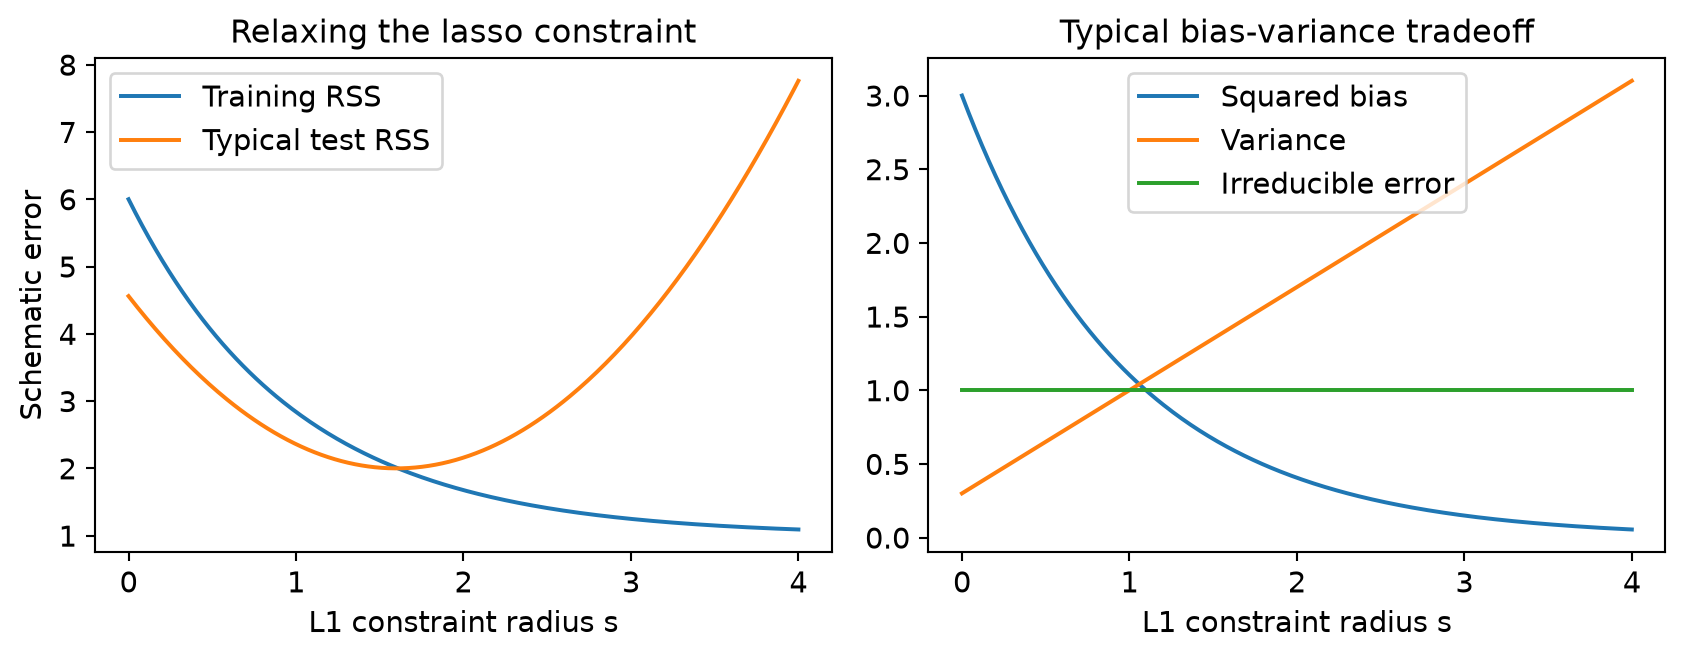

These plots are schematic illustrations, not outputs of the APS experiments. Only the nested-feasible-set argument in (a) guarantees monotonicity; actual test curves may be noisy or have their minimum at a boundary.

In [21]:
show_answer_section(pages()[12])

In [22]:
show_answer_section(pages()[13])

## Question 3. ISLR 6.6.5: identical predictors

ISLR second edition Section 6.6 Exercise 5 (first edition: 6.8.5). Let x1 = x11 = x12 and x2 = x21 = x22, with centered x and y, so the fitted intercept is zero. Assume a nonzero predictor column and a positive penalty unless stated otherwise. Put t = beta1 + beta2, A = x1 squared + x2 squared > 0, and C = x1 y1 + x2 y2.

### (a) Ridge objective

$$
\min_{\beta_1,\beta_2}\ (y_1-x_1\beta_1-x_1\beta_2)^2+(y_2-x_2\beta_1-x_2\beta_2)^2+\lambda(\beta_1^2+\beta_2^2)
$$

### (b) Why the ridge coefficients are equal

For a fixed sum t, the residual term depends only on t. The identity below shows that the penalty is uniquely minimized by beta1 = beta2 = t/2. Equivalently, subtracting the two normal equations gives 2 lambda (beta1 - beta2) = 0. Strict convexity from lambda > 0 makes the solution unique.

... (4 outputs left out)

The triangle inequality gives |beta1| + |beta2| >= |t|, with equality whenever the two coefficients have the same sign (allowing zero). Thus minimizing reduces to the one-dimensional objective A t squared - 2 C t + lambda |t| plus a constant. Its minimizer is the soft-thresholded sum below.

$$
t^*=\frac{\mathrm{sign}(C)(|C|-\lambda/2)_+}{A},\qquad(\hat{\beta}_1,\hat{\beta}_2)=(a t^*,(1-a)t^*),\quad 0\leq a\leq1
$$

When t* is nonzero, this continuum includes selecting only the first predictor, selecting only the second, and every same-sign split between them. All pairs have identical fitted values and identical L1 penalty. This explains why a lasso solver can treat perfectly correlated variables differently.

Boundary qualifications: if lambda >= 2|C| and lambda > 0, t* = 0 and only (0,0) minimizes, so nonuniqueness is not universal. If lambda = 0, any pair summing to C/A is least-squares optimal, including opposite signs; the equality claim for ridge is then not forced. These qualifications refine the exercise's generic nonuniqueness statement.

## Question 4. ISLR 8.4.5: votes versus probabilities

Both checked R editions place this exercise in Section 8.4, Exercise 5. For one fixed predictor value, ten bootstrap classification trees return the following red-class probabilities [1].

| Tree | 1 | 2 | 3 | 4 | 5 | 6 | 7 | 8 | 9 | 10 |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| P(Red) | 0.10 | 0.15 | 0.20 | 0.20 | 0.55 | 0.60 | 0.60 | 0.65 | 0.70 | 0.75 |

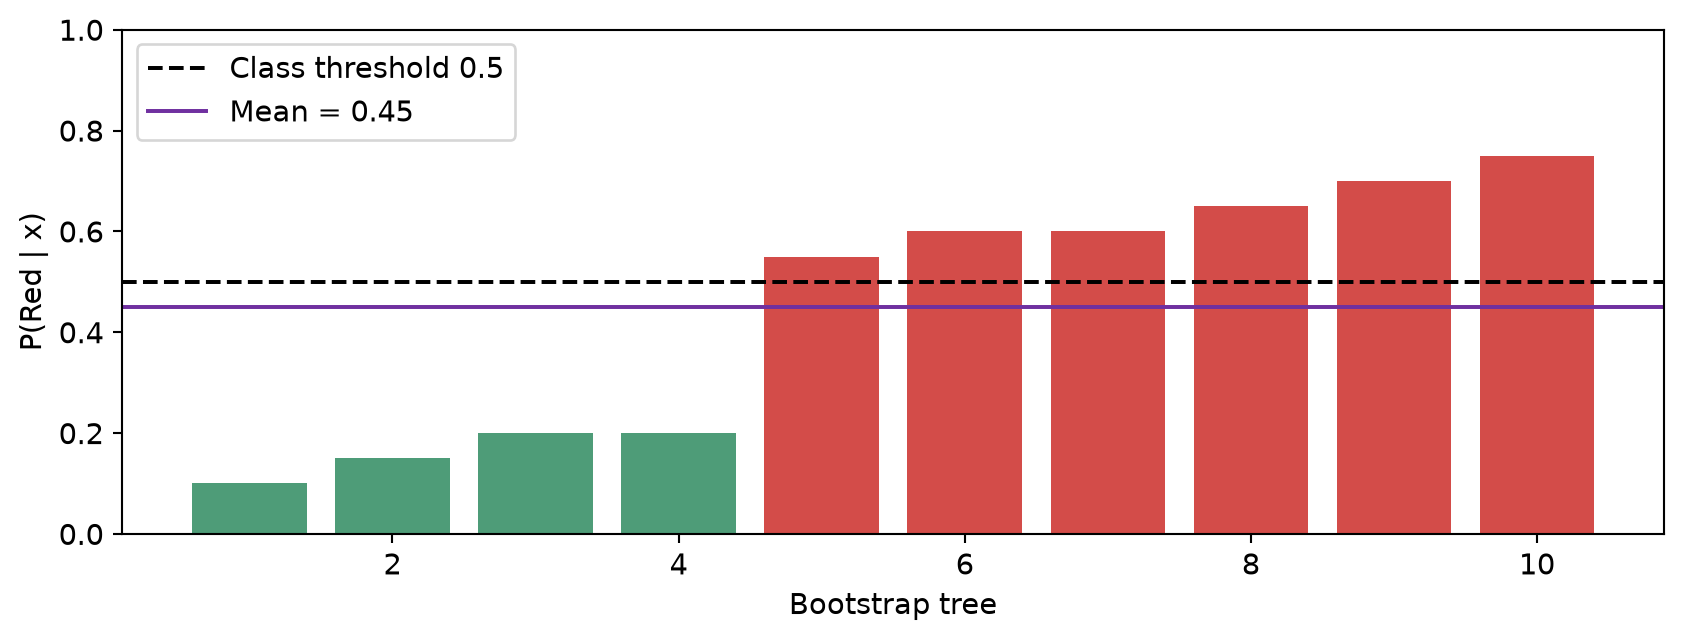

### Majority vote: Red

Applying a 0.5 rule separately to each tree gives four Green votes from trees 1-4 and six Red votes from trees 5-10. Six of ten hard predictions are Red, so the majority-vote ensemble predicts Red. No individual probability is exactly 0.5, so the tie convention is irrelevant.

### Average probability: Green

$$
\bar p_{Red}=\frac{0.10+0.15+0.20+0.20+0.55+0.60+0.60+0.65+0.70+0.75}{10}=0.45
$$

Averaging probabilities gives Red probability 0.45 and Green probability 0.55, so the probability-average rule predicts Green. The few low Red probabilities can outweigh a larger number of moderately high Red probabilities.

Hard voting counts how many models favor a class and discards their confidence. Probability averaging retains the numerical magnitudes. The two aggregation methods need not agree. The random forests in Question 1 use sklearn probability averaging followed by the explicitly recorded 0.5 threshold; this exercise should not be read as a claim that every software implementation votes on hard labels.

In [23]:
show_answer_section(pages()[14])

## Question 5. ISLR 9.7.3: maximal-margin geometry

Both checked R editions place this seven-observation problem in Section 9.7, Exercise 3. The numbered observations and constructions are shown below; the black dashed lines are supporting lines, not additional decision boundaries.

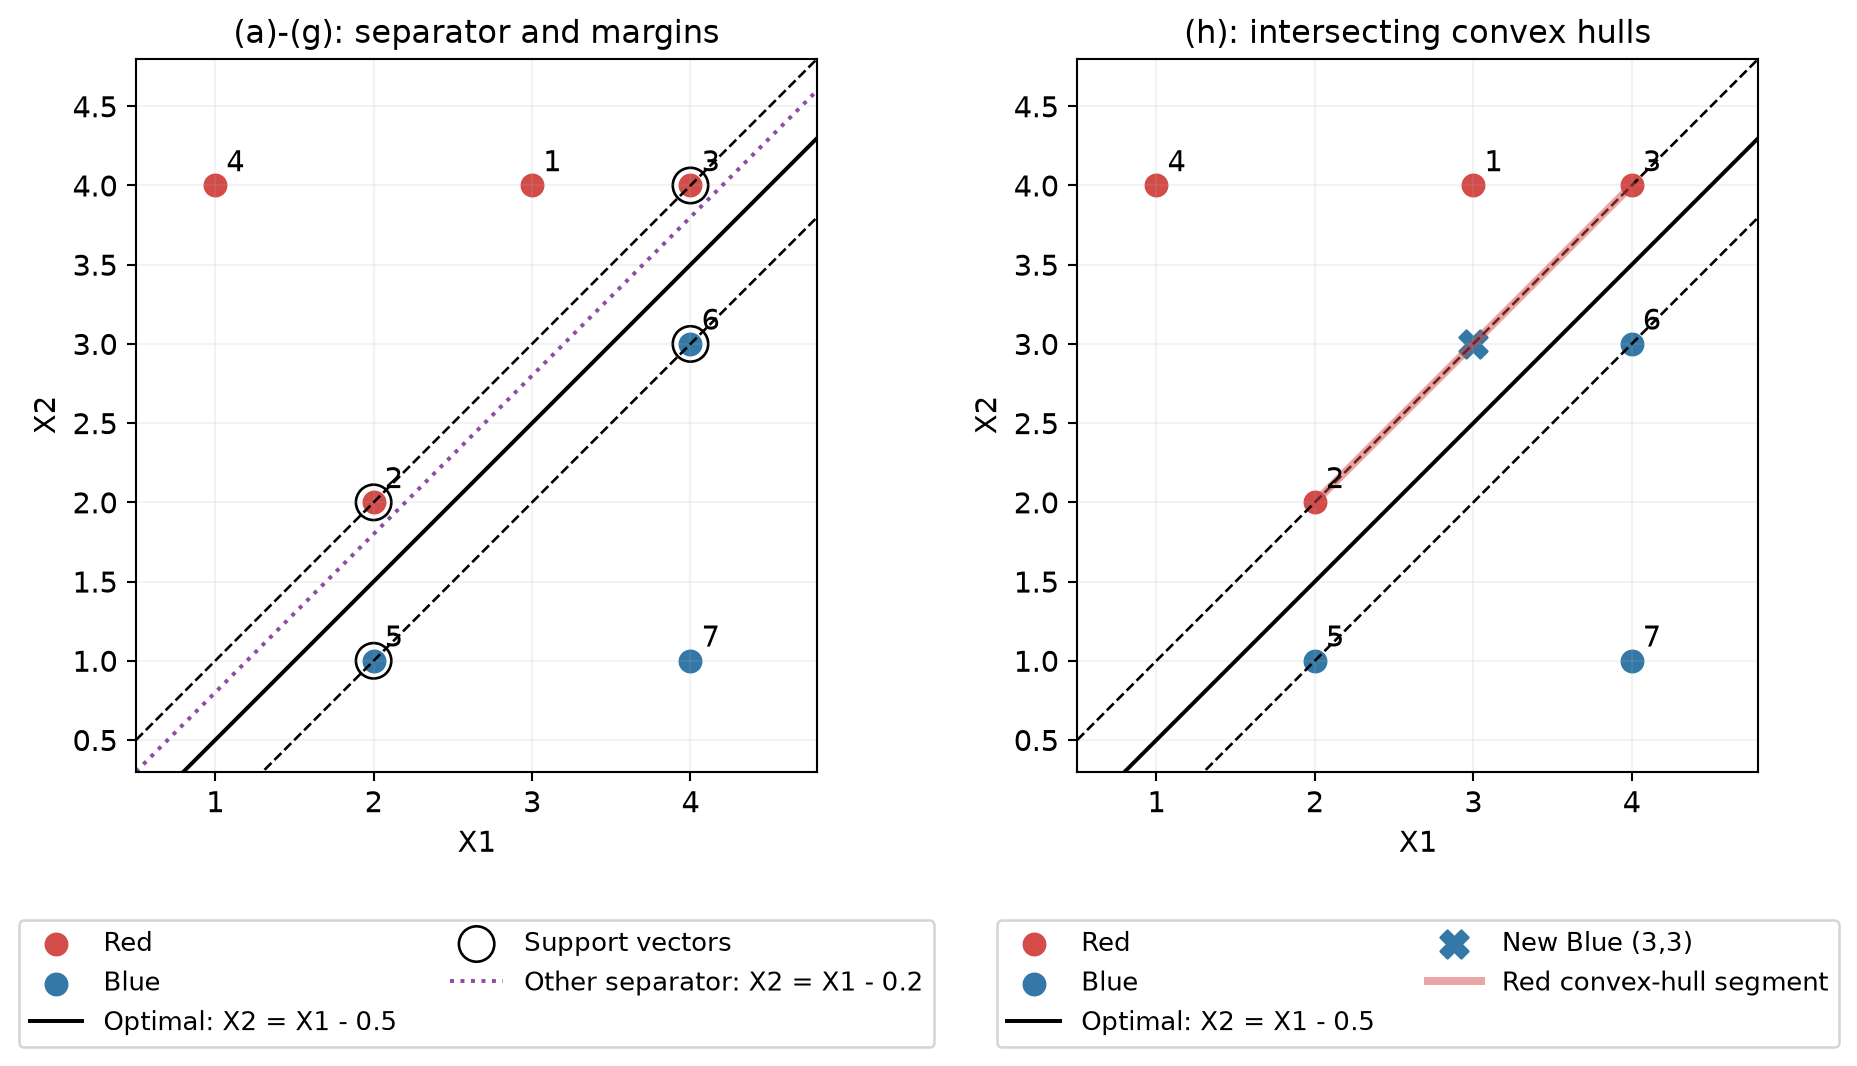

**(a)** Red observations are 1=(3,4), 2=(2,2), 3=(4,4), 4=(1,4); Blue observations are 5=(2,1), 6=(4,3), 7=(4,1).

**(b)** The optimal boundary is X2 = X1 - 0.5, or 0.5 - X1 + X2 = 0. The nearest Red and Blue points lie on X2 = X1 and X2 = X1 - 1. Their convex hulls are 1/sqrt(2) apart; the midpoint line attains half this distance, the largest possible margin.

**(c)** Classify Red if 0.5 - X1 + X2 > 0; otherwise classify Blue. Thus (beta0, beta1, beta2) = (0.5, -1, 1); a positive rescaling gives the same classifier.

**(d)** The geometric margin on each side is 0.5/sqrt(2) = 0.353553. The full width between supporting lines is 1/sqrt(2) = 0.707107. In canonical functional-margin units use (1, -2, 2), with support scores +1 or -1.

**(e)** Support vectors are observations 2, 3, 5 and 6, on the dashed supporting lines. An independent hard-margin SVM approximation verifies these points, coefficients (-2,2), and intercept 1.

**(f)** Observation 7 has score 0.5 - 4 + 1 = -2.5. A sufficiently small movement keeps it strictly beyond the Blue supporting line, leaving the active margin constraints and optimal boundary unchanged.

**(g)** The purple dotted separator X2 = X1 - 0.2 still separates every original point. Its closest distance is 0.2/sqrt(2), smaller than 0.5/sqrt(2), so it is not optimal.

**(h)** Add a Blue point at (3,3), the midpoint of Red observations 2=(2,2) and 3=(4,4). A linear functional positive at both Red endpoints is positive at their midpoint. The convex hulls intersect, so no hyperplane can strictly separate the classes.

In [24]:
show_answer_section(pages()[15])

In [25]:
show_answer_section(pages()[16])

## References, assumptions and reproducibility

[1] James, G., Witten, D., Hastie, T., and Tibshirani, R. An Introduction to Statistical Learning, with Applications in R, 2nd ed. (2021), corrected June 21, 2023; compared against first-edition seventh printing (2013). Author-provided downloads: https://www.statlearning.com/ . Second-edition download redirect: https://hastie.su.domains/ISLR2/ISLRv2_corrected_June_2023.pdf.download.html . Verified exercise locations and source-page images are retained locally.

[2] Scikit-learn, Imputation of missing values: https://scikit-learn.org/stable/modules/impute.html .

[3] Chen, C., Liaw, A., and Breiman, L. (2004). Using Random Forest to Learn Imbalanced Data. Technical Report 666, UC Berkeley. https://statistics.berkeley.edu/sites/default/files/tech-reports/666.pdf .

[4] Scikit-learn, RandomForestClassifier API (class_weight and probability prediction): https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html .

[5] XGBoost v3.4.1 parameter source: https://github.com/dmlc/xgboost/blob/v3.4.1/doc/parameter.rst ; Python API: https://xgboost.readthedocs.io/en/stable/python/python_api.html .

... (4 outputs left out)

### Reproducibility and scope

Python 3.12.8; numpy 2.5.4, pandas 3.1.1, scikit-learn 1.9.1, xgboost 3.4.1, imbalanced-learn 0.14.2, matplotlib 3.11.2, joblib 1.6.0. CPU-only execution on an 8-logical-CPU, 16 GiB machine. No GPU assumed. Five folds run sequentially, estimator threads = 4. Exact pins and saved environment metadata accompany this submission.

The self-contained notebook includes all implementation, answers and rendered outputs. Full mode freshly fits two forests, all 70 CV estimators, two selected final XGB models and one strictly-positive-alpha supplement. Quick mode rejects mismatched data/code/parameters/versions/file hashes, then verifies all five cached final models and saved CV summaries without fitting. Separately attached notebook/source page counts are not added to the formal PDF limit.

Question 6 contains all four completed Extra Practice exercises, with individually verified edition references, computations and diagrams, integrated before these references. The remaining interpretation issue is whether the instructor intended a genuine logistic model tree rather than the standard XGBoost implementation documented in 1(e). There are no unresolved formal exercise statements.

## 1(e). Supplementary comparison restricted to alpha > 0

The unrestricted AP search selected alpha=0; zero means no L1 penalty. Restricting the same plain-search CV table to strictly positive candidates and applying the same maximum-mean-AP/smaller-alpha tie rule selects alpha=0.01. This does not replace the original optimum, use official-test scores for selection, or resolve the node-level model-tree ambiguity.

Mean CV AP=0.887273; CV error=0.005683. The separate no-SMOTE model uses all 60,000 original training rows, all 170 predictors and otherwise unchanged settings.

| Split | Error | ROC-AUC | AP | Precision | Recall | F1 |
| --- | --- | --- | --- | --- | --- | --- |
| Train | 0.00113 | 0.99973 | 0.99256 | 0.99680 | 0.93500 | 0.96491 |
| Test | 0.00613 | 0.99606 | 0.93208 | 0.95710 | 0.77333 | 0.85546 |

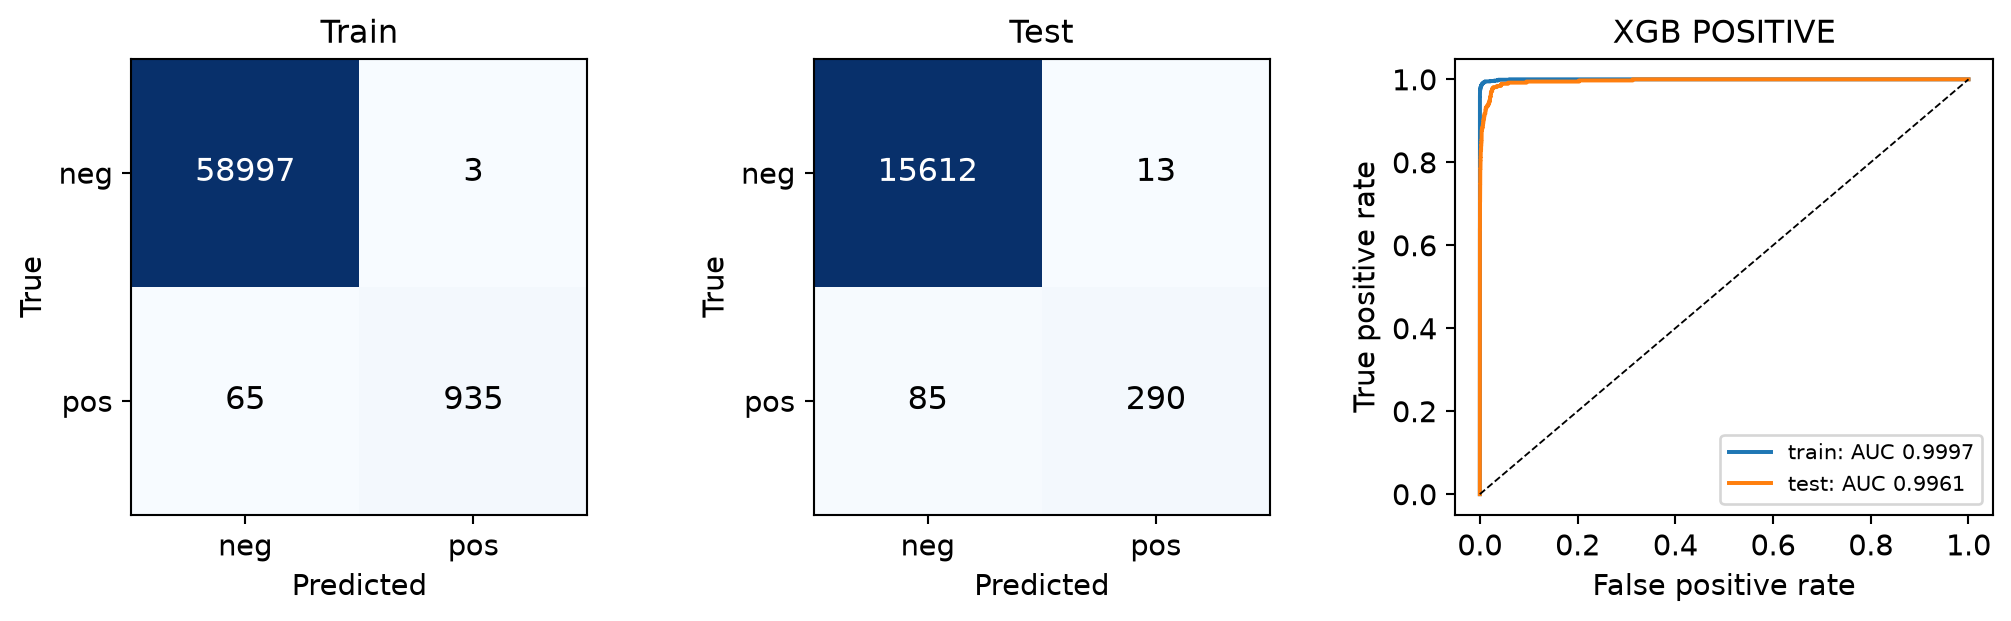

Train CM=[[58997, 3], [65, 935]]; test CM=[[15612, 13], [85, 290]], true rows/predicted columns [neg,pos]. Relative to alpha=0, test error changes by -0.000250, AUC by -0.000167. This is a labeled supplementary comparison, not test-driven retuning. Stored fit/evaluation time for this model is 3.70s; MODE identifies fresh fitting versus cached verification.

In [26]:
show_answer_section(positive_answer())

## Question 6 — Extra Practice

All four statements were checked separately in the two local R editions. ISLR 6.8.4 denotes first-edition ridge (second-edition equivalent: 6.6.4); the other three references agree across editions, with tree Figure 8.12 becoming 8.14. Each full answer below states the verified source. No textbook file is needed to execute these inline solutions.

## Question 6 - Extra Practice: ISLR 5.4.2

Source verified separately: first edition, seventh printing, Section 5.4 Exercise 2, printed pp.197-198 (PDF pp.212-213). The second-edition 5.4.2, pp.219-220, has the same eight subparts. The task concerns inclusion of one fixed original observation j in n independent draws with replacement.

**(a)** The first draw misses observation j with probability (n-1)/n = 1 - 1/n: exactly n-1 of the n equally likely indices differ from j. **(b)** The second draw has the same probability, 1 - 1/n; replacement restores the same sampling population.

**(c)** All n draws are independent, so the probability that j is absent is the product of n identical miss probabilities. Taking the complement gives its inclusion probability:

$$
P(j\notin B)=(1-1/n)^n,\qquad P(j\in B)=1-(1-1/n)^n
$$

| Subpart | n | Exact inclusion probability |
| --- | --- | --- |
| (d) | 5 | 0.6723200000 |
| (e) | 100 | 0.6339676587 |
| (f) | 10000 | 0.6321389536 |

**(g)** The code evaluates every integer n from 1 through 100,000 (the right panel uses a logarithmic x-axis). Inclusion decreases from 1 toward 1 - exp(-1) = 0.6321205588, approaching from above. Equivalently, about 36.8% of original observations are absent from a large bootstrap sample. The sample still has n draws; repeated indices explain the difference.

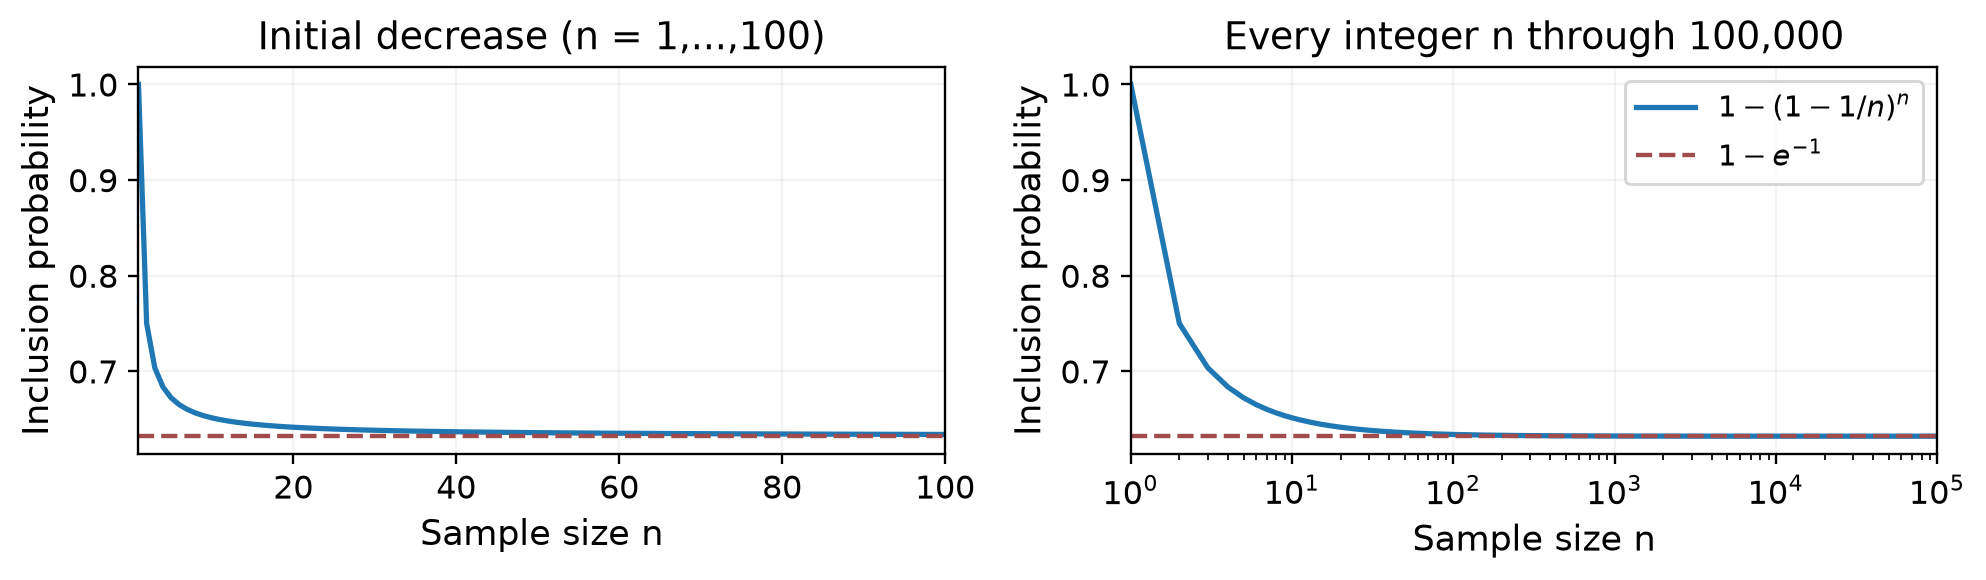

**(h)** With seed 552, we actually generated 10,000 bootstrap samples of size 100, and checked whether index j = 4 occurs. It appeared in 6,238 samples: empirical probability 0.6238, versus exact 0.633968. The Monte Carlo standard error is sqrt(p(1-p)/10000) = 0.00482; the difference is -2.11 standard errors. This is consistent with simulation noise. Sampling uses NumPy's generator, so the seeded realization need not equal R's.

In [27]:
show_answer_section(extra_pages()[0])

## Question 6 - Extra Practice: ISLR 6.8.4

Source: first edition, seventh printing, Section 6.8 Exercise 4, printed pp.260-261 (PDF pp.275-276). This is the ridge-penalty question. The equivalent second-edition exercise is 6.6.4, not 6.8.4. An unpenalized intercept is understood; lambda increases from zero.

$$
\min_{\beta_0,\beta}\ R(\beta)+\lambda P(\beta),\quad R=\sum_i(y_i-\beta_0-x_i^T\beta)^2,\quad P=\sum_j\beta_j^2
$$

**(a) Training RSS: iii, steadily increases (nondecreasing).** Let R1,P1 and R2,P2 be the residual and penalty values at minimizers for 0 <= lambda1 < lambda2. Optimality gives R1 + lambda1 P1 <= R2 + lambda1 P2 and R2 + lambda2 P2 <= R1 + lambda2 P1. Adding implies P2 <= P1; substituting yields R2 - R1 >= lambda1(P1 - P2) >= 0. Equality is possible, for example when all fitted slopes are zero.

**(b) Test RSS: ii, typically decreases initially and then increases.** Moderate shrinkage can reduce variance enough to improve prediction; excessive shrinkage causes underfitting. A U shape is the intended bias-variance pattern, not a theorem for every test set or underlying signal.

**(c) Variance: iv, decreases.** For centered X = U D V-transpose with fixed design and homoskedastic noise, a ridge coefficient along right singular direction k has variance sigma squared times d_k squared / (d_k squared + lambda) squared. Each such component is nonincreasing; the unpenalized intercept contributes a constant term.

$$
\operatorname{Var}(\hat\beta_{\lambda,k})=\frac{\sigma^2 d_k^2}{(d_k^2+\lambda)^2},\qquad \operatorname{Bias}_k=-\frac{\lambda}{d_k^2+\lambda}\beta_k
$$

**(d) Squared bias: iii, typically increases.** Larger lambda shrinks identifiable slope directions farther toward zero, increasing shrinkage bias. In the orthogonal coefficient norm (or isotropic test average), squared directional biases increase. Arbitrary pointwise squared prediction bias need not be monotone because directional contributions can cancel.

**(e) Irreducible error: v, remains constant.** Changing regularization cannot change the response noise variance.

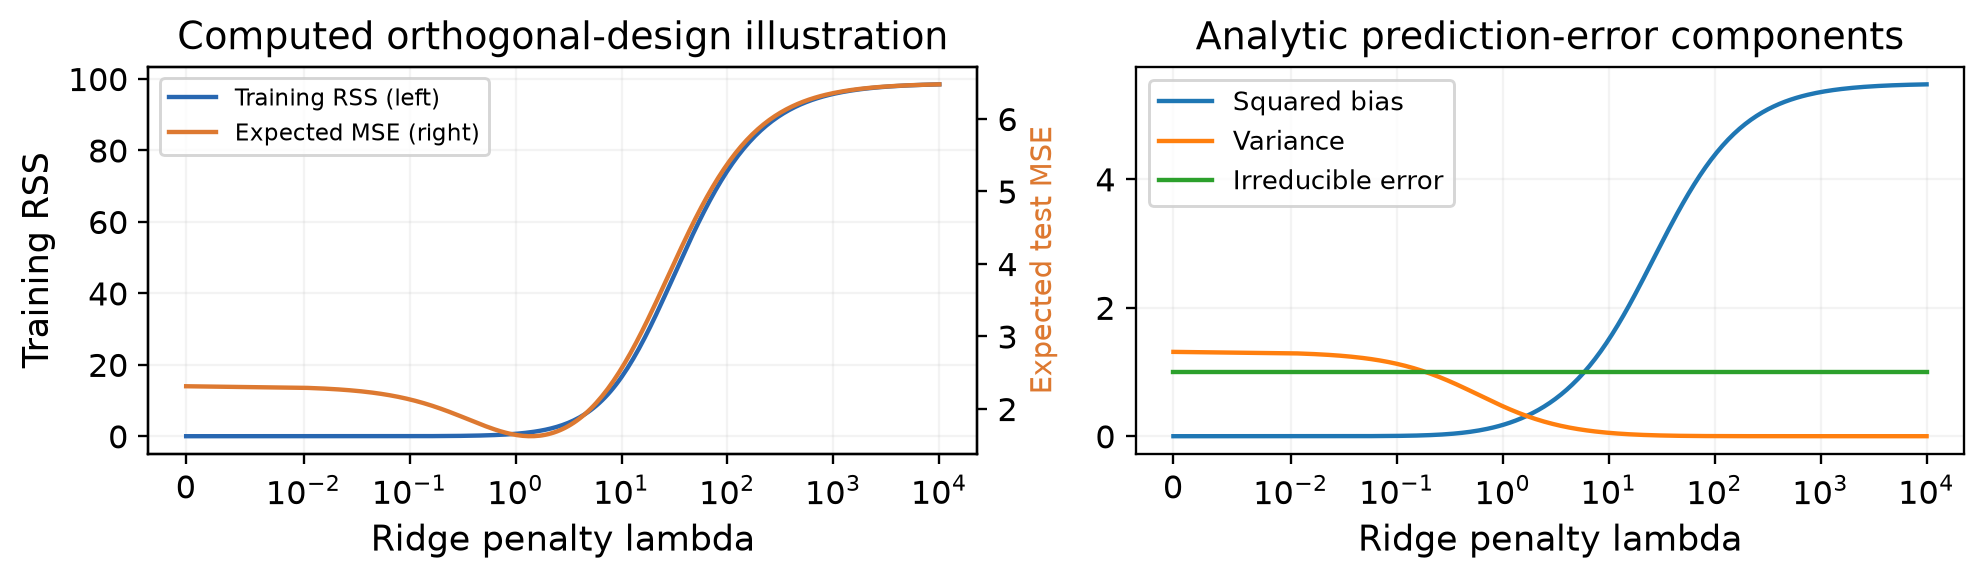

Computed illustration: X = diag(4,2,1), true slopes (2,-1,0.7), known zero intercept, unit Gaussian noise, seed 552. Training RSS comes from the realized response; expected test MSE is the analytic sum of squared bias, variance and noise for isotropic test covariates. These are not APS results or held-out empirical estimates. Monotonicity checks passed.

In [28]:
show_answer_section(extra_pages()[1])

## Question 6 - Extra Practice: ISLR 8.4.4

Source: first edition, seventh printing, Section 8.4 Exercise 4, printed pp.332-333 (PDF pp.347-348), Figure 8.12. Checked independently against second-edition 8.4.4, pp.361-362, Figure 8.14: both partitions and all leaf values agree. The task asks (a) for a tree from the left partition and (b) for a partition from the right tree.

**(a)** A valid first split is X1 < 1 (false leaf: 5). On the true branch split X2 < 1 (false leaf: 15). In the lower-left part split X1 < 0 (true leaf: 3). On its false branch split X2 < 0, yielding 10 if true and 0 otherwise. The picture is a redrawing of the source regions and our corresponding tree; the finite plotting window does not bound the actual outer regions.

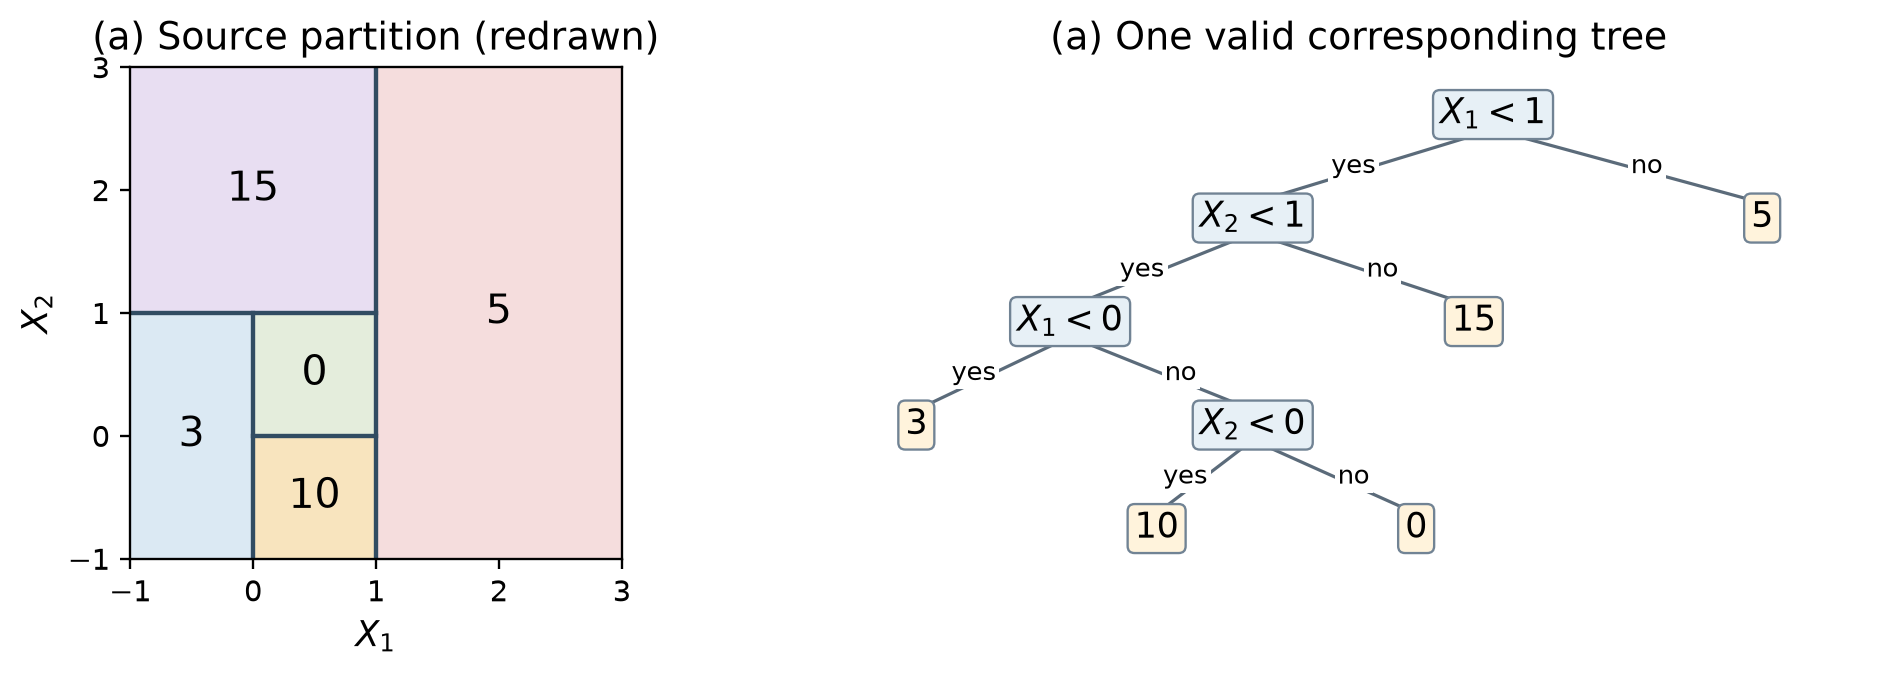

**(b)** The source tree first splits horizontally at X2 = 1, splits the lower half vertically at X1 = 1, then splits the upper half horizontally at X2 = 2 and the middle strip vertically at X1 = 0. The resulting five regions and their means are:

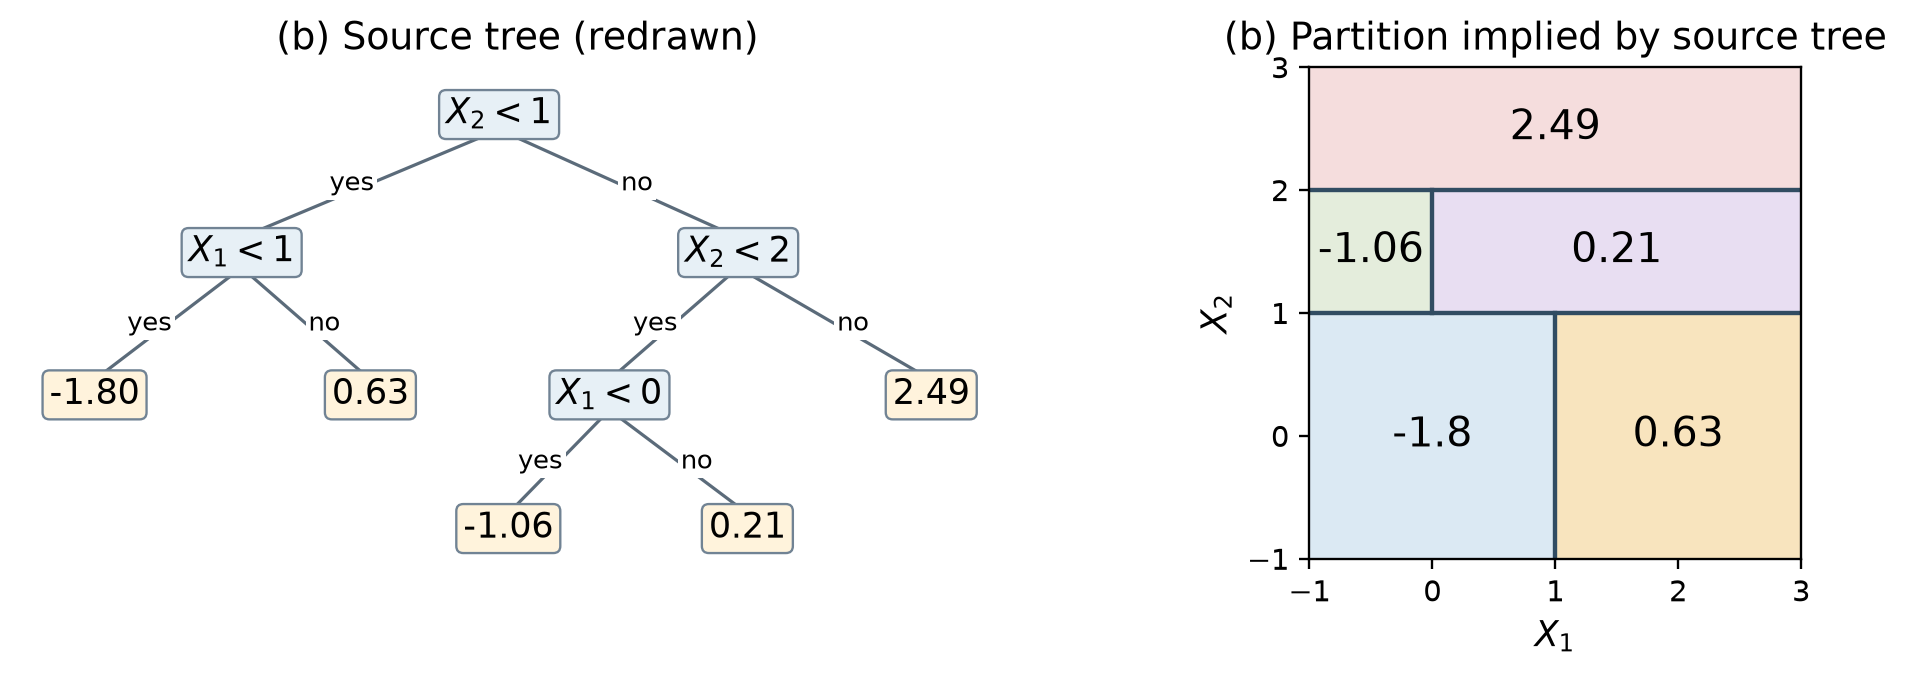

| Region conditions | Mean Y |
| --- | --- |
| X2 < 1 and X1 < 1 | -1.80 |
| X2 < 1 and X1 >= 1 | 0.63 |
| 1 <= X2 < 2 and X1 < 0 | -1.06 |
| 1 <= X2 < 2 and X1 >= 0 | 0.21 |
| X2 >= 2 | 2.49 |

Boundary convention: a less-than condition sends equality to the false branch. Independent tree traversal and piecewise region evaluation agree on 6,561 grid points, including the cut lines. Each diagram has five leaves/regions.

In [29]:
show_answer_section(extra_pages()[2])

## Question 6 - Extra Practice: ISLR 9.7.2

Source: first edition, seventh printing, Section 9.7 Exercise 2, printed p.368 (PDF p.383). The second-edition 9.7.2, p.398, has the same four subparts, curve, inequalities and query points.

**(a)** The curve (1 + X1) squared + (2 - X2) squared = 4 is a circle centered at (-1,2) with radius 2. Its horizontal extremes are (-3,2) and (1,2), and its vertical extremes are (-1,0) and (-1,4).

**(b)** The strict inequality > 4 denotes the exterior; <= 4 denotes the closed disk, including the boundary. The figure shades the exterior Blue and the closed disk Red, matching the rule in (c).

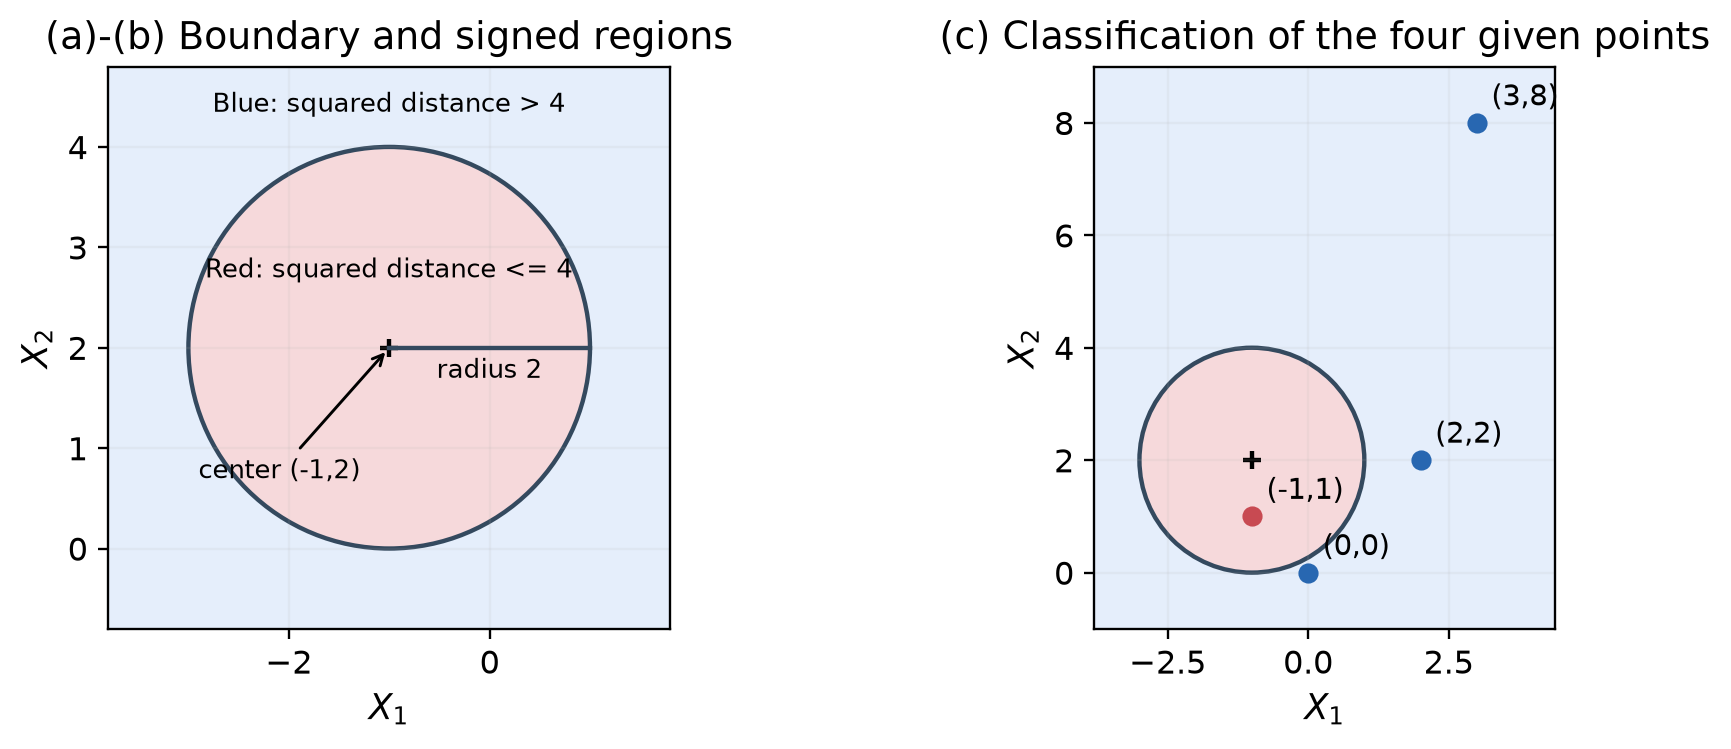

### (c) Classify all four specified observations

| Point (X1,X2) | Squared distance from (-1,2) | Class |
| --- | --- | --- |
| (0,0) | 5 | Blue |
| (-1,1) | 1 | Red |
| (2,2) | 9 | Blue |
| (3,8) | 52 | Blue |

### (d) A linear boundary in the expanded feature space

$$
(1+X_1)^2+(2-X_2)^2-4=X_1^2+X_2^2+2X_1-4X_2+1
$$

Let z = (X1, X1 squared, X2, X2 squared). The same boundary is 1 + 2 z1 + z2 - 4 z3 + z4 = 0, an affine hyperplane with intercept 1 and coefficients (2,1,-4,1). Predict Blue if this score is positive and Red otherwise. Thus the boundary is nonlinear in the original two inputs but linear in these four transformed coordinates. The computed expanded scores (1,-3,5,48) agree exactly with squared distance minus 4.

In [30]:
show_answer_section(extra_pages()[3])

## Detailed outputs, mathematical checks and execution scope

,mean,sample_sd_ddof1,cv,missing_fraction,zero_mean,all_missing
aa_000,5.933650e+04,1.454301e+05,2.450938,0.000000,False,False
ab_000,1.625000e-01,1.687318e+00,10.383494,0.772150,False,False
ac_000,3.362258e+08,7.767625e+08,2.310241,0.055583,False,False
ad_000,1.434383e+05,3.504525e+07,244.322816,0.247683,False,False
ae_000,6.535000e+00,1.581479e+02,24.200137,0.041667,False,False
...,...,...,...,...,...,...
ee_007,3.428586e+05,1.718666e+06,5.012754,0.011183,False,False
ee_008,1.372212e+05,4.472145e+05,3.259079,0.011183,False,False
ee_009,8.295099e+03,4.721249e+04,5.691612,0.011183,False,False
ef_000,8.646667e-02,4.268570e+00,49.366659,0.045400,False,False


,aa_000,ab_000,ac_000,ad_000,ae_000,af_000,ag_000,ag_001,ag_002,ag_003,...,ee_002,ee_003,ee_004,ee_005,ee_006,ee_007,ee_008,ee_009,ef_000,eg_000
aa_000,1.000000,0.014085,-0.063876,-0.001590,0.043095,0.062855,0.018549,0.142645,0.284797,0.493749,...,0.732449,0.736321,0.715000,0.724399,0.724102,0.603888,0.469836,0.247149,0.012409,0.024387
ab_000,0.014085,1.000000,-0.002128,-0.000394,0.037572,0.053293,-0.000179,0.007839,0.023144,0.037081,...,-0.001159,0.013330,0.002849,0.004470,0.015881,0.008520,-0.025599,-0.016247,0.056271,0.106360
ac_000,-0.063876,-0.002128,1.000000,-0.001765,-0.004250,-0.009480,0.017155,-0.007334,-0.022708,-0.047927,...,-0.046891,-0.040157,-0.039319,-0.039648,-0.047105,-0.048648,-0.003714,0.013764,-0.006262,0.014747
ad_000,-0.001590,-0.000394,-0.001765,1.000000,-0.000168,-0.000209,-0.000043,-0.000115,-0.000230,-0.000469,...,-0.001527,-0.001529,-0.001494,-0.001239,-0.001201,-0.000801,-0.001235,-0.000716,-0.000082,-0.000096
ae_000,0.043095,0.037572,-0.004250,-0.000168,1.000000,0.823123,-0.000445,-0.001072,0.002204,0.022460,...,0.010184,0.016818,0.011363,0.026130,0.060474,0.035503,-0.009632,-0.007218,0.070869,0.041725
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
ee_007,0.603888,0.008520,-0.048648,-0.000801,0.035503,0.047858,0.000329,0.044185,0.182701,0.505149,...,0.455031,0.447002,0.437894,0.380114,0.546124,1.000000,0.225378,0.061805,-0.001733,0.000398
ee_008,0.469836,-0.025599,-0.003714,-0.001235,-0.009632,-0.012347,-0.000787,0.004927,0.009562,0.021448,...,0.454112,0.481672,0.459834,0.407250,0.374332,0.225378,1.000000,0.710167,-0.005963,-0.002842
ee_009,0.247149,-0.016247,0.013764,-0.000716,-0.007218,-0.008996,-0.001209,-0.004274,-0.009410,-0.019093,...,0.228527,0.239576,0.224931,0.190958,0.164162,0.061805,0.710167,1.000000,-0.003439,-0.000971
ef_000,0.012409,0.056271,-0.006262,-0.000082,0.070869,0.106312,-0.000078,0.001793,0.006870,0.012996,...,0.003657,0.011816,0.003236,0.032363,0.004613,-0.001733,-0.005963,-0.003439,1.000000,0.282201


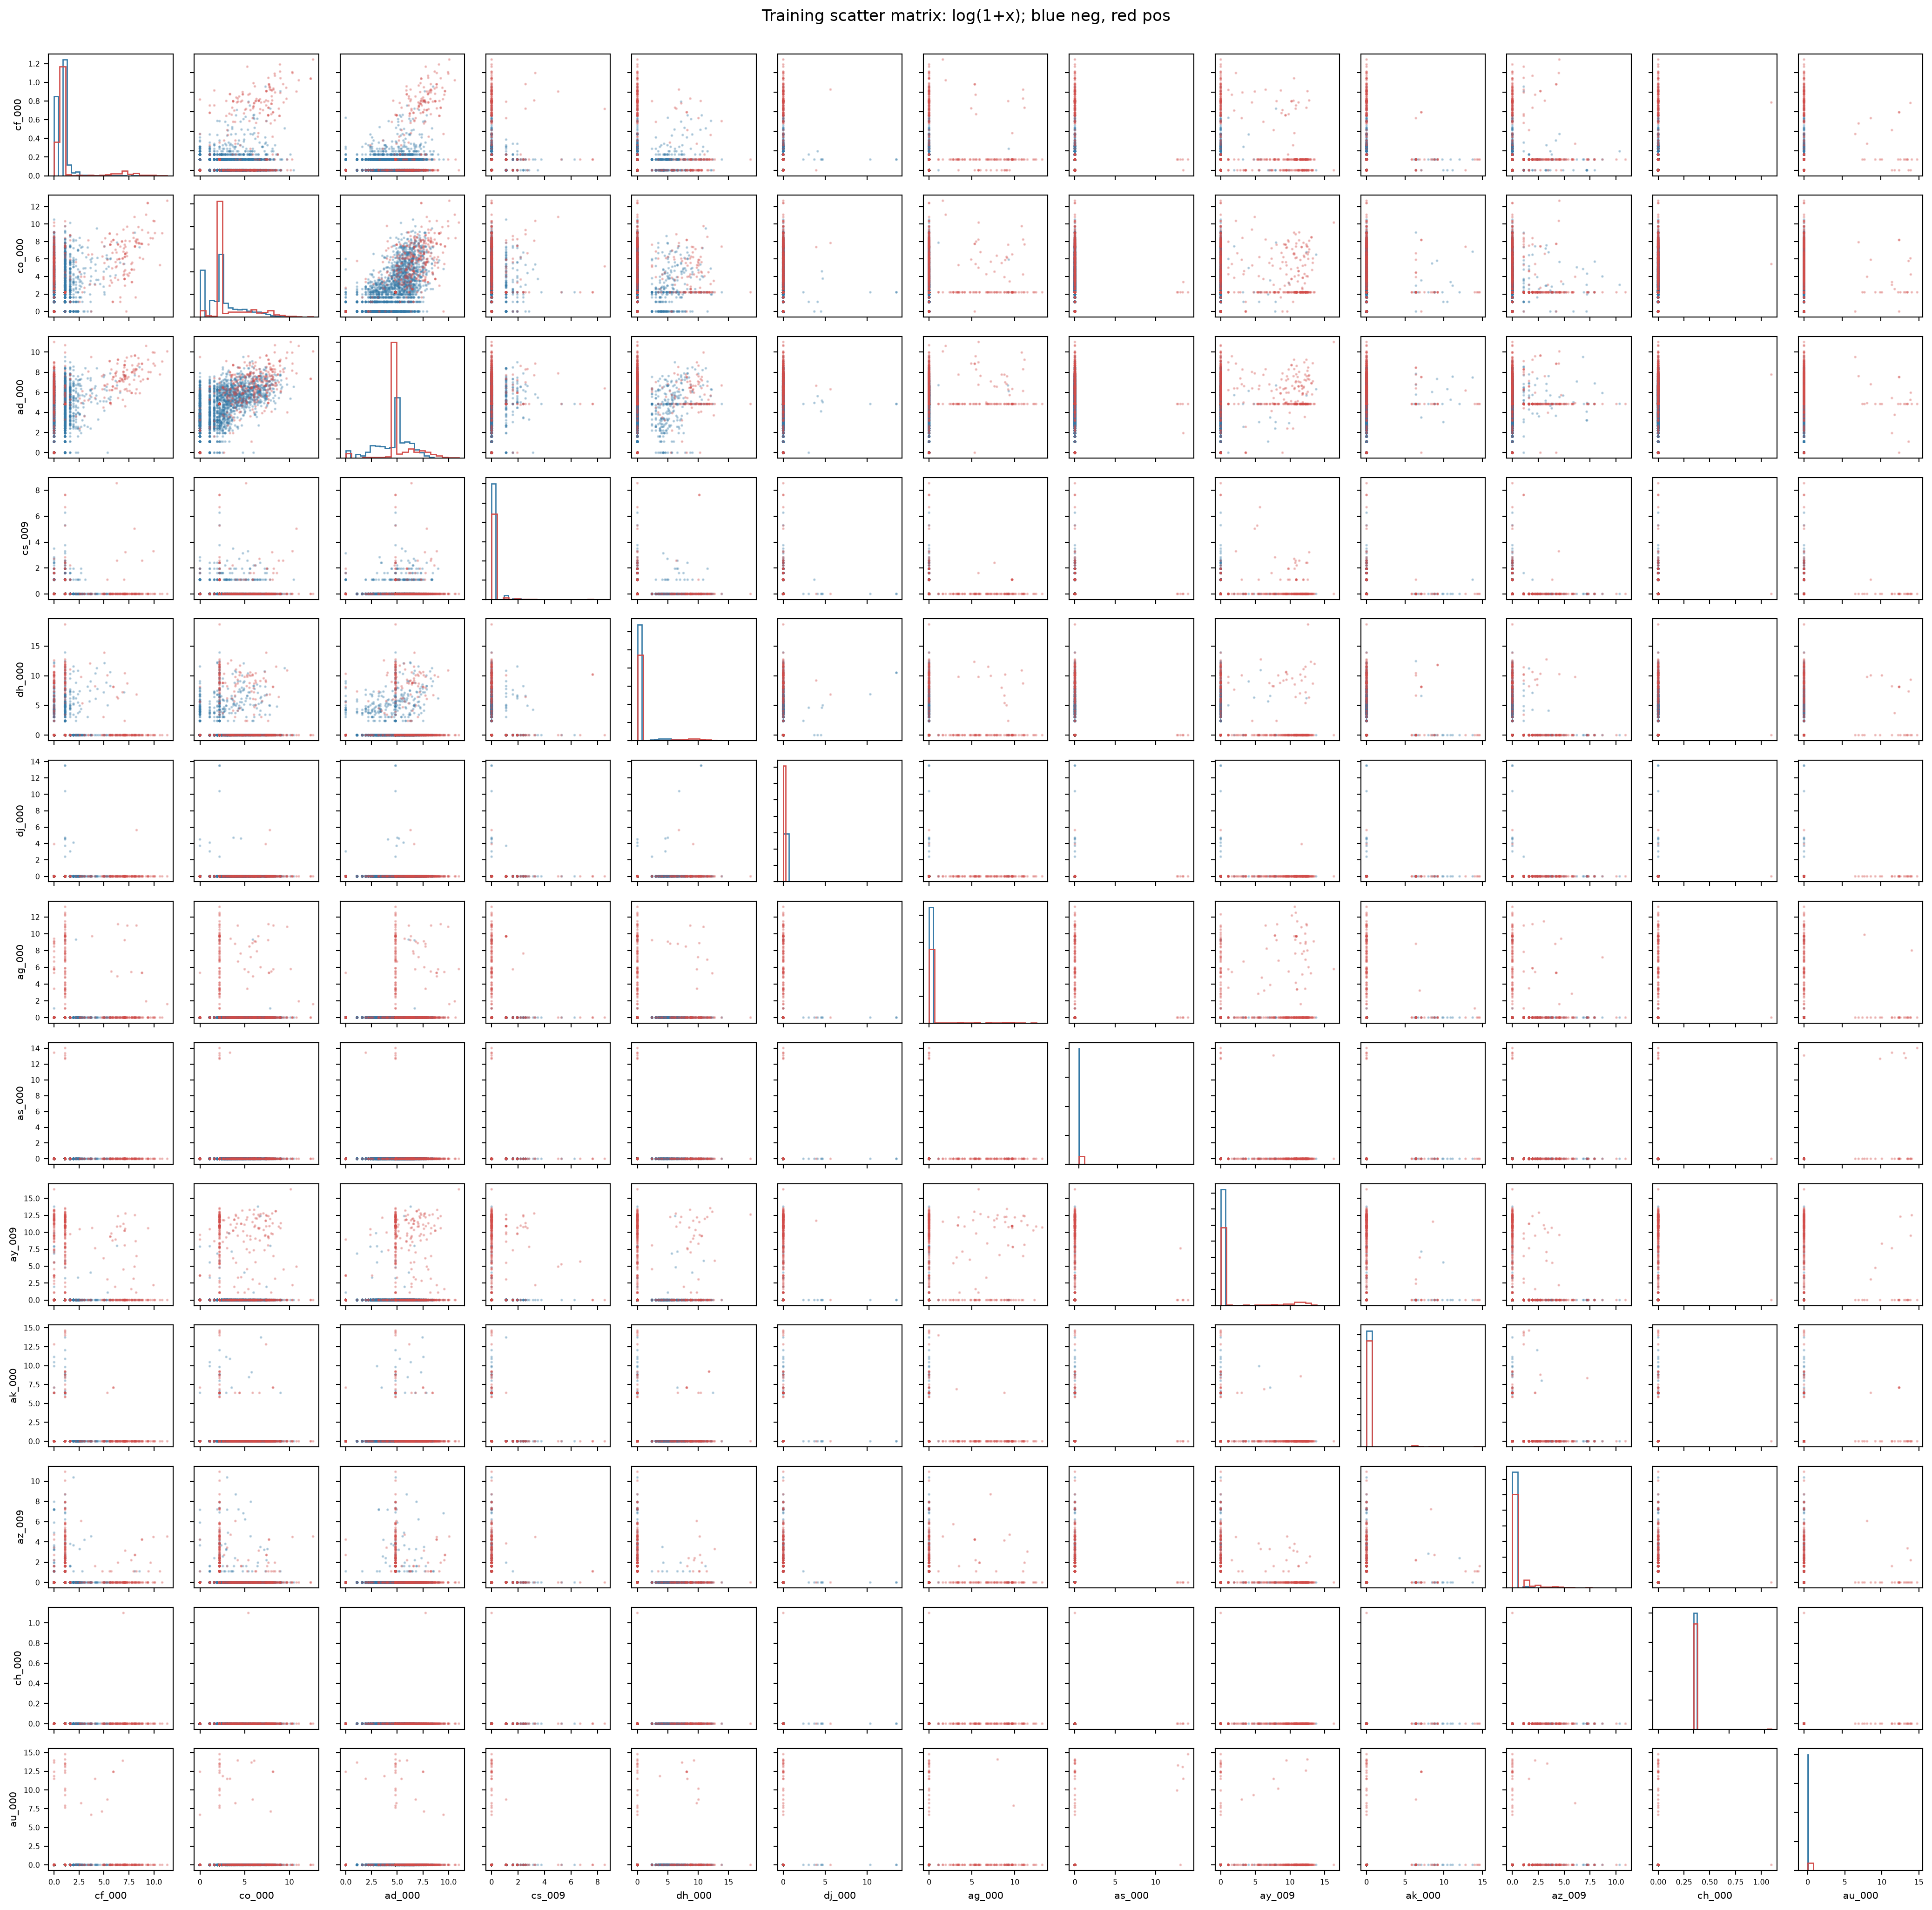

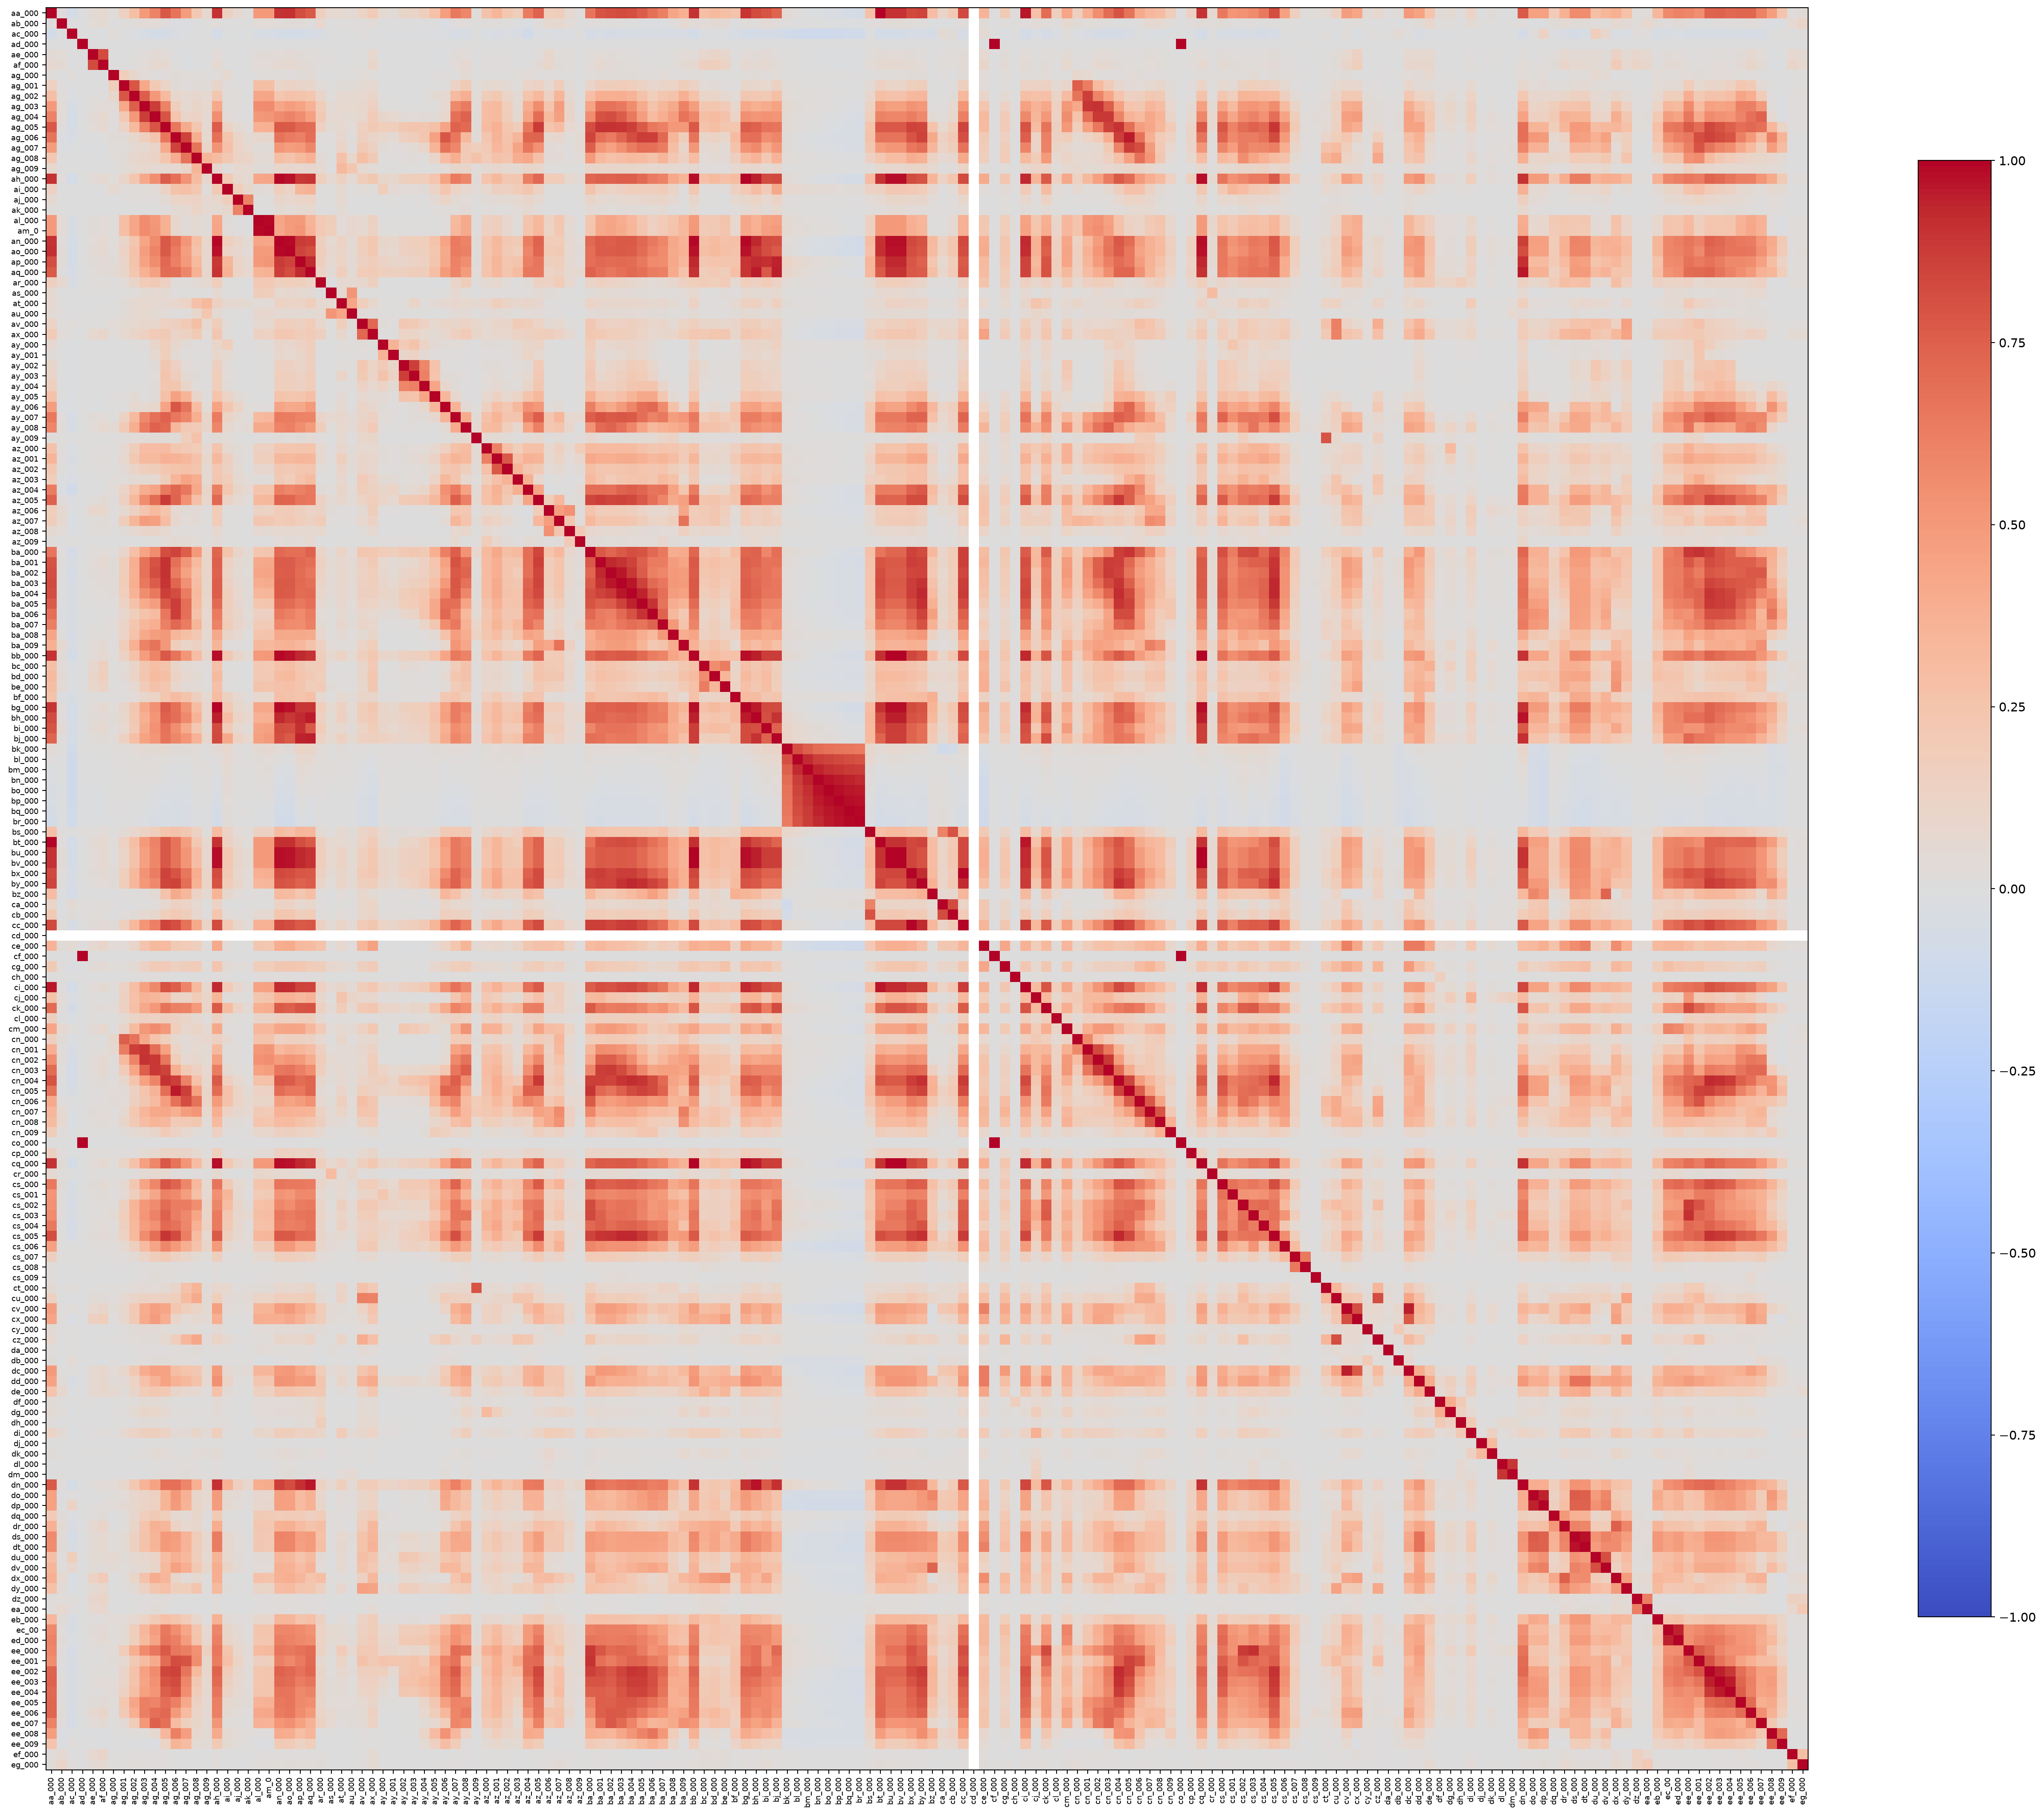

xgb_plain all 35 fold scores (fresh in full, stored in quick), mode: quick


,alpha,fold,n,error,auc,average_precision,precision,recall,f1,seconds,original_fold_n,resampled_fold_n
0,0.000,1,12000,0.006000,0.991012,0.890494,0.921053,0.700,0.795455,5.310763,48000,48000
1,0.000,2,12000,0.005083,0.991162,0.895974,0.897143,0.785,0.837333,4.852167,48000,48000
2,0.000,3,12000,0.005583,0.991226,0.903891,0.888889,0.760,0.819407,4.833980,48000,48000
3,0.000,4,12000,0.006333,0.987739,0.868021,0.878049,0.720,0.791209,4.834743,48000,48000
4,0.000,5,12000,0.005083,0.985658,0.879619,0.931677,0.750,0.831025,4.861862,48000,48000
5,0.001,1,12000,0.006000,0.990675,0.886430,0.926667,0.695,0.794286,5.037336,48000,48000
6,0.001,2,12000,0.005417,0.991623,0.895651,0.881356,0.780,0.827586,4.839964,48000,48000
7,0.001,3,12000,0.005833,0.989659,0.898145,0.886905,0.745,0.809783,4.827056,48000,48000
8,0.001,4,12000,0.006500,0.987976,0.868458,0.871951,0.715,0.785714,4.884520,48000,48000
9,0.001,5,12000,0.005083,0.985733,0.879697,0.931677,0.750,0.831025,5.085357,48000,48000


xgb_smote all 35 fold scores (fresh in full, stored in quick), mode: quick


,alpha,fold,n,error,auc,average_precision,precision,recall,f1,seconds,original_fold_n,resampled_fold_n
0,0.000,1,12000,0.008750,0.988235,0.852919,0.693878,0.850,0.764045,8.504672,48000,94400
1,0.000,2,12000,0.010083,0.986858,0.888324,0.642599,0.890,0.746331,7.748576,48000,94400
2,0.000,3,12000,0.009917,0.992474,0.857822,0.651685,0.870,0.745182,7.702023,48000,94400
3,0.000,4,12000,0.010000,0.991200,0.809784,0.662602,0.815,0.730942,8.161236,48000,94400
4,0.000,5,12000,0.010083,0.980995,0.828638,0.661224,0.810,0.728090,7.947218,48000,94400
5,0.001,1,12000,0.008750,0.988235,0.852921,0.693878,0.850,0.764045,8.707435,48000,94400
6,0.001,2,12000,0.010083,0.986858,0.888324,0.642599,0.890,0.746331,7.940178,48000,94400
7,0.001,3,12000,0.009833,0.992691,0.858410,0.655303,0.865,0.745690,7.908914,48000,94400
8,0.001,4,12000,0.010000,0.991200,0.809772,0.662602,0.815,0.730942,8.184877,48000,94400
9,0.001,5,12000,0.010083,0.980995,0.828638,0.661224,0.810,0.728090,8.248603,48000,94400


Q3 ridge: (np.float64(0.6666666666666666), np.float64(0.6666666666666666)) lasso sum: 1.5 objective: 3.5
Q4 votes / mean: 6 0.45
Q5 independent geometry verification: {'coef': [[-1.9999999999301519, 1.999999999930151]], 'intercept': [0.9999999999650773], 'support_observations_1based': [5, 6, 2, 3], 'margin': 0.35355339060562135}
Final execution status: quick | original five models trained this run: False
Quick mode: no fitting. Validated cached final models re-evaluated; stored 70 CV fold scores summarized and alpha selection checked, not refitted. All five final-model train/test/sensitivity predictions, metrics verified; legacy unmasked OOB arithmetic only, not coverage validation.
Supplemental forest trained this run: False
Coverage-aware masks and per-class counts supersede legacy unmasked OOB claims.
Full training was NOT executed. Saved CV estimators are NOT refitted.
Outputs: results/notebook_runs/quick_20261109T041949_112615Z


In [31]:
display(feature_table)
display(pd.read_csv(R / "correlation.csv", index_col=0))
display(Image(filename=str(F / "scatter_all13.png"), width=1500))
display(Image(filename=str(F / "correlation_all_labels.png"), width=1500))
for name in ["xgb_plain", "xgb_smote"]:
    print(name, "all 35 fold scores (fresh in full, stored in quick), mode:", MODE)
    display(pd.read_csv(R / f"{name}_cv_folds.csv"))
x = np.array([1., -1.]); response = np.array([2., -2.]); penalty = 2.
a = x @ x; b = x @ response
ridge = b / (2*a + penalty)
tstar = np.sign(b)*max(abs(b)-penalty/2, 0)/a
objectives = [np.sum((response-x*tstar)**2) + penalty*(abs(w*tstar)+abs((1-w)*tstar))
              for w in np.linspace(0, 1, 11)]
assert np.ptp(objectives) < 1e-12
print("Q3 ridge:", (ridge,ridge), "lasso sum:", tstar, "objective:", objectives[0])
p = np.array([.1,.15,.2,.2,.55,.6,.6,.65,.7,.75])
assert (p > .5).sum() == 6 and np.isclose(p.mean(), .45)
print("Q4 votes / mean:", (p>.5).sum(), p.mean())
print("Q5 independent geometry verification:", read_json(R / "q5_verification.json"))
assert extra_results["all_passed"] and validation["all_passed"]
print("Final execution status:", MODE, "| original five models trained this run:", MODE == "full")
print(validation["validation_scope"])
print("Supplemental forest trained this run:", OOB_MODE == "fit_supplement")
print(validation["oob_scope"])
if MODE == "quick":
    print("Full training was NOT executed. Saved CV estimators are NOT refitted.")
else:
    print("Full training executed: both forests, all 70 CV fits, both selected final XGB models, the positive-alpha supplement and OOB-safe supplemental forest.")
print("Outputs:", RUN_ROOT)
